# Phase 4 - Exploratory data analysis: playlist, song and artist behaviour

**Project:** United States Top 50 Playlist Performance and Song Popularity Trend Analysis (Atlantic Recording Corporation case)

**What this notebook does.** It looks at the cleaned chart (27,750 song-days, 944 songs, 283 artists, 18 May 2024 to 27 Nov 2025) from five sides, in the order of the project brief: the ranking of the playlist, the life of single songs, the artists, the popularity score, and the content of the songs. It ends with one picture of how all song measures relate to each other and with a register of findings that Phase 5 will test.

**Before you run it.** Phases 1 to 3 must have run, so that `data/processed/` holds the Parquet tables. Then choose *Run All*. It takes about a minute, writes 32 charts to `reports/figures/p4_*.png`, and writes two small files to `reports/`: `p4_facts.json` (every number quoted in the text) and `p4_eda_findings.csv` (the findings register).

**How to read it.** Every code cell has a short plain-English explanation above it in five parts: *what this code is*, *why we need it*, *what will happen*, *expected outcome* and *motive*. Every chart has a *What to notice* note below it. The numbers in those notes are not typed by hand: the code cell stores each number it computes in a container called `FACTS`, and the sentences are written from it, so a sentence and its chart cannot disagree.

**Ground rules used throughout.**

- *Days on the chart* are counted in snapshot days (the file has 555 snapshots over 559 calendar days; 4 calendar days have no snapshot).
- *Chart points* of a song-day = 51 minus the position, so a song at number one earns 50 and a song at number 50 earns 1. They let us add up "how much of the chart" a song or an artist held.
- An *artist* means the first-named (primary) artist of a song, so that every song counts for exactly one artist.
- A *run* is a stretch of consecutive days on the chart. Runs that are cut off by the first or last day of the file are flagged and left out wherever length matters.
- Everything here is descriptive. When two groups differ, we say by how much; whether the difference is bigger than chance is decided with proper tests in Phase 5.

| Brief block | Section | Figures |
|---|---|---|
| KPIs | 2 | 1 |
| Playlist ranking (rank distribution, movement, entry versus exit, risers and decliners) | 3 | 2-10 |
| Song-level analysis (longest presence, highest popularity, peak rank versus longevity) | 4 | 11-14 |
| Artist analysis (songs per artist, days present, dominance over time) | 5 | 15-20 |
| Popularity analytics (popularity versus rank, distributions, stability versus volatility) | 6 | 21-26 |
| Content attributes (explicit, single versus album, duration, album size) | 7 | 27-31 |
| One-page overview of relationships | 8 | 32 |
| Findings register and hand-off to Phase 5 | 9 | - |

## Section 1 - Setup and loading the data

Two cells. The first loads the tools, the second loads the five tables that Phase 3 wrote to `data/processed/`. Nothing is
cleaned or changed here: all cleaning decisions (for example the repaired popularity zeros) were made in Phase 2 and are
already inside the tables.

**What this code is.** The import cell. It loads the Python libraries (pandas for tables, numpy for numbers, matplotlib for charts, scipy for statistics) and our own Phase 4 helper modules from `src/eda`: `style` (colours and fonts), `plots` (chart building blocks), `concentration` (HHI, Gini and shares), `ranking` (chart runs and position transitions) and `findings` (the facts container and the findings register).

**Why we need it.** Everything below uses these names. The logic that matters (how a run is found, how a Gini is calculated) lives in `src/eda` and is covered by automated tests, so the notebook stays short and the formulas stay checked. The two path lines make `from src...` work whether Jupyter was started in the project folder or in the `notebooks` folder.

**What will happen.** Python imports the libraries, switches on the project look (`apply_style`: font, colours, hairline grid), and creates two empty containers: `FACTS`, where every number that appears in a sentence is stored once, and `FINDINGS`, the list of findings we will fill at the end. It then prints the library versions and the project folder.

**Expected outcome.** Three or four printed lines (pandas version, numpy version, project path) and no chart. If a line fails with `ModuleNotFoundError`, run `pip install -r requirements.txt` in the project folder and restart the kernel.

**Motive.** One setup, one look, one place for the numbers. From here to the end of the notebook no number in a sentence is typed by hand.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))            # makes "from src..." work when the notebook starts inside the notebooks folder

from src.config import CHART_SIZE, LONGEVITY_LABELS, RANK_TIER_LABELS, SIZE_LABELS, default_paths
from src.eda import style
from src.eda.concentration import (concentration_summary, cumulative_share, gini, hhi, lorenz_curve, period_concentration,
                                   period_shares, top_n_share)
from src.eda.findings import Facts, Findings
from src.eda.plots import (compact, dot_row, direct_label, hbar, kpi_tile, make_fig, note, panel_title, percent_formatter,
                           readable_ink, save_fig, short, style_axes, swatch_legend, COMPACT, THOUSANDS)
from src.eda.ranking import decline_speed, position_transitions, stint_table

pd.set_option("display.max_columns", 40)             # show up to 40 columns instead of hiding some
pd.set_option("display.width", 200)                  # use a wide print area so that tables do not wrap
pd.set_option("display.float_format", "{:,.2f}".format)

style.apply_style()                                  # fonts, colours, hairline grid: one look for every chart
FACTS = Facts()                                      # every number we quote in a sentence is stored here, once
FINDINGS = Findings()                                # the register of findings (saved as a CSV file at the end)

print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("project:", PROJECT_ROOT)

pandas : 2.3.2
numpy  : 2.3.3
project: d:\INTERNSHIP PROJECTS\UNIFIED MENTOR WORK\PROJECT_2\United States Top 50 Playlist Performance and Song Popularity Trend Analysis Project\atlantic-top50-analytics


**What this code is.** The loading cell. It reads the five processed tables from `data/processed/`: `playlist_daily` (one row per song per day), `dim_track` (one row per song), `dim_artist` (one row per artist), `daily_summary` (one row per snapshot day) and `dim_date` (one row per calendar day). It also stores the first facts: rows, songs, artists, snapshots and the first and last date.

**Why we need it.** Exploration must start from the cleaned tables with their engineered columns (rank tier, chart points, stints, repaired popularity), not from the raw CSV. The assertion gives a clear instruction if Phase 3 has not been run yet, instead of a confusing error three cells later.

**What will happen.** Five Parquet files (a fast, typed file format) are read into pandas. The cell then displays a small table with the number of rows of each table and prints the chart window.

**Expected outcome.** A table with five rows: 27,750 song-days, 944 songs, 283 artists, 555 snapshot days and 559 calendar days, followed by the line *Chart window: 18 May 2024 to 27 Nov 2025*. If a row count is different from these, stop and check Phase 3 before reading any chart.

**Motive.** Start every analysis with the size of the data. A wrong row count here would make every later number wrong.

In [2]:
paths = default_paths()
FIG_DIR = paths.reports_dir / "figures"              # all charts of this notebook are saved here as PNG files

needed = ["playlist_daily", "dim_track", "dim_artist", "daily_summary", "dim_date"]
missing = [name for name in needed if not (paths.processed_dir / f"{name}.parquet").exists()]
assert not missing, f"Run the pipeline first:  python -m src.etl.run_pipeline   (missing: {missing})"

playlist = pd.read_parquet(paths.processed_dir / "playlist_daily.parquet")        # one row per song per day (27,750 rows)
dim_track = pd.read_parquet(paths.processed_dir / "dim_track.parquet")            # one row per song (944 rows)
dim_artist = pd.read_parquet(paths.processed_dir / "dim_artist.parquet")          # one row per artist (283 rows)
daily = pd.read_parquet(paths.processed_dir / "daily_summary.parquet").sort_values("date").reset_index(drop=True)   # one row per snapshot day
dim_date = pd.read_parquet(paths.processed_dir / "dim_date.parquet")              # one row per calendar day (559 rows)

# Two facts that almost every chart below quotes
FACTS["rows"] = len(playlist)
FACTS["songs"] = dim_track["track_id"].nunique()
FACTS["artists"] = len(dim_artist)
FACTS["snapshots"] = playlist["snapshot_index"].nunique()
FACTS["calendar_days"] = len(dim_date)
FACTS["days_without_snapshot"] = len(dim_date) - len(daily)
FACTS["first_date"] = f"{playlist['date'].min():%d %b %Y}"
FACTS["last_date"] = f"{playlist['date'].max():%d %b %Y}"

summary = pd.DataFrame({
    "table": ["playlist (song x day)", "songs", "artists", "snapshot days", "calendar days"],
    "rows": [len(playlist), len(dim_track), len(dim_artist), len(daily), len(dim_date)]})
display(summary)
print(f"Chart window: {FACTS['first_date']} to {FACTS['last_date']}")

,table,rows
0,playlist (song x day),27750
1,songs,944
2,artists,283
3,snapshot days,555
4,calendar days,559


Chart window: 18 May 2024 to 27 Nov 2025


## Section 2 - The six KPIs of the brief

The brief names six key performance indicators: Days on Chart, Average Rank, Rank Volatility Index, Popularity Score Trend,
Artist Dominance Index and Explicit Content Share. Before looking at details, this section puts all six on one page so that
a reader sees the state of the chart at a glance. The Power BI and Streamlit dashboards of the later phases use the same
definitions.

**What this code is.** Figure 1: six stat tiles, one per KPI of the brief. Each tile shows one big number, one line of context and, for the popularity trend, a small line over time. Every number is computed in this cell and stored in `FACTS`.

**Why we need it.** A reader who sees only one page should still learn how the chart behaves. Fixing the definitions here also means the dashboards of Phases 7 and 8 can be checked against these numbers.

**What will happen.** The code takes the median over songs for days on the chart, average rank and rank volatility (a median, because a few songs that stay for months would drag a mean far upwards), the 30-day mean of the popularity score at the end of the file against its first value, the share of all chart points held by the biggest artist and by the top ten artists, and the share of explicit rows. It draws the tiles and saves `reports/figures/p4_01_kpi_tiles.png`.

**Expected outcome.** A grid of six tiles under a headline that says what a typical song does. The tiles carry the numbers quoted below the chart.

**Motive.** Give the whole analysis an honest first summary: the typical value, with the extreme named next to it.

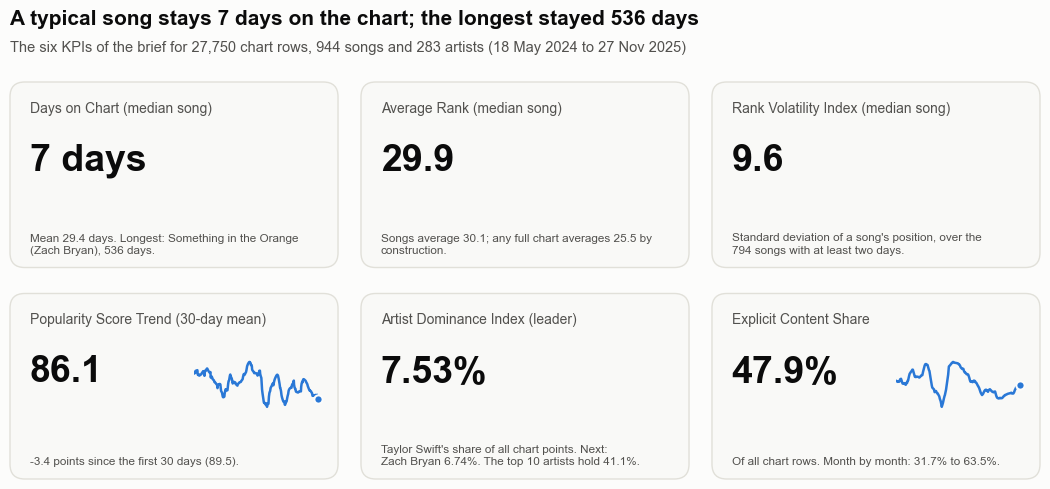

,KPI,value,context
0,Days on Chart (median song),7 days,Mean 29.4 days. Longest: Something in the Oran...
1,Average Rank (median song),29.9,Songs average 30.1; any full chart averages 25...
2,Rank Volatility Index (median song),9.6,"Standard deviation of a song's position, over ..."
3,Popularity Score Trend (30-day mean),86.1,-3.4 points since the first 30 days (89.5).
4,Artist Dominance Index (leader),7.53%,Taylor Swift's share of all chart points. Next...
5,Explicit Content Share,47.9%,Of all chart rows. Month by month: 31.7% to 63...


In [3]:
# Figure 01 - the six KPIs of the brief as stat tiles
daily["popularity_30d"] = daily["avg_popularity"].rolling(30, min_periods=30).mean()      # the Popularity Score Trend
daily["explicit_30d"] = daily["explicit_share"].rolling(30, min_periods=30).mean()

longest = dim_track.loc[dim_track["days_on_chart"].idxmax()]
volatility = dim_track["rank_volatility_index"].dropna()                                    # songs with one day have no spread
leaders = dim_artist.sort_values("dominance_index_primary", ascending=False).reset_index(drop=True)
explicit_by_month = playlist.groupby("year_month")["is_explicit"].mean()

FACTS["days_median"] = dim_track["days_on_chart"].median()
FACTS["days_mean"] = dim_track["days_on_chart"].mean()
FACTS["days_max"] = int(longest["days_on_chart"])
FACTS["days_max_song"] = longest["song_clean"]
FACTS["days_max_artist"] = longest["primary_artist"]
FACTS["avg_rank_song_median"] = dim_track["avg_rank"].median()
FACTS["avg_rank_song_mean"] = dim_track["avg_rank"].mean()
FACTS["avg_rank_chart"] = playlist["position"].mean()
FACTS["volatility_median"] = volatility.median()
FACTS["volatility_songs"] = len(volatility)
FACTS["popularity_now"] = daily["popularity_30d"].iloc[-1]
FACTS["popularity_first_month"] = daily["popularity_30d"].dropna().iloc[0]
FACTS["popularity_change"] = FACTS["popularity_now"] - FACTS["popularity_first_month"]
FACTS["adi_leader"] = leaders.loc[0, "dominance_index_primary"]
FACTS["adi_leader_name"] = leaders.loc[0, "artist_name"]
FACTS["adi_second"] = leaders.loc[1, "dominance_index_primary"]
FACTS["adi_second_name"] = leaders.loc[1, "artist_name"]
FACTS["adi_top10"] = leaders["dominance_index_primary"].head(10).sum()
FACTS["explicit_share"] = playlist["is_explicit"].mean() * 100
FACTS["explicit_month_low"] = explicit_by_month.min() * 100
FACTS["explicit_month_high"] = explicit_by_month.max() * 100

fig, axes = make_fig(11, 5.2, 2, 3, left=0.35, right=0.35, bottom=0.3, hspace=0.14, wspace=0.07,
                     title=f"A typical song stays {FACTS['days_median']:.0f} days on the chart; the longest stayed {FACTS['days_max']} days",
                     subtitle=f"The six KPIs of the brief for {FACTS['rows']:,} chart rows, {FACTS['songs']} songs and {FACTS['artists']} artists "
                              f"({FACTS['first_date']} to {FACTS['last_date']})")
tiles = [
    ("Days on Chart (median song)", f"{FACTS['days_median']:.0f} days",
     f"Mean {FACTS['days_mean']:.1f} days. Longest: {FACTS['days_max_song']} ({FACTS['days_max_artist']}), {FACTS['days_max']} days.", None),
    ("Average Rank (median song)", f"{FACTS['avg_rank_song_median']:.1f}",
     f"Songs average {FACTS['avg_rank_song_mean']:.1f}; any full chart averages {FACTS['avg_rank_chart']:.1f} by construction.", None),
    ("Rank Volatility Index (median song)", f"{FACTS['volatility_median']:.1f}",
     f"Standard deviation of a song's position, over the {FACTS['volatility_songs']} songs with at least two days.", None),
    ("Popularity Score Trend (30-day mean)", f"{FACTS['popularity_now']:.1f}",
     f"{FACTS['popularity_change']:+.1f} points since the first 30 days ({FACTS['popularity_first_month']:.1f}).",
     daily["popularity_30d"].dropna().tolist()),
    ("Artist Dominance Index (leader)", f"{FACTS['adi_leader']:.2f}%",
     f"{FACTS['adi_leader_name']}'s share of all chart points. Next: {FACTS['adi_second_name']} {FACTS['adi_second']:.2f}%. The top 10 artists hold {FACTS['adi_top10']:.1f}%.", None),
    ("Explicit Content Share", f"{FACTS['explicit_share']:.1f}%",
     f"Of all chart rows. Month by month: {FACTS['explicit_month_low']:.1f}% to {FACTS['explicit_month_high']:.1f}%.",
     daily["explicit_30d"].dropna().mul(100).tolist()),
]
for ax, (label, value, context, spark) in zip(axes.ravel(), tiles):
    kpi_tile(ax, label, value, context, spark)
save_fig(fig, "p4_01_kpi_tiles", FIG_DIR)
plt.show()

display(pd.DataFrame(tiles, columns=["KPI", "value", "context", "sparkline"]).drop(columns="sparkline"))

**What to notice**

- The typical song is short-lived: the median is 7 days, the mean 29.4. The gap between the two is the first sign of a very uneven chart: *Something in the Orange* by Zach Bryan stayed 536 of the 555 snapshot days.
- The median song averages position 29.9. The chart as a whole averages 25.5 by construction (positions 1 to 50 are each used once a day), so the interesting question is how songs spread around that value, not the value itself.
- A typical song's position swings by 9.6 places (standard deviation, 794 songs with at least two days).
- The 30-day mean popularity score moved by -3.4 points, from 89.5 in the first 30 days to 86.1 in the last. Section 6 looks at how much of this comes from new songs arriving with lower scores.
- Taylor Swift alone holds 7.5% of all chart points, Zach Bryan 6.7%, and the ten biggest artists together 41%.
- 48% of all chart rows are explicit songs; by month the share ran from 32% to 64% (Section 7).

## Section 3 - Playlist ranking analysis

The first block of the brief asks how the playlist itself behaves: how the daily ranking is distributed, how songs move from one
day to the next, where chart runs begin and end, and which songs rise fast or fade slowly. The unit here is the *run*: a stretch
of consecutive days on which one song stays on the chart. A song that leaves and comes back has two runs. Runs that are cut off
by the first or the last day of the file are flagged, because their true length is unknown.

**What this code is.** A preparation cell with no chart. It builds the two tables that the next nine figures share: the chart-run table (`stint_table`: one row per run, with entry position, exit position, best position, days to the peak and the two cut-off flags) and the transition table (`position_transitions`: how many songs went from position A today to position B at the next snapshot, or left the chart).

**Why we need it.** A song's life is not one line. Counting runs lets us ask when songs enter, how long they last and where they leave. The cut-off flags matter: a run that is still going on the last day has not finished, and treating it as finished would make songs look shorter-lived than they are.

**What will happen.** Both tables are produced by tested functions from `src/eda/ranking.py`. The cell stores the counts as facts (runs, complete runs, cut-off runs, songs with more than one run), shows the first five runs and prints a one-line summary.

**Expected outcome.** A small table of five runs and the line *1,981 runs of 944 songs: 1,881 complete, 50 cut off at the start of the file, 50 cut off at the end.* The three numbers add up to the total.

**Motive.** Every length statement below says whether it uses complete runs only. This is the cell where that distinction is made once, for all figures.

In [4]:
stints = stint_table(playlist)                       # one row per chart run (a song can have several runs)
transitions = position_transitions(playlist)         # how songs move from one snapshot to the next

runs = stints.copy()
runs["run_no"] = runs.groupby("track_id").cumcount() + 1                             # 1 = the first run of the song in the file, 2 = its second run ...
band_edges = [0, 10, 20, 30, 40, 50]                                                 # ten places per band
band_names = ["1-10", "11-20", "21-30", "31-40", "41-50"]

WARM_UP_DAYS = 180                                   # song ages are only reliable after this many days of the file (see Figure 03)
warm_up_end = playlist["date"].min() + pd.Timedelta(days=WARM_UP_DAYS)

FACTS["runs"] = len(stints)
FACTS["runs_left_cut"] = int(stints["left_censored"].sum())
FACTS["runs_right_cut"] = int(stints["right_censored"].sum())
FACTS["runs_complete"] = int(stints["complete"].sum())
FACTS["runs_per_song_mean"] = len(stints) / stints["track_id"].nunique()
FACTS["songs_with_two_or_more_runs"] = int((stints.groupby("track_id").size() >= 2).sum())

display(stints.head(5)[["track_label", "start_date", "end_date", "length", "entry_position", "exit_position", "best_position",
                        "days_to_peak", "left_censored", "right_censored"]])
print(f"{FACTS['runs']:,} runs of {FACTS['songs']} songs: {FACTS['runs_complete']:,} complete, "
      f"{FACTS['runs_left_cut']} cut off at the start of the file, {FACTS['runs_right_cut']} cut off at the end.")

,track_label,start_date,end_date,length,entry_position,exit_position,best_position,days_to_peak,left_censored,right_censored
0,Ella Baila Sola by Eslabon Armado,2024-05-18,2024-10-28,164,1,35,1,0,True,False
1,Ella Baila Sola by Eslabon Armado,2024-11-06,2024-11-08,3,42,42,42,0,False,False
2,Ella Baila Sola by Eslabon Armado,2024-11-12,2024-11-12,1,48,48,48,0,False,False
3,Ella Baila Sola by Eslabon Armado,2024-12-31,2024-12-31,1,50,50,50,0,False,False
4,Ella Baila Sola by Eslabon Armado,2025-01-03,2025-01-03,1,46,46,46,0,False,False


1,981 runs of 944 songs: 1,881 complete, 50 cut off at the start of the file, 50 cut off at the end.


**What to notice**

- The 944 songs made 1,981 runs, about 2.1 per song; 313 songs left the chart at least once and came back.
- Exactly 50 runs are cut off at the start (the 50 songs that were on the chart on the first day) and 50 at the end (the 50 songs on the last day). That leaves 1,881 complete runs for the length statistics.
- The transition table covers 27,700 song-days that have a following snapshot (the last day has none).

**What this code is.** Figure 2: a timeline of the 25 songs with the most days on the chart. One row per song, one column per calendar day, coloured by the song's position that day (dark = near the top).

**Why we need it.** Averages hide the shape of a song's life. A strip chart shows it in one look: debut, climb, long plateau, slow fade, and any return after a break. It is the brief's "daily rank distribution" at the level of single songs.

**What will happen.** The code picks the 25 longest-running songs, builds a song-by-day grid of positions, draws it as an image and leaves the cells where a song was not on the chart empty. The calendar days without a snapshot show up as thin white columns across every row.

**Expected outcome.** A heat strip: long dark bands where a song held a top position, lighter bands where it slid down, white gaps where it left the chart, and four hairline white columns that are missing days in the file, not missing songs.

**Motive.** Make the idea of a run visible before we start counting runs.

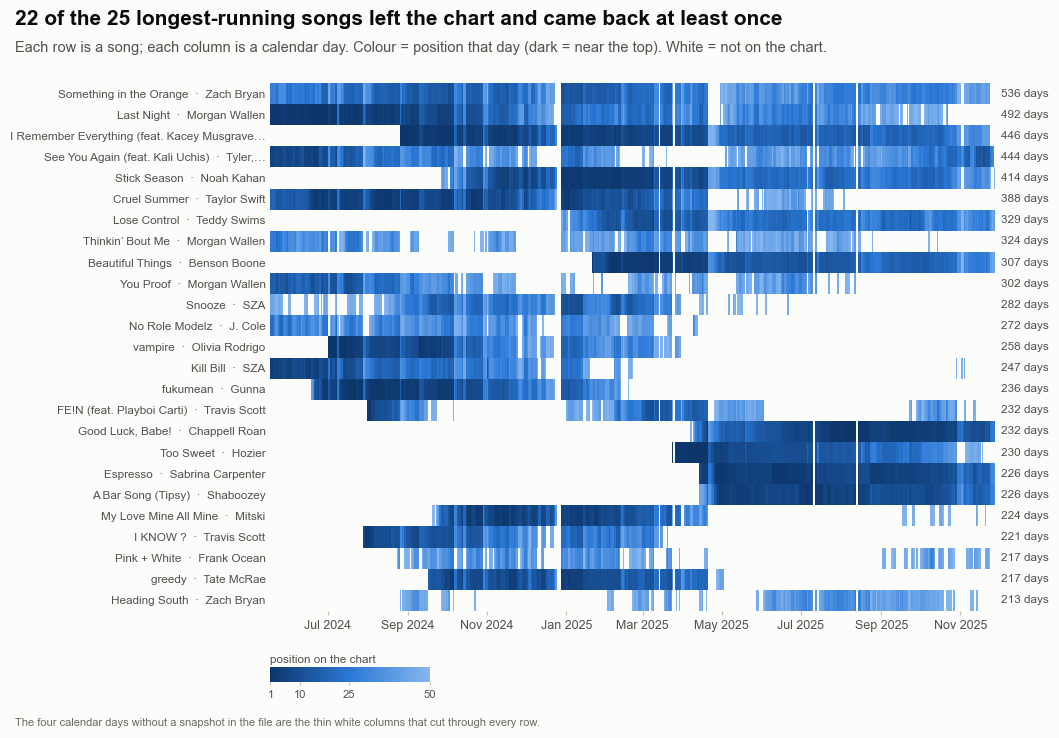

,track_label,days_on_chart,n_runs,longest_run_days,best_rank,avg_rank
0,Something in the Orange by Zach Bryan,536,4,220,9,26.30
1,Last Night by Morgan Wallen,492,10,219,1,22.62
2,I Remember Everything (feat. Kacey Musgraves) ...,446,3,305,1,13.90
3,"See You Again (feat. Kali Uchis) by Tyler, The...",444,19,149,4,29.38
4,Stick Season by Noah Kahan,414,5,305,1,18.29
5,Cruel Summer by Taylor Swift,388,10,221,1,16.92
6,Lose Control by Teddy Swims,329,3,181,5,23.50
7,Thinkin’ Bout Me by Morgan Wallen,324,27,45,21,39.02
8,Beautiful Things by Benson Boone,307,1,307,1,14.70
9,You Proof by Morgan Wallen,302,23,142,9,32.62


In [5]:
# Figure 02 - the playlist timeline: where the 25 longest-running songs stood, day by day
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize

longest_songs = dim_track.nlargest(25, "days_on_chart").reset_index(drop=True)
grid = (playlist[playlist["track_id"].isin(longest_songs["track_id"])]
        .pivot(index="track_id", columns="date", values="position")
        .reindex(index=longest_songs["track_id"], columns=dim_date["date"]))          # one row per song, one column per calendar day
cells = np.ma.masked_invalid(grid.to_numpy(dtype=float))

strip_map = LinearSegmentedColormap.from_list("strip", [style.BLUE_STEPS[700], style.BLUE_STEPS[450], style.BLUE_STEPS[250]])
strip_map = strip_map.with_extremes(bad=style.SURFACE)                        # a day without the song is drawn in the background colour

FACTS["strip_songs_with_returns"] = int((longest_songs["n_runs"] >= 2).sum())
FACTS["strip_min_days"] = int(longest_songs["days_on_chart"].min())

fig, ax = make_fig(11, 7.5, left=2.9, right=0.85, bottom=1.15,
                   title=f"{FACTS['strip_songs_with_returns']} of the 25 longest-running songs left the chart and came back at least once",
                   subtitle="Each row is a song; each column is a calendar day. Colour = position that day (dark = near the top). "
                            "White = not on the chart.",
                   note_text="The four calendar days without a snapshot in the file are the thin white columns that cut through every row.")
start, end = mdates.date2num(dim_date["date"].min()), mdates.date2num(dim_date["date"].max()) + 1
image = ax.imshow(cells, aspect="auto", cmap=strip_map, norm=Normalize(1, 50), interpolation="nearest",
                  extent=[start, end, len(longest_songs), 0])
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_yticks(np.arange(len(longest_songs)) + 0.5)
ax.set_yticklabels([short(f"{r.song_clean}  ·  {r.primary_artist}", 44) for r in longest_songs.itertuples()], fontsize=8.5)
ax.tick_params(axis="y", length=0)
for side in ("left", "bottom", "top", "right"):
    ax.spines[side].set_visible(False)
for i, row in longest_songs.iterrows():
    ax.text(1.008, 1 - (i + 0.5) / len(longest_songs), f"{row.days_on_chart} days", transform=ax.transAxes, fontsize=8.5,
            color=style.INK_2, va="center", ha="left")
cax = ax.inset_axes([0.0, -0.135, 0.22, 0.028])
bar = fig.colorbar(image, cax=cax, orientation="horizontal", ticks=[1, 10, 25, 50])
bar.outline.set_visible(False)
bar.ax.tick_params(labelsize=8, length=2)
cax.set_title("position on the chart", loc="left", fontsize=8.5, color=style.INK_2, pad=3)
save_fig(fig, "p4_02_presence_strips", FIG_DIR)
plt.show()

display(longest_songs[["track_label", "days_on_chart", "n_runs", "longest_run_days", "best_rank", "avg_rank"]].head(10))

**What to notice**

- 22 of these 25 songs left the chart at least once and came back, so even the most durable songs do not stay in one unbroken stretch.
- The 25th longest-running song still has 213 days on the chart, out of 555 possible. Songs at this level are on the chart for most of the file's life; Section 4 shows how few songs this applies to.

**What this code is.** Figure 3: how old the songs on the chart are, over time. A song's age is the number of days since it first appeared in the file. The 50 places of each day are split into five age bands (first week, 7-29 days, 30-89, 90-179, 180 or more) and shown as stacked areas, smoothed over seven days.

**Why we need it.** Whether the chart is fed by new songs or held by old ones is a basic question for a label that decides where to spend promotion. It also tells us from when song ages can be trusted: the file starts with a chart that is already running, so ages are understated at the beginning.

**What will happen.** The code counts the songs of each age band on every day, averages over seven days, shades the first 180 days of the file as the warm-up period, and stores the average number of places held by each band after the warm-up as facts.

**Expected outcome.** A stacked area chart in five shades of blue. The oldest band grows during the shaded warm-up and then stays roughly level, which is the sign that the chart has reached a steady state.

**Motive.** Separate a young chart from an old one honestly, and mark the stretch of the file where age is not known.

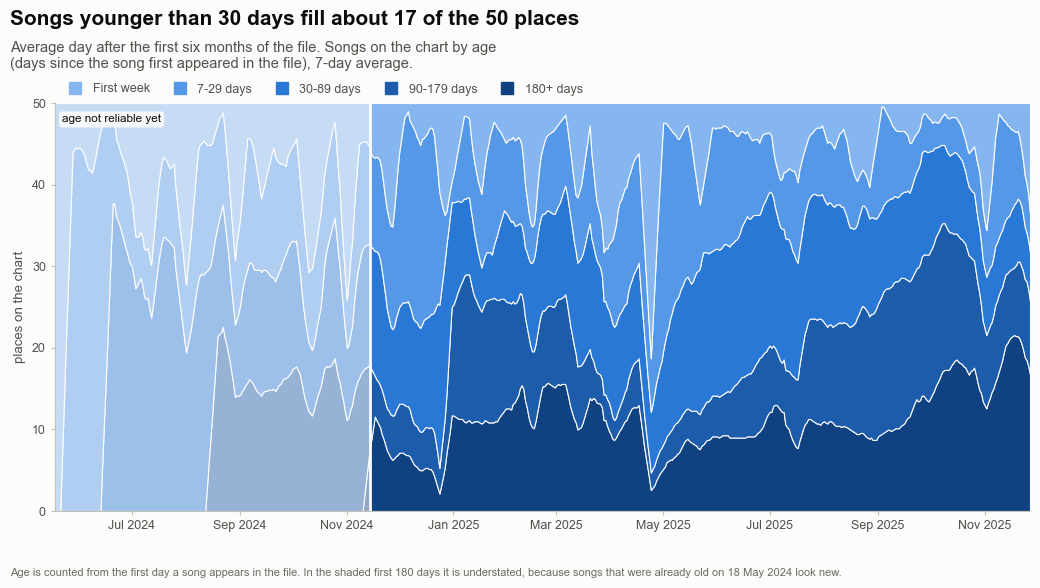

,average places per day,share_pct
age_band,,
First week,6.41,12.82
7-29 days,10.39,20.79
30-89 days,12.40,24.79
90-179 days,9.65,19.30
180+ days,11.15,22.30


In [6]:
# Figure 03 - how old are the songs that fill the 50 places? (the freshness of the chart over time)
import matplotlib.dates as mdates

age_bins = [-1, 6, 29, 89, 179, np.inf]
age_labels = ["First week", "7-29 days", "30-89 days", "90-179 days", "180+ days"]
playlist["age_band"] = pd.cut(playlist["calendar_age_days"], bins=age_bins, labels=age_labels)
slots = (pd.crosstab(playlist["date"], playlist["age_band"]).reindex(columns=age_labels, fill_value=0))      # songs per age band per day

settled = slots[slots.index >= warm_up_end]                                                                  # days on which every age is known
FACTS["age_first_week_slots"] = settled["First week"].mean()
FACTS["age_under_30_slots"] = (settled["First week"] + settled["7-29 days"]).mean()
FACTS["age_over_180_slots"] = settled["180+ days"].mean()
FACTS["age_over_90_slots"] = (settled["90-179 days"] + settled["180+ days"]).mean()

smooth = slots.rolling(7, center=True, min_periods=1).mean()                                                  # a 7-day average calms the day-to-day noise
fig, ax = make_fig(11, 6.0, left=0.8, right=0.45, bottom=0.65,
                   title=f"Songs younger than 30 days fill about {FACTS['age_under_30_slots']:.0f} of the 50 places",
                   subtitle="Average day after the first six months of the file. Songs on the chart by age (days since the song first appeared in the file), 7-day average.",
                   note_text="Age is counted from the first day a song appears in the file. In the shaded first 180 days it is understated, "
                             "because songs that were already old on 18 May 2024 look new.")
dates = slots.index
ax.stackplot(dates, [smooth[label] for label in reversed(age_labels)], colors=list(reversed(style.AGE_BAND_COLORS)),
             edgecolor=style.SURFACE, linewidth=0.8)
ax.axvspan(dates.min(), warm_up_end, color=style.SURFACE, alpha=0.55, linewidth=0)
ax.axvline(warm_up_end, color=style.SURFACE, linewidth=2)
ax.text(dates.min() + pd.Timedelta(days=4), 48.6, "age not reliable yet", fontsize=8.5, color=style.INK, va="top", ha="left",
        bbox=dict(boxstyle="round,pad=0.25", facecolor=style.SURFACE, edgecolor="none", alpha=0.9))
ax.set_ylim(0, CHART_SIZE)
ax.set_xlim(dates.min(), dates.max())
ax.set_yticks(range(0, 51, 10))
ax.set_ylabel("places on the chart")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
style_axes(ax, grid=None)
swatch_legend(ax, [(label, color) for label, color in zip(age_labels, style.AGE_BAND_COLORS)], loc="lower left",
              bbox_to_anchor=(0.0, 1.0), ncol=5)
save_fig(fig, "p4_03_chart_age", FIG_DIR)
plt.show()

display(settled.mean().to_frame("average places per day").assign(share_pct=lambda t: t["average places per day"] / CHART_SIZE * 100))

**What to notice**

- After the warm-up, songs younger than 30 days fill about 17 of the 50 places (about 6.4 of them in their first week). Songs older than 90 days fill about 21 places, and 11 places are held by songs older than 180 days.
- In the shaded warm-up the age is understated, because a song that was on the chart on the first day looks "new" although it was not. Read only the part after the shading as a statement about age.

**What this code is.** Figure 4: for each of the 50 positions, how many different songs held it during the whole file (left) and how old the song on that position usually is (right).

**Why we need it.** Some positions are owned by a few songs, others are a revolving door. This is the position-by-position version of the daily rank distribution and shows where a new release has a chance.

**What will happen.** The code counts distinct songs per position, then calculates the median and the middle 50 % of the song ages for each position (only after the 180-day warm-up, so that ages are known) and draws a bar chart next to a line with a band.

**Expected outcome.** Left: short bars at the top positions, long bars at the bottom. Right: a line of median age with a band around it; the headline says that the top is held by few, young songs and the bottom by many, older ones.

**Motive.** Show that the chart is not a uniform ladder: the top and the bottom behave differently, which the movement figures confirm.

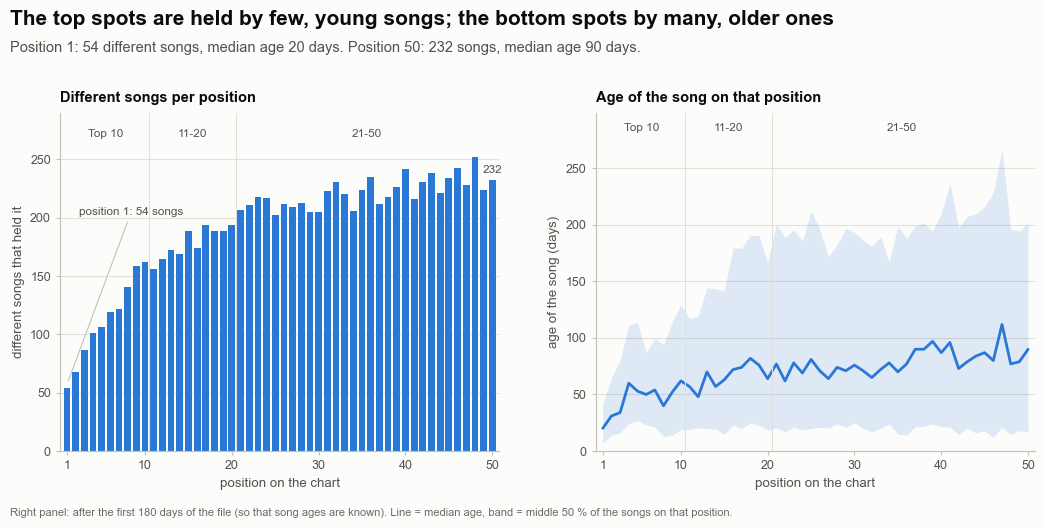

,different songs,median age (days)
position,,
1,54,20.00
2,68,31.00
3,87,34.00
5,106,53.00
10,162,62.00
20,194,64.00
30,205,76.00
40,242,87.00
50,232,90.00


In [7]:
# Figure 04 - who holds each position? (how many different songs, and how old they are)
holders = playlist.groupby("position")["track_id"].nunique()                                          # distinct songs per position
settled_rows = playlist[playlist["date"] >= warm_up_end]
age_by_position = settled_rows.groupby("position")["calendar_age_days"].quantile([0.25, 0.5, 0.75]).unstack()

FACTS["holders_pos1"] = holders.loc[1]
FACTS["holders_pos10"] = holders.loc[10]
FACTS["holders_pos50"] = holders.loc[50]
FACTS["holders_top10_mean"] = holders.loc[1:10].mean()
FACTS["holders_21_50_mean"] = holders.loc[21:50].mean()
FACTS["age_median_pos1"] = age_by_position.loc[1, 0.5]
FACTS["age_median_pos10"] = age_by_position.loc[10, 0.5]
FACTS["age_median_peak_pos"] = int(age_by_position[0.5].idxmax())
FACTS["age_median_peak"] = age_by_position[0.5].max()
FACTS["age_median_pos50"] = age_by_position.loc[50, 0.5]

fig, (ax1, ax2) = make_fig(11, 5.4, 1, 2, left=0.85, right=0.4, bottom=0.65, wspace=0.22, panel_titles=True,
                           title="The top spots are held by few, young songs; the bottom spots by many, older ones",
                           subtitle=f"Position 1: {FACTS['holders_pos1']} different songs, median age {FACTS['age_median_pos1']:.0f} days. "
                                    f"Position 50: {FACTS['holders_pos50']} songs, median age {FACTS['age_median_pos50']:.0f} days.",
                           note_text="Right panel: after the first 180 days of the file (so that song ages are known). Line = median age, band = middle 50 % of the songs on that position.")
positions = holders.index.to_numpy()
ax1.bar(positions, holders.to_numpy(), width=0.78, color=style.BLUE)
for label, x in (("Top 10", 5.5), ("11-20", 15.5), ("21-50", 35.5)):
    ax1.text(x, holders.max() * 1.07, label, ha="center", fontsize=8.5, color=style.INK_2)
for x in (10.5, 20.5):
    ax1.axvline(x, color=style.GRID, linewidth=0.8)
note(ax1, xy=(1, holders.loc[1] + 3), text=f"position 1: {holders.loc[1]} songs", xytext=(2.4, 205), ha="left")
direct_label(ax1, 50, holders.loc[50] + 5, f"{holders.loc[50]}", ha="center", va="bottom", size=8.5)
ax1.set_ylim(0, holders.max() * 1.15)
ax1.set_xlim(0.2, 50.8)
ax1.set_xticks([1, 10, 20, 30, 40, 50])
ax1.set_xlabel("position on the chart")
ax1.set_ylabel("different songs that held it")
panel_title(ax1, "Different songs per position")
style_axes(ax1, grid="y")

ax2.fill_between(age_by_position.index, age_by_position[0.25], age_by_position[0.75], color=style.BLUE, alpha=0.14, linewidth=0)
ax2.plot(age_by_position.index, age_by_position[0.5], color=style.BLUE, linewidth=2)
for x in (10.5, 20.5):
    ax2.axvline(x, color=style.GRID, linewidth=0.8)
ax2.set_xlim(0.2, 50.8)
ax2.set_ylim(0, age_by_position[0.75].max() * 1.12)
for label, x in (("Top 10", 5.5), ("11-20", 15.5), ("21-50", 35.5)):
    ax2.text(x, ax2.get_ylim()[1] * 0.97, label, ha="center", va="top", fontsize=8.5, color=style.INK_2)
ax2.set_xticks([1, 10, 20, 30, 40, 50])
ax2.set_xlabel("position on the chart")
ax2.set_ylabel("age of the song (days)")
panel_title(ax2, "Age of the song on that position")
style_axes(ax2, grid="y")
save_fig(fig, "p4_04_position_holders", FIG_DIR)
plt.show()

display(pd.DataFrame({"different songs": holders, "median age (days)": age_by_position[0.5]}).loc[[1, 2, 3, 5, 10, 20, 30, 40, 50]])

**What to notice**

- Position 1 was held by only 54 different songs in the whole file and position 50 by 232. The ten top positions average 112 different songs each, positions 21 to 50 average 222.
- The median age of the song on position 1 is 20 days, on position 10 it is 62 days, and on position 50 90 days. The oldest songs sit lower on the chart: the median age peaks at 112 days on position 47.

**What this code is.** Figure 5: the day-to-day movement of songs. Left, the share of days on which a song went up, went down or stayed on the same place, split by the group of positions (Top 10, 11-20, 21-50) it stands in today. Right, the average size of the move in places for each position.

**Why we need it.** The brief asks for rank movement. Direction tells us whether a group of positions is stable or restless; size tells us how big the restlessness is.

**What will happen.** The code uses the `rank_change` column made in Phase 2 (a positive number means the song climbed compared with the previous day). Rows without a previous day (new entries, returns, the first day) are left out of both panels, and the number of rows that remain is stored as a fact.

**Expected outcome.** Left: three stacked bars; the Top 10 bar is mostly "same", the 21-50 bar mostly up or down. Right: a line that rises steadily from position 1 to position 50.

**Motive.** Describe movement in numbers that Phase 5 can test: stability at the top against restlessness at the bottom.

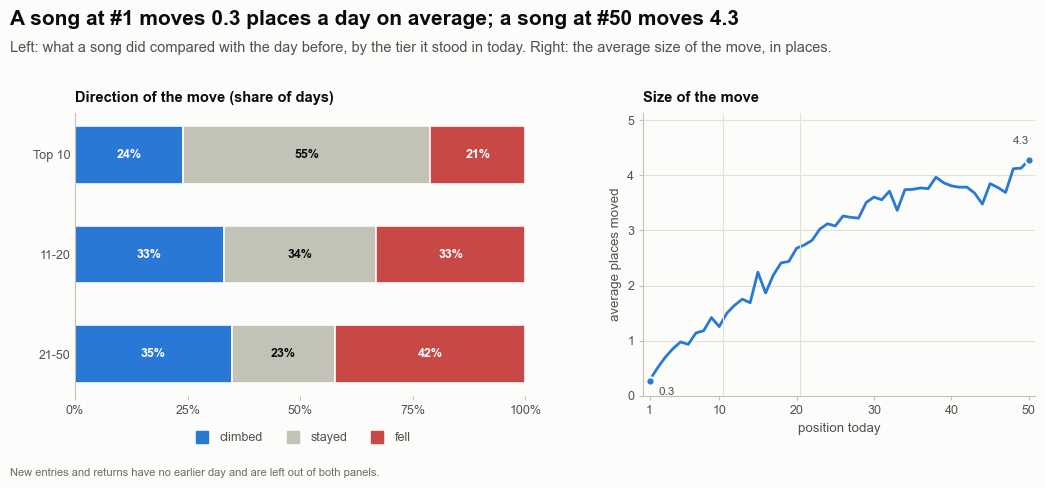

movement,climbed,stayed,fell,songs_days
rank_tier,,,,
Top 10,24.00,54.90,21.10,5297
11-20,33.00,33.90,33.10,5334
21-50,34.80,22.90,42.30,15138


In [8]:
# Figure 05 - how do songs move from one day to the next? (direction and size of the move)
moves = playlist[playlist["movement"].isin(["Up", "Down", "Same"])]                                     # new entries and returns have no earlier day
direction = (pd.crosstab(moves["rank_tier"], moves["movement"], normalize="index")
             .reindex(index=RANK_TIER_LABELS, columns=["Up", "Same", "Down"]) * 100)
move_size = playlist["rank_change"].abs().groupby(playlist["position"]).mean()                          # average places moved, by position

for tier, key in zip(RANK_TIER_LABELS, ["top10", "t1120", "t2150"]):
    for kind in ["Up", "Same", "Down"]:
        FACTS[f"move_{kind.lower()}_{key}"] = direction.loc[tier, kind]
FACTS["move_size_pos1"] = move_size.loc[1]
FACTS["move_size_pos10"] = move_size.loc[10]
FACTS["move_size_pos50"] = move_size.loc[50]
FACTS["move_rows"] = len(moves)

fig, (ax1, ax2) = make_fig(11, 5.0, 1, 2, left=1.0, right=0.4, bottom=0.8, wspace=0.28, panel_titles=True,
                           width_ratios=[1.15, 1],
                           title=f"A song at #1 moves {FACTS['move_size_pos1']:.1f} places a day on average; a song at #50 moves {FACTS['move_size_pos50']:.1f}",
                           subtitle="Left: what a song did compared with the day before, by the tier it stood in today. Right: the average size of the move, in places.",
                           note_text="New entries and returns have no earlier day and are left out of both panels.")
colors = {"Up": style.UP_COLOR, "Same": style.SAME_COLOR, "Down": style.DOWN_COLOR}
labels = {"Up": "climbed", "Same": "stayed", "Down": "fell"}
left_edge = np.zeros(len(direction))
y = np.arange(len(direction))
for kind in ["Up", "Same", "Down"]:
    values = direction[kind].to_numpy()
    ax1.barh(y, values, left=left_edge, height=0.58, color=colors[kind], edgecolor=style.SURFACE, linewidth=1.2)
    for yi, start, value in zip(y, left_edge, values):
        ax1.text(start + value / 2, yi, f"{value:.0f}%", ha="center", va="center", fontsize=9,
                 color=style.INK if kind == "Same" else "white", fontweight="bold")
    left_edge = left_edge + values
ax1.set_yticks(y)
ax1.set_yticklabels(direction.index)
ax1.invert_yaxis()
ax1.set_xlim(0, 100)
ax1.set_xticks([0, 25, 50, 75, 100])
ax1.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
panel_title(ax1, "Direction of the move (share of days)")
style_axes(ax1, grid=None, bottom_spine=False)
ax1.tick_params(axis="y", length=0)
swatch_legend(ax1, [(labels[k], colors[k]) for k in ["Up", "Same", "Down"]], loc="upper center", bbox_to_anchor=(0.5, -0.1),
              ncol=3)

ax2.plot(move_size.index, move_size.to_numpy(), color=style.BLUE, linewidth=2)
for x in (10.5, 20.5):
    ax2.axvline(x, color=style.GRID, linewidth=0.8)
for x in (1, 50):
    ax2.plot(x, move_size.loc[x], marker="o", markersize=6, color=style.BLUE, markeredgecolor=style.SURFACE, markeredgewidth=1.5)
direct_label(ax2, 2.2, move_size.loc[1] - 0.12, f"{move_size.loc[1]:.1f}", ha="left", va="top")
direct_label(ax2, 50, move_size.loc[50] + 0.25, f"{move_size.loc[50]:.1f}", ha="right", va="bottom")
ax2.set_xlim(0.2, 50.8)
ax2.set_ylim(0, move_size.max() * 1.2)
ax2.set_xticks([1, 10, 20, 30, 40, 50])
ax2.set_xlabel("position today")
ax2.set_ylabel("average places moved")
panel_title(ax2, "Size of the move")
style_axes(ax2, grid="y")
save_fig(fig, "p4_05_rank_movement", FIG_DIR)
plt.show()

display(direction.round(1).rename(columns=labels).assign(songs_days=moves.groupby("rank_tier").size().reindex(direction.index)))

**What to notice**

- In the top 10 a song stays on exactly the same position on 55% of days. In positions 21-50 it does so on only 23% of days, and there a song falls (42%) more often than it climbs (35%).
- The average move grows from 0.3 places at number one through 1.3 at number ten to 4.3 at number 50, measured over 25,769 song-days that have a previous day.

**What this code is.** Figure 6, the transition map: a 50-by-50 heat map. The row is a song's position today, the column its position at the next snapshot, and a darker cell means more songs made that move. One extra column, "gone", counts songs that were not on the chart the next day. The right panel condenses it into two lines per position: the share that stayed on exactly the same place and the share that left the chart.

**Why we need it.** It is the complete picture of movement in one chart: every possible move, including long jumps and exits. The "gone" column is the daily exit rate by position, which Phase 6 can use for the survival view of a song's life.

**What will happen.** The code counts every move with the tested `position_transitions` function, turns the counts into probabilities, draws the heat map on a square-root colour scale (so that rare long jumps stay visible next to the very common small moves) and stores a few reference values as facts.

**Expected outcome.** A bright band along the diagonal (songs stay near where they were), a thin scatter around it, and a darker "gone" column at the bottom positions. The right panel shows the stay rate falling and the exit rate rising from top to bottom.

**Motive.** Turn "how stable is the chart" into a table of probabilities that can be read, tested and reused.

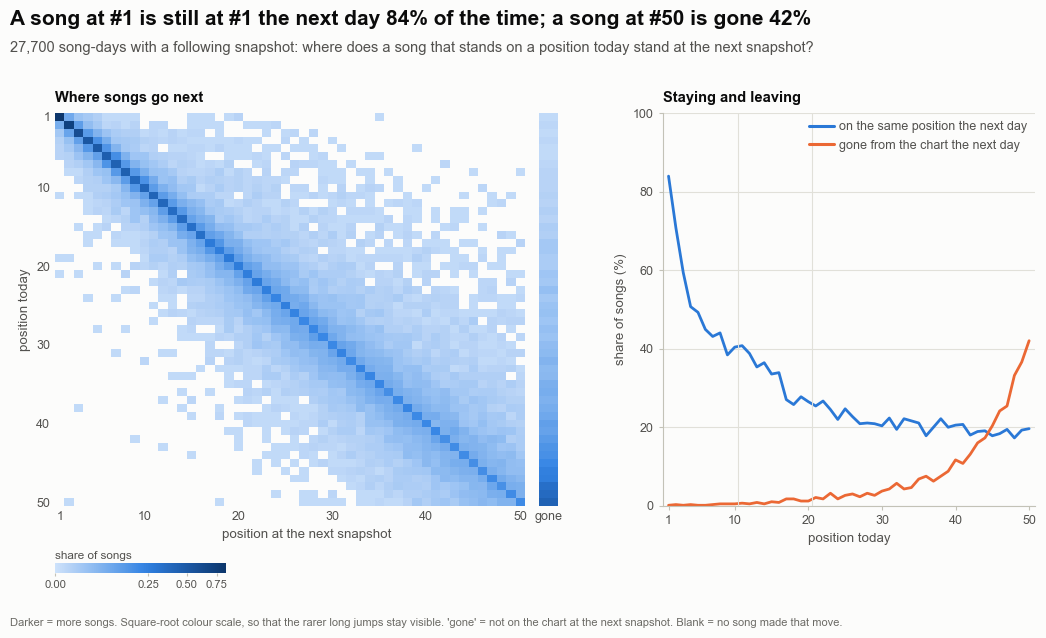

,stay (%),gone (%),within 2 places (%)
position,,,
1,83.94,0.18,95.13
2,70.76,0.36,94.04
5,49.28,0.18,90.07
10,40.43,0.54,79.60
20,26.53,1.26,66.25
30,20.40,3.79,53.97
40,20.58,11.73,47.11
50,19.68,42.06,31.59


In [9]:
# Figure 06 - the transition map: where does a song that stands on position A stand at the next snapshot?
from matplotlib.colors import PowerNorm

probabilities = transitions.probabilities()
stay = transitions.stay_rate() * 100
leave = transitions.exit_rate() * 100
near = pd.Series([probabilities.iloc[i, max(0, i - 2): i + 3].sum() * 100 for i in range(CHART_SIZE)], index=probabilities.index)

FACTS["stay_pos1"] = stay.loc[1]
FACTS["stay_pos10"] = stay.loc[10]
FACTS["stay_pos50"] = stay.loc[50]
FACTS["leave_pos10"] = leave.loc[10]
FACTS["leave_pos40"] = leave.loc[40]
FACTS["leave_pos50"] = leave.loc[50]
FACTS["near_pos1"] = near.loc[1]
FACTS["near_pos10"] = near.loc[10]
FACTS["near_pos30"] = near.loc[30]
FACTS["transition_pairs"] = int(transitions.n_today.sum())

places = np.ma.masked_equal(probabilities.to_numpy(), 0)                                                   # 50 x 50 moves between places
gone = transitions.exit_rate().to_numpy().reshape(-1, 1)                                                  # 50 x 1 "left the chart"
heat = style.SEQUENTIAL_BLUE.with_extremes(bad=style.SURFACE)
norm = PowerNorm(0.5, vmin=0, vmax=max(places.max(), gone.max()))

fig, (ax1, ax2) = make_fig(11, 6.5, 1, 2, left=0.8, right=0.4, bottom=1.2, wspace=0.24, panel_titles=True, width_ratios=[1.35, 1],
                           title=f"A song at #1 is still at #1 the next day {FACTS['stay_pos1']:.0f}% of the time; a song at #50 is gone {FACTS['leave_pos50']:.0f}%",
                           subtitle=f"{FACTS['transition_pairs']:,} song-days with a following snapshot: where does a song that stands on a position today stand at the next snapshot?",
                           note_text="Darker = more songs. Square-root colour scale, so that the rarer long jumps stay visible. 'gone' = not on the chart at the next snapshot. Blank = no song made that move.")
image = ax1.imshow(places, cmap=heat, norm=norm, aspect="auto", interpolation="nearest", extent=[0.5, 50.5, 50.5, 0.5])
ax1.imshow(gone, cmap=heat, norm=norm, aspect="auto", interpolation="nearest", extent=[52.0, 54.0, 50.5, 0.5])
ax1.set_xlim(0.5, 54.0)
ax1.set_xticks([1, 10, 20, 30, 40, 50, 53])
ax1.set_xticklabels(["1", "10", "20", "30", "40", "50", "gone"])
ax1.set_yticks([1, 10, 20, 30, 40, 50])
ax1.set_xlabel("position at the next snapshot")
ax1.set_ylabel("position today")
panel_title(ax1, "Where songs go next")
for side in ("left", "bottom"):
    ax1.spines[side].set_visible(False)
ax1.tick_params(length=0)
cax = ax1.inset_axes([0.0, -0.17, 0.34, 0.025])
bar = fig.colorbar(image, cax=cax, orientation="horizontal", ticks=[0, 0.25, 0.5, 0.75])
bar.outline.set_visible(False)
bar.ax.tick_params(labelsize=8, length=2)
cax.set_title("share of songs", loc="left", fontsize=8.5, color=style.INK_2, pad=3)

ax2.plot(stay.index, stay.to_numpy(), color=style.BLUE, linewidth=2)
ax2.plot(leave.index, leave.to_numpy(), color=style.ORANGE, linewidth=2)
for x in (10.5, 20.5):
    ax2.axvline(x, color=style.GRID, linewidth=0.8)
swatch_legend(ax2, [("on the same position the next day", style.BLUE), ("gone from the chart the next day", style.ORANGE)],
              kind="line", loc="upper right")
ax2.set_xlim(0.2, 50.8)
ax2.set_ylim(0, 100)
ax2.set_xticks([1, 10, 20, 30, 40, 50])
ax2.set_xlabel("position today")
ax2.set_ylabel("share of songs (%)")
panel_title(ax2, "Staying and leaving")
style_axes(ax2, grid="y")
save_fig(fig, "p4_06_transition_map", FIG_DIR)
plt.show()

display(pd.DataFrame({"stay (%)": stay, "gone (%)": leave, "within 2 places (%)": near}).loc[[1, 2, 5, 10, 20, 30, 40, 50]])

**What to notice**

- A song at number one is still at number one the next day 84% of the time. At number ten the stay rate is 40%, and at number 50 only 20%.
- The chance of being gone the next day is 0.5% from number ten, 12% from number 40 and 42% from number 50: leaving happens at the bottom, not at the top.
- 95% of the songs at number one are within two places of it the next day, 80% at number ten and 54% at number 30: the further down, the less predictable tomorrow's position. The table is built from 27,700 song-days.

**What this code is.** Figure 7: where chart runs begin and where they end. Left, the entry position of every run in bands of ten places, split into debuts (the first run of a song in the file) and returns (a later run). Right, the position on the last day before the song left.

**Why we need it.** This is the brief's entry-versus-exit comparison. It answers two questions a label asks: how high can a new song start, and how does a song leave, by fading out at the bottom or by dropping out of the top.

**What will happen.** The code takes the entry and exit position of every run from the run table. A run cut off at the start of the file has no known entry and is left out on the left; a run cut off at the end has no known exit and is left out on the right.

**Expected outcome.** Two bar charts. Both are tallest at 41-50; the left bars are split into two shades (debut and return).

**Motive.** Compare beginnings with endings in one view, and keep the cut-off runs out of the numbers.

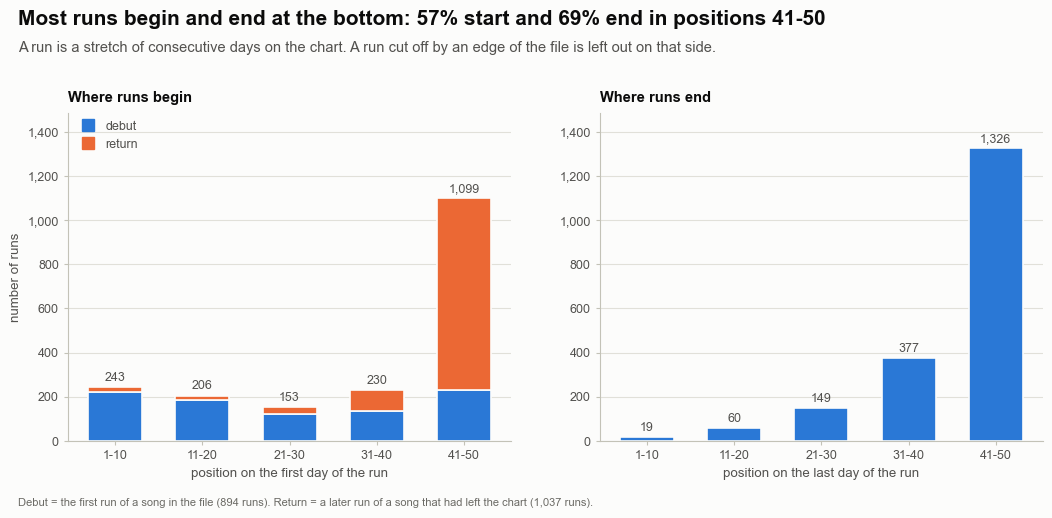

kind,debut,return,total,exits
band,,,,
1-10,222,21,243,19
11-20,186,20,206,60
21-30,120,33,153,149
31-40,134,96,230,377
41-50,232,867,1099,1326


In [10]:
# Figure 07 - entry versus exit behaviour: where do chart runs begin and where do they end?
entries = runs[~runs["left_censored"]].copy()                                                             # runs whose start we really saw
entries["band"] = pd.cut(entries["entry_position"], band_edges, labels=band_names)
entries["kind"] = np.where(entries["run_no"] == 1, "debut", "return")
entry_table = pd.crosstab(entries["band"], entries["kind"]).reindex(band_names)

exits = runs[~runs["right_censored"]].copy()                                                              # runs whose end we really saw
exits["band"] = pd.cut(exits["exit_position"], band_edges, labels=band_names)
exit_counts = exits["band"].value_counts().reindex(band_names)

FACTS["entries"] = len(entries)
FACTS["entries_debut"] = int((entries["kind"] == "debut").sum())
FACTS["entries_return"] = int((entries["kind"] == "return").sum())
FACTS["entry_bottom_pct"] = entry_table.loc["41-50"].sum() / len(entries) * 100
FACTS["entry_top10_pct"] = entry_table.loc["1-10"].sum() / len(entries) * 100
FACTS["debut_top10_pct"] = entry_table.loc["1-10", "debut"] / entry_table["debut"].sum() * 100
FACTS["debut_top20_pct"] = entry_table.loc[["1-10", "11-20"], "debut"].sum() / entry_table["debut"].sum() * 100
FACTS["return_bottom_pct"] = entry_table.loc["41-50", "return"] / entry_table["return"].sum() * 100
FACTS["exits"] = len(exits)
FACTS["exit_bottom_pct"] = exit_counts.loc["41-50"] / len(exits) * 100
FACTS["exit_top20_runs"] = int(exit_counts.loc[["1-10", "11-20"]].sum())
FACTS["exit_top20_pct"] = exit_counts.loc[["1-10", "11-20"]].sum() / len(exits) * 100

fig, (ax1, ax2) = make_fig(11, 5.3, 1, 2, left=0.85, right=0.4, bottom=0.65, wspace=0.2, panel_titles=True,
                           title=f"Most runs begin and end at the bottom: {FACTS['entry_bottom_pct']:.0f}% start and {FACTS['exit_bottom_pct']:.0f}% end in positions 41-50",
                           subtitle="A run is a stretch of consecutive days on the chart. A run cut off by an edge of the file is left out on that side.",
                           note_text=f"Debut = the first run of a song in the file ({FACTS['entries_debut']:,} runs). Return = a later run of a song that had left the chart ({FACTS['entries_return']:,} runs).")
x = np.arange(len(band_names))
ax1.bar(x, entry_table["debut"], width=0.62, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2)
ax1.bar(x, entry_table["return"], width=0.62, bottom=entry_table["debut"], color=style.ORANGE, edgecolor=style.SURFACE, linewidth=1.2)
for xi, total in zip(x, entry_table.sum(axis=1)):
    ax1.text(xi, total + 14, f"{total:,}", ha="center", va="bottom", fontsize=9, color=style.INK_2)
ax1.set_xticks(x)
ax1.set_xticklabels(band_names)
ax1.set_xlabel("position on the first day of the run")
ax1.set_ylabel("number of runs")
top_of_axis = max(entry_table.sum(axis=1).max(), exit_counts.max()) * 1.12              # the same scale in both panels
ax1.set_ylim(0, top_of_axis)
ax1.yaxis.set_major_formatter(THOUSANDS)
panel_title(ax1, "Where runs begin")
style_axes(ax1, grid="y")
swatch_legend(ax1, [("debut", style.BLUE), ("return", style.ORANGE)], loc="upper left", ncol=1)

ax2.bar(x, exit_counts, width=0.62, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2)
for xi, total in zip(x, exit_counts):
    ax2.text(xi, total + 14, f"{total:,}", ha="center", va="bottom", fontsize=9, color=style.INK_2)
ax2.set_xticks(x)
ax2.set_xticklabels(band_names)
ax2.set_xlabel("position on the last day of the run")
ax2.set_ylim(0, top_of_axis)
ax2.yaxis.set_major_formatter(THOUSANDS)
panel_title(ax2, "Where runs end")
style_axes(ax2, grid="y")
save_fig(fig, "p4_07_entry_exit", FIG_DIR)
plt.show()

display(entry_table.assign(total=entry_table.sum(axis=1), exits=exit_counts))

**What to notice**

- 57% of the 1,931 runs begin in positions 41-50, and 69% of the 1,931 runs end there. Most of the chart's life is a bottom-of-the-chart story.
- Debuts can start high: 25% of first runs begin in the top 10 and 46% in the top 20. Returns are different: 84% of them come back at the bottom.
- Only 4% of runs (79 runs) end in the top 20. Songs that leave from there do not fade out; they disappear, and Figure 9 treats them separately.

**What this code is.** Figure 8: how many songs the chart replaces on a day. Left, entries per day over time, with unusually busy days highlighted; right, the average number of entries for each weekday.

**Why we need it.** Turnover tells us how fast the chart renews itself, and the weekday pattern tells us when new songs arrive. Both are inputs for release-timing decisions.

**What will happen.** An entry is a song that is on the chart today but was not on the previous snapshot (a new song or a return). The code counts entries per day, marks the days above the Phase 2 high-turnover rule (more entries than Q3 plus three times the interquartile range) and averages by weekday.

**Expected outcome.** A line with occasional spikes on the left; on the right seven bars of which Monday and Tuesday stand clearly above the rest.

**Motive.** Show when the chart changes, not only how much.

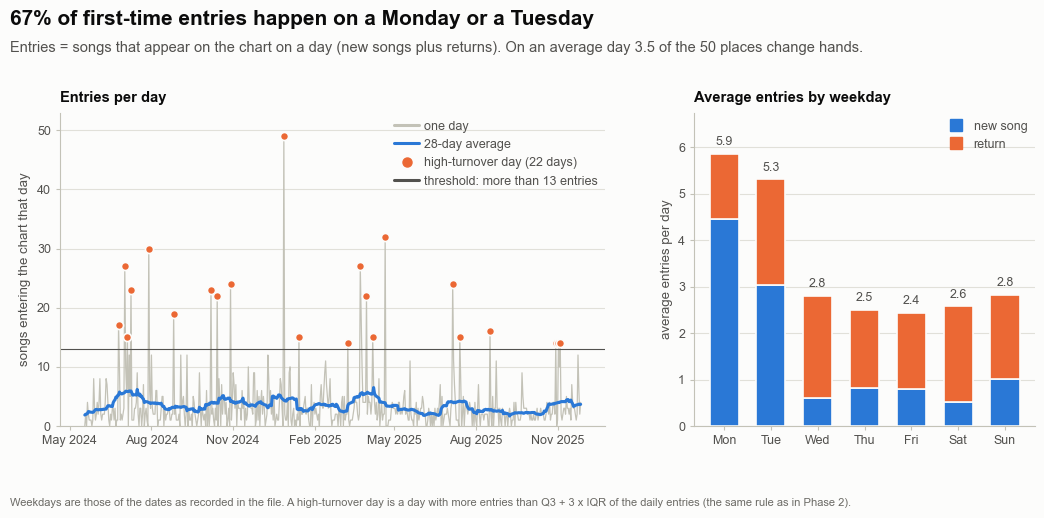

,day_name,days,new,returning,shocks,entries
0,Monday,80,4.46,1.40,10,5.86
1,Tuesday,79,3.04,2.28,6,5.32
2,Wednesday,79,0.61,2.20,0,2.81
3,Thursday,80,0.81,1.69,1,2.50
4,Friday,77,0.79,1.65,1,2.44
5,Saturday,80,0.52,2.05,1,2.58
6,Sunday,80,1.01,1.81,3,2.82


In [11]:
# Figure 08 - entry and exit behaviour over time: how many songs does the chart replace on a day, and on which weekday?
import matplotlib.dates as mdates

flow = daily.merge(dim_date[["date", "day_of_week", "day_name"]], on="date", how="left")
flow["entries"] = flow["new_entries"] + flow["re_entries"]                                                # songs that appear today (new or returning)
flow["entry_rate"] = flow["entries"] / CHART_SIZE * 100                                                   # percent of the 50 places

q1, q3 = flow["entries"].quantile([0.25, 0.75])
fence = q3 + 3 * (q3 - q1)                                                                                # Tukey far-out fence, as in Phase 2
assert ((flow["entries"] > fence) == flow["is_high_turnover_day"]).all(), "the fence does not reproduce the Phase 2 flag"
shock_days = flow[flow["is_high_turnover_day"]]

by_weekday = flow.groupby(["day_of_week", "day_name"]).agg(days=("date", "size"), new=("new_entries", "mean"),
                                                            returning=("re_entries", "mean"), shocks=("is_high_turnover_day", "sum")).reset_index()
by_weekday["entries"] = by_weekday["new"] + by_weekday["returning"]
mon_tue = flow[flow["day_of_week"].isin([1, 2])]["entries"].sum() / flow["entries"].sum() * 100
new_mon_tue = flow[flow["day_of_week"].isin([1, 2])]["new_entries"].sum() / flow["new_entries"].sum() * 100

FACTS["entries_per_day"] = flow["entries"].mean()
FACTS["fence_entries"] = fence
FACTS["shock_days"] = len(shock_days)
FACTS["shock_days_mon_tue"] = int(shock_days["day_of_week"].isin([1, 2]).sum())
FACTS["mon_tue_entry_share"] = mon_tue
FACTS["mon_tue_new_share"] = new_mon_tue
FACTS["entries_monday"] = by_weekday.loc[by_weekday["day_of_week"] == 1, "entries"].iloc[0]
FACTS["entries_tuesday"] = by_weekday.loc[by_weekday["day_of_week"] == 2, "entries"].iloc[0]
FACTS["entries_wed_to_sun"] = flow[flow["day_of_week"] >= 3]["entries"].mean()
FACTS["new_monday"] = by_weekday.loc[by_weekday["day_of_week"] == 1, "new"].iloc[0]
FACTS["new_wed_to_sun"] = flow[flow["day_of_week"] >= 3]["new_entries"].mean()
FACTS["max_entries_day"] = int(flow["entries"].max())
FACTS["max_entries_date"] = f"{flow.loc[flow['entries'].idxmax(), 'date']:%d %b %Y}"

fig, (ax1, ax2) = make_fig(11, 5.3, 1, 2, left=0.85, right=0.4, bottom=0.8, wspace=0.2, panel_titles=True, width_ratios=[1.6, 1],
                           title=f"{FACTS['mon_tue_new_share']:.0f}% of first-time entries happen on a Monday or a Tuesday",
                           subtitle=f"Entries = songs that appear on the chart on a day (new songs plus returns). On an average day {FACTS['entries_per_day']:.1f} of the 50 places change hands.",
                           note_text="Weekdays are those of the dates as recorded in the file. A high-turnover day is a day with more entries than Q3 + 3 x IQR of the daily entries (the same rule as in Phase 2).")
ax1.plot(flow["date"], flow["entries"], color=style.AXIS, linewidth=0.9)
rolling = flow["entries"].rolling(28, center=True, min_periods=14).mean()
ax1.plot(flow["date"], rolling, color=style.BLUE, linewidth=2.2)
ax1.scatter(shock_days["date"], shock_days["entries"], s=34, color=style.ORANGE, edgecolor=style.SURFACE, linewidth=1.2, zorder=4)
ax1.axhline(fence, color=style.INK_2, linewidth=0.8)
ax1.set_ylim(0, flow["entries"].max() * 1.08)
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax1.set_ylabel("songs entering the chart that day")
panel_title(ax1, "Entries per day")
style_axes(ax1, grid="y")
swatch_legend(ax1, [("one day", style.AXIS, "line"), ("28-day average", style.BLUE, "line"),
                    (f"high-turnover day ({FACTS['shock_days']} days)", style.ORANGE, "dot"),
                    (f"threshold: more than {fence:.0f} entries", style.INK_2, "line")], loc="upper right")

x = np.arange(len(by_weekday))
ax2.bar(x, by_weekday["new"], width=0.62, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2)
ax2.bar(x, by_weekday["returning"], width=0.62, bottom=by_weekday["new"], color=style.ORANGE, edgecolor=style.SURFACE, linewidth=1.2)
for xi, total in zip(x, by_weekday["entries"]):
    ax2.text(xi, total + 0.12, f"{total:.1f}", ha="center", va="bottom", fontsize=9, color=style.INK_2)
ax2.set_xticks(x)
ax2.set_xticklabels([name[:3] for name in by_weekday["day_name"]])
ax2.set_ylim(0, by_weekday["entries"].max() * 1.15)
ax2.set_ylabel("average entries per day")
panel_title(ax2, "Average entries by weekday")
style_axes(ax2, grid="y")
swatch_legend(ax2, [("new song", style.BLUE), ("return", style.ORANGE)], loc="upper right")
save_fig(fig, "p4_08_turnover", FIG_DIR)
plt.show()

display(by_weekday.drop(columns="day_of_week").round(2))

**What to notice**

- On an average day 3.5 of the 50 places change hands. 67% of first-time entries and 46% of all entries fall on a Monday or Tuesday: an average Monday brings 5.9 entries, a Tuesday 5.3, and each of the other days 2.6.
- 22 days had more than 13 entries; 16 of them are Mondays or Tuesdays. The busiest day, 28 Dec 2024, replaced 49 of the 50 places at once. It is kept in every count and is the highest point of the left panel.
- The weekdays are those of the dates as recorded in the file. The file's calendar appears to run about a year ahead of real release dates, so read the weekday pattern as a pattern of this file, not as a statement about real release days.

**What this code is.** Figure 9, two panels. Left: the ten fastest risers, measured as each song's biggest climb inside any seven days. Right: the slowest decliners, measured as places lost per week between a song's peak and the day it left, for runs that faded out gradually.

**Why we need it.** The brief asks for fast risers and slow decliners. Both need care. A climb measured from a song's first day would count every debut as a jump, so only songs that were already on the chart seven days earlier are used. A decline needs a long fade: a song that vanishes from the top 20 was removed, it did not fade.

**What will happen.** For risers the code compares each song-day with the same song seven days before and keeps each song's best gain. For decliners it uses the tested `decline_speed` function: complete runs, at least 28 days after the peak, ended at position 21 or worse. The ten slowest are shown against the median of all fading runs.

**Expected outcome.** Left: ten bars of gains, each labelled with the song and the positions it moved between. Right: ten dots of places lost per week, all close to one, with a line for the median of all fading runs.

**Motive.** Name the winners and the slow burners, and make clear which cases were left out and why.

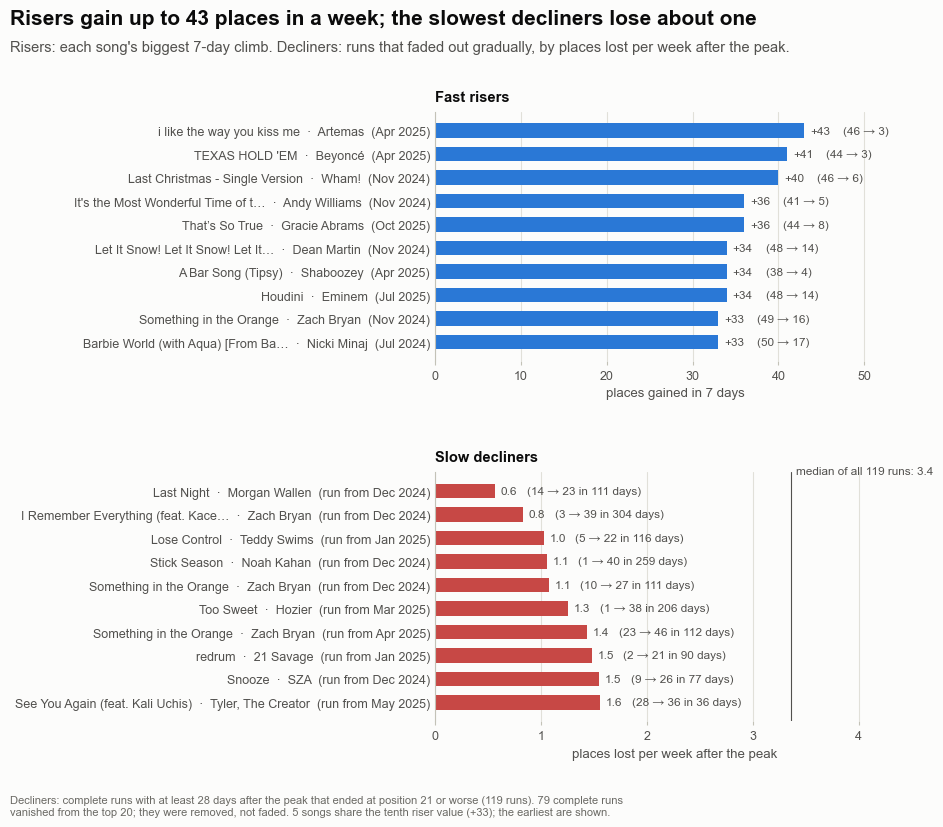

,track_label,date,from_position,position,rank_gain_7d
0,i like the way you kiss me by Artemas,2025-04-03,46,3,43.00
1,TEXAS HOLD 'EM by Beyoncé,2025-04-01,44,3,41.00
2,Last Christmas - Single Version by Wham!,2024-11-25,46,6,40.00
3,It's the Most Wonderful Time of the Year by An...,2024-11-26,41,5,36.00
4,That’s So True by Gracie Abrams,2025-10-29,44,8,36.00
5,Let It Snow! Let It Snow! Let It Snow! by Dean...,2024-11-28,48,14,34.00
6,A Bar Song (Tipsy) by Shaboozey,2025-04-29,38,4,34.00
7,Houdini by Eminem,2025-07-14,48,14,34.00
8,Something in the Orange by Zach Bryan,2024-11-08,49,16,33.00
9,Barbie World (with Aqua) [From Barbie The Albu...,2024-07-18,50,17,33.00


,track_label,best_position,exit_position,days_after_peak,positions_lost_per_week
0,Last Night by Morgan Wallen,14,23,111,0.57
1,I Remember Everything (feat. Kacey Musgraves) ...,3,39,304,0.83
2,Lose Control by Teddy Swims,5,22,116,1.03
3,Stick Season by Noah Kahan,1,40,259,1.05
4,Something in the Orange by Zach Bryan,10,27,111,1.07
5,Too Sweet by Hozier,1,38,206,1.26
6,Something in the Orange by Zach Bryan,23,46,112,1.44
7,redrum by 21 Savage,2,21,90,1.48
8,Snooze by SZA,9,26,77,1.55
9,"See You Again (feat. Kali Uchis) by Tyler, The...",28,36,36,1.56


In [12]:
# Figure 09 - fast risers and slow decliners
climbs = playlist.dropna(subset=["rank_gain_7d"])
fast = climbs.loc[climbs.groupby("track_id")["rank_gain_7d"].idxmax()].nlargest(10, "rank_gain_7d").reset_index(drop=True)   # best week of each song
fast["from_position"] = (fast["position"] + fast["rank_gain_7d"]).astype(int)                                                # where it stood 7 days earlier

fades = decline_speed(stints).merge(dim_track[["track_id", "song_clean", "primary_artist"]], on="track_id", how="left")      # complete runs that faded out gradually
slow = fades.head(10)

FACTS["riser_best_gain"] = int(fast.loc[0, "rank_gain_7d"])
FACTS["riser_best_song"] = fast.loc[0, "track_label"]
FACTS["riser_best_from"] = int(fast.loc[0, "from_position"])
FACTS["riser_best_to"] = int(fast.loc[0, "position"])
FACTS["riser_tenth_gain"] = int(fast.loc[9, "rank_gain_7d"])
FACTS["riser_ties"] = int((climbs.groupby("track_id")["rank_gain_7d"].max() == fast.loc[9, "rank_gain_7d"]).sum())
FACTS["riser_christmas"] = int(fast["track_label"].str.contains("Christmas|Snow|Wonderful Time|Holly", case=False).sum())
FACTS["fade_runs"] = len(fades)
FACTS["fade_median_speed"] = fades["positions_lost_per_week"].median()
FACTS["fade_slowest_speed"] = slow["positions_lost_per_week"].iloc[0]
FACTS["fade_slowest_song"] = slow["track_label"].iloc[0]
FACTS["fade_slowest_days"] = int(slow["days_after_peak"].iloc[0])
FACTS["fade_tenth_speed"] = slow["positions_lost_per_week"].iloc[9]
FACTS["fade_fastest_speed"] = fades["positions_lost_per_week"].iloc[-1]
FACTS["fade_cliff_runs"] = int((stints["complete"] & (stints["exit_position"] <= 20)).sum())

fig, (ax1, ax2) = make_fig(11, 8.4, 2, 1, left=4.6, right=1.6, bottom=0.8, hspace=0.45, panel_titles=True,
                           title=f"Risers gain up to {FACTS['riser_best_gain']} places in a week; the slowest decliners lose about one",
                           subtitle="Risers: each song's biggest 7-day climb. Decliners: runs that faded out gradually, by places lost per week after the peak.",
                           note_text=f"Decliners: complete runs with at least 28 days after the peak that ended at position 21 or worse ({FACTS['fade_runs']} runs). "
                                     f"{FACTS['fade_cliff_runs']} complete runs vanished from the top 20; they were removed, not faded. "
                                     f"{FACTS['riser_ties']} songs share the tenth riser value (+{FACTS['riser_tenth_gain']}); the earliest are shown.")
labels_up = [f"{short(r.song_clean, 34)}  ·  {short(r.primary_artist, 18)}  ({r.date:%b %Y})" for r in fast.itertuples()]
hbar(ax1, labels_up, fast["rank_gain_7d"], color=style.UP_COLOR, fmt="+{:.0f}", label_chars=None, xlim=(0, fast["rank_gain_7d"].max() * 1.3))
for yi, row in fast.iterrows():
    ax1.text(row["rank_gain_7d"] + 4.5, yi, f"({row['from_position']} → {row['position']})", ha="left", va="center", fontsize=8.5, color=style.INK_2)
ax1.set_xlabel("places gained in 7 days")
panel_title(ax1, "Fast risers")

labels_down = [f"{short(r.song_clean, 34)}  ·  {short(r.primary_artist, 18)}  (run from {r.start_date:%b %Y})" for r in slow.itertuples()]
hbar(ax2, labels_down, slow["positions_lost_per_week"], color=style.DOWN_COLOR, fmt="{:.1f}", label_chars=None,
     xlim=(0, fades["positions_lost_per_week"].median() * 1.35))
for yi, row in slow.iterrows():
    ax2.text(row["positions_lost_per_week"] + 0.3, yi, f"({row['best_position']} → {row['exit_position']} in {row['days_after_peak']} days)", ha="left", va="center", fontsize=8.5, color=style.INK_2)
ax2.axvline(FACTS["fade_median_speed"], color=style.INK_2, linewidth=0.8)
ax2.text(FACTS["fade_median_speed"] + 0.05, -0.62, f"median of all {FACTS['fade_runs']} runs: {FACTS['fade_median_speed']:.1f}", fontsize=8.5, color=style.INK_2, va="bottom")
ax2.set_xlabel("places lost per week after the peak")
panel_title(ax2, "Slow decliners")
save_fig(fig, "p4_09_risers_decliners", FIG_DIR)
plt.show()

display(fast[["track_label", "date", "from_position", "position", "rank_gain_7d"]])
display(slow[["track_label", "best_position", "exit_position", "days_after_peak", "positions_lost_per_week"]])

**What to notice**

- The fastest riser, *i like the way you kiss me by Artemas*, climbed from position 46 to 3, a gain of 43 places in a week. The tenth riser gained 33; 5 songs share that value, so the earliest are shown. 3 of the ten look like holiday songs by their titles.
- 119 runs faded gradually. The median of them loses 3.4 places a week, the fastest 10.2. The slowest, *Last Night by Morgan Wallen*, loses 0.6 places a week over 111 days after its peak.
- A further 79 complete runs left the chart from the top 20. They are not counted as fading: they were removed.

**What this code is.** Figure 10: how long a run lasts, depending on where it began. Runs are grouped by the band of their entry position. For each band a dot shows the median length, a thick bar the middle half of the runs and a thin line the range from the 10th to the 90th percentile; grey dots are single runs. The length axis is logarithmic.

**Why we need it.** It joins Section 3's two halves: where a run starts (Figure 7) and how long it lasts. A log axis is used because lengths range from one day to several months.

**What will happen.** The code keeps complete runs only, computes the quantiles of the length per entry band, spreads the single runs sideways so that they do not hide each other and stores the medians and the share of runs that last at least a week.

**Expected outcome.** Five rows, one per entry band, with the median shrinking from the top band to the bottom band.

**Motive.** Show that where a run starts says a lot about how long it lasts, using only runs whose whole length is known.

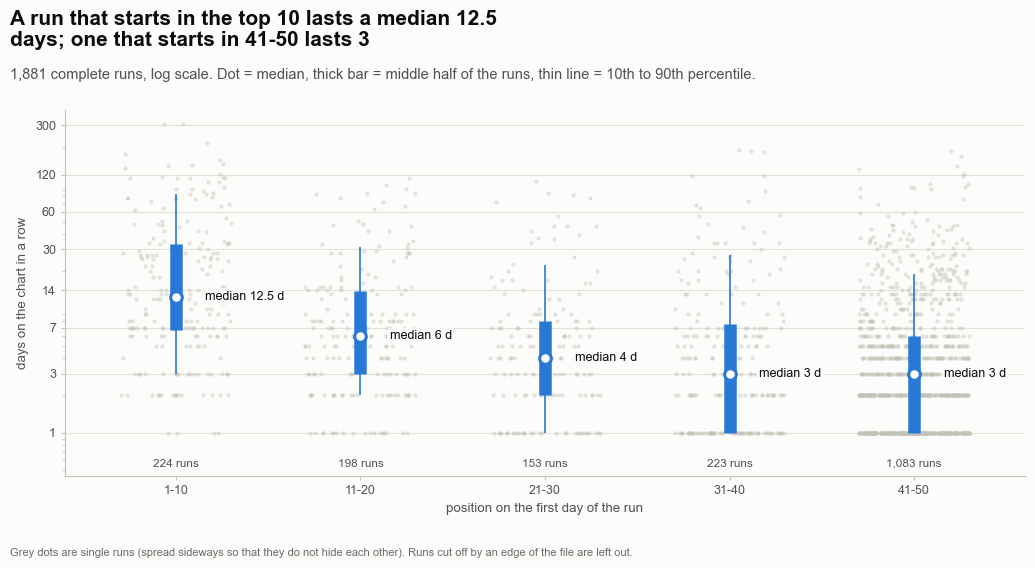

,p10,p25,p50,p75,p90,runs,share_7_days_or_more_pct
band,,,,,,,
1-10,3.00,6.75,12.50,33.00,84.40,224,75.00
11-20,2.00,3.00,6.00,13.75,31.30,198,47.47
21-30,1.00,2.00,4.00,8.00,22.40,153,34.64
31-40,1.00,1.00,3.00,7.50,26.80,223,30.94
41-50,1.00,1.00,3.00,6.00,19.00,1083,23.64


In [13]:
# Figure 10 - where a run begins and how long it lasts
finished = runs[runs["complete"]].copy()                                                                   # complete runs only: both ends are inside the file
finished["band"] = pd.cut(finished["entry_position"], band_edges, labels=band_names)
spread = finished.groupby("band", observed=True)["length"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack().reindex(band_names)
counts = finished["band"].value_counts().reindex(band_names)
week_or_more = finished.groupby("band", observed=True)["length"].apply(lambda s: (s >= 7).mean() * 100).reindex(band_names)

FACTS["finished_runs"] = len(finished)
for name, key in zip(band_names, ["b1", "b2", "b3", "b4", "b5"]):
    FACTS[f"run_median_{key}"] = spread.loc[name, 0.5]
    FACTS[f"run_week_pct_{key}"] = week_or_more.loc[name]
    FACTS[f"run_n_{key}"] = int(counts.loc[name])
FACTS["run_corr_entry_length"] = stats.spearmanr(finished["entry_position"], finished["length"])[0]

fig, ax = make_fig(11, 5.8, left=0.9, right=0.5, bottom=0.8,
                   title=f"A run that starts in the top 10 lasts a median {FACTS['run_median_b1']:g} days; one that starts in 41-50 lasts {FACTS['run_median_b5']:g}",
                   subtitle=f"{FACTS['finished_runs']:,} complete runs, log scale. Dot = median, thick bar = middle half of the runs, thin line = 10th to 90th percentile.",
                   note_text="Grey dots are single runs (spread sideways so that they do not hide each other). Runs cut off by an edge of the file are left out.")
rng = np.random.default_rng(4)
for i, name in enumerate(band_names):
    lengths = finished.loc[finished["band"] == name, "length"].to_numpy()
    ax.scatter(i + rng.uniform(-0.3, 0.3, len(lengths)), lengths, s=9, color=style.AXIS, alpha=0.45, linewidth=0, zorder=1)
    ax.vlines(i, spread.loc[name, 0.1], spread.loc[name, 0.9], color=style.BLUE, linewidth=1.2, zorder=2)
    ax.vlines(i, spread.loc[name, 0.25], spread.loc[name, 0.75], color=style.BLUE, linewidth=9, zorder=3)
    ax.scatter([i], [spread.loc[name, 0.5]], s=70, color=style.SURFACE, edgecolor=style.BLUE, linewidth=2.2, zorder=4)
    ax.text(i + 0.16, spread.loc[name, 0.5], f"median {spread.loc[name, 0.5]:g} d", ha="left", va="center", fontsize=9, color=style.INK, zorder=5,
            bbox=dict(boxstyle="round,pad=0.2", facecolor=style.SURFACE, edgecolor="none", alpha=0.85))
    ax.text(i, 0.62, f"{counts.loc[name]:,} runs", ha="center", va="top", fontsize=8.5, color=style.INK_2)
ax.set_yscale("log")
ax.set_ylim(0.45, finished["length"].max() * 1.3)
ax.set_yticks([1, 3, 7, 14, 30, 60, 120, 300])
ax.get_yaxis().set_major_formatter(THOUSANDS)
ax.set_xticks(range(len(band_names)))
ax.set_xticklabels(band_names)
ax.set_xlim(-0.6, len(band_names) - 0.4)
ax.set_xlabel("position on the first day of the run")
ax.set_ylabel("days on the chart in a row")
style_axes(ax, grid="y")
save_fig(fig, "p4_10_run_length", FIG_DIR)
plt.show()

display(spread.rename(columns=lambda q: f"p{int(q * 100)}").assign(runs=counts, share_7_days_or_more_pct=week_or_more))

**What to notice**

- Among the 1,881 complete runs, one that starts in the top 10 lasts a median 12.5 days, one that starts in 11-20 lasts 6, in 21-30 4, in 31-40 3 and in 41-50 3.
- 75% of the runs that begin in the top 10 last at least a week, against 24% of those that begin in 41-50. Across all complete runs, entry position and run length have a Spearman correlation of -0.36 (a higher start goes with a longer run; the sign is negative because position 1 is the best).

## Section 4 - Song-level analysis

Section 3 looked at the playlist as a whole. This section looks at songs one at a time: which songs stay longest, how few songs
carry most of the chart, which long-stayers are the most popular, and whether a song that climbs higher also stays longer.
Here one row is one song (944 rows), and all of a song's days are added together.

**What this code is.** Figure 11, two panels. Left: the 15 songs with the most days on the chart. Right: a cumulative curve that adds up chart points song by song, biggest song first, to show how few songs carry the chart.

**Why we need it.** "Longest presence" is a named item in the brief. The cumulative curve goes one step further: it turns "some songs stay long" into a number (how many songs does it take to reach half of all chart points) that can be compared with the artist concentration of Section 5.

**What will happen.** The code sorts songs by days on the chart, marks which of the top 15 were already on the chart on the first day or still there on the last day (their true presence is longer, so their bars are drawn lighter), then ranks songs by chart points and counts how many it takes to reach 50 %. It stores the Gini of chart points across songs as a fact.

**Expected outcome.** Left: 15 horizontal bars with the song and artist names. Right: a steep curve that reaches half of the points after a few dozen songs, with three labelled points.

**Motive.** Quantify "a few songs carry the chart" in one number, and be open about the songs whose presence the file cuts short.

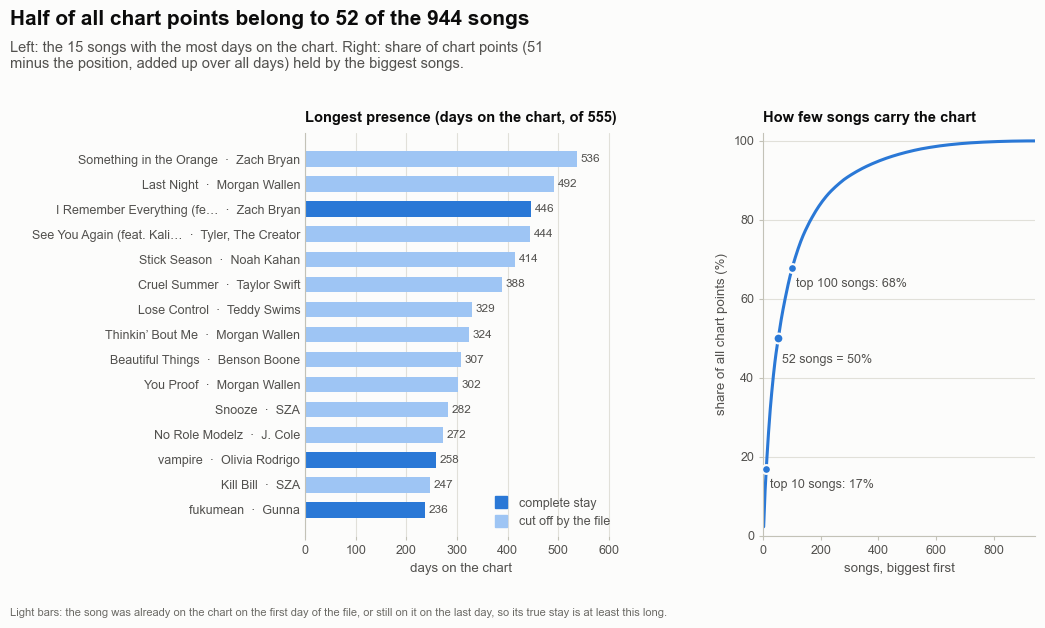

,track_label,days_on_chart,n_runs,best_rank,avg_rank,run_status
0,Something in the Orange by Zach Bryan,536,4,9,26.30,Already on chart at start
1,Last Night by Morgan Wallen,492,10,1,22.62,Already on chart at start
2,I Remember Everything (feat. Kacey Musgraves) ...,446,3,1,13.90,Complete history observed
3,"See You Again (feat. Kali Uchis) by Tyler, The...",444,19,4,29.38,Already on chart at start
4,Stick Season by Noah Kahan,414,5,1,18.29,Still on chart at end
5,Cruel Summer by Taylor Swift,388,10,1,16.92,Already on chart at start
6,Lose Control by Teddy Swims,329,3,5,23.50,Still on chart at end
7,Thinkin’ Bout Me by Morgan Wallen,324,27,21,39.02,Already on chart at start
8,Beautiful Things by Benson Boone,307,1,1,14.70,Still on chart at end
9,You Proof by Morgan Wallen,302,23,9,32.62,Already on chart at start


In [14]:
# Figure 11 - the songs with the longest presence, and how few songs carry the chart
top15 = dim_track.nlargest(15, "days_on_chart").reset_index(drop=True)
complete_history = top15["run_status"] == "Complete history observed"

ordered_points = dim_track["chart_points"].sort_values(ascending=False).to_numpy()
cumulative = cumulative_share(ordered_points) * 100
songs_for_half = int(np.searchsorted(cumulative, 50) + 1)                                                  # how many songs it takes to reach 50 %

FACTS["longest_days"] = int(top15.loc[0, "days_on_chart"])
FACTS["longest_song"] = top15.loc[0, "song_clean"]
FACTS["longest_artist"] = top15.loc[0, "primary_artist"]
FACTS["longest_15th_days"] = int(top15.loc[14, "days_on_chart"])
FACTS["longest_cut_off"] = int((~complete_history).sum())
FACTS["longest_share_of_window"] = top15.loc[0, "days_on_chart"] / FACTS["snapshots"] * 100
FACTS["points_total"] = int(dim_track["chart_points"].sum())
FACTS["songs_for_half"] = songs_for_half
FACTS["songs_for_half_pct"] = songs_for_half / len(dim_track) * 100
FACTS["points_top10_songs"] = cumulative[9]
FACTS["points_top100_songs"] = cumulative[99]
FACTS["points_gini_songs"] = gini(dim_track["chart_points"])

fig, (ax1, ax2) = make_fig(11, 6.4, 1, 2, left=3.3, right=0.4, bottom=0.8, wspace=0.5, panel_titles=True, width_ratios=[1.15, 1],
                           title=f"Half of all chart points belong to {songs_for_half} of the {FACTS['songs']} songs",
                           subtitle="Left: the 15 songs with the most days on the chart. Right: share of chart points (51 minus the position, added up over all days) held by the biggest songs.",
                           note_text="Light bars: the song was already on the chart on the first day of the file, or still on it on the last day, so its true stay is at least this long.")
labels = [f"{short(r.song_clean, 26)}  ·  {short(r.primary_artist, 20)}" for r in top15.itertuples()]
CUT_OFF_COLOR = style.BLUE_STEPS[200]
colors = [style.BLUE if complete else CUT_OFF_COLOR for complete in complete_history]
hbar(ax1, labels, top15["days_on_chart"], colors=colors, fmt="{:,.0f}", label_chars=None, xlim=(0, top15["days_on_chart"].max() * 1.15))
ax1.set_xlabel("days on the chart")
panel_title(ax1, f"Longest presence (days on the chart, of {FACTS['snapshots']})")
swatch_legend(ax1, [("complete stay", style.BLUE), ("cut off by the file", CUT_OFF_COLOR)], loc="lower right")

ax2.plot(np.arange(1, len(cumulative) + 1), cumulative, color=style.BLUE, linewidth=2.2)
ax2.scatter([songs_for_half], [50], s=50, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.5, zorder=4)
direct_label(ax2, songs_for_half + 14, 46, f"{songs_for_half} songs = 50%", ha="left", va="top", size=9)
for k in (10, 100):
    ax2.scatter([k], [cumulative[k - 1]], s=40, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.5, zorder=4)
    direct_label(ax2, k + 14, cumulative[k - 1] - 2.5, f"top {k} songs: {cumulative[k - 1]:.0f}%", ha="left", va="top", size=9)
ax2.set_xlim(0, len(cumulative))
ax2.set_ylim(0, 102)
ax2.set_xlabel("songs, biggest first")
ax2.set_ylabel("share of all chart points (%)")
panel_title(ax2, "How few songs carry the chart")
style_axes(ax2, grid="y")
save_fig(fig, "p4_11_longest_songs", FIG_DIR)
plt.show()

display(top15[["track_label", "days_on_chart", "n_runs", "best_rank", "avg_rank", "run_status"]])

**What to notice**

- *Something in the Orange* by Zach Bryan was on the chart on 536 of the 555 snapshot days (97% of the file). The 15th song on the list still has 236 days. 12 of the 15 were already on the chart on the first day or still there on the last (lighter bars), so their real presence is longer than shown.
- Together the songs earned 707,625 chart points. The 10 biggest songs hold 17% of them and the 100 biggest 68%; half of all points belong to just 52 songs, 5.5% of the 944. The Gini coefficient of chart points across songs is 0.78.

**What this code is.** Figure 12: the five longevity classes (Flash 1-3 days, Short 4-14, Medium 15-60, Long 61-180, Evergreen 181 or more) with each class's share of songs next to its share of all chart points.

**Why we need it.** The brief asks for a way to separate flash-in-the-pan songs from lasting ones. Classes make that readable, and putting two shares side by side shows how unequal the classes are in importance.

**What will happen.** The `longevity_class` column made in Phase 2 is used as it is. The code adds up songs and chart points per class and draws two bars per class (light = share of songs, dark = share of chart points).

**Expected outcome.** Five pairs of bars. For Flash and Short the light bar is tall and the dark bar short; for Evergreen it is the other way round.

**Motive.** Show which kind of song the chart is really made of: many songs are short visits, but the points are earned by a few long stayers.

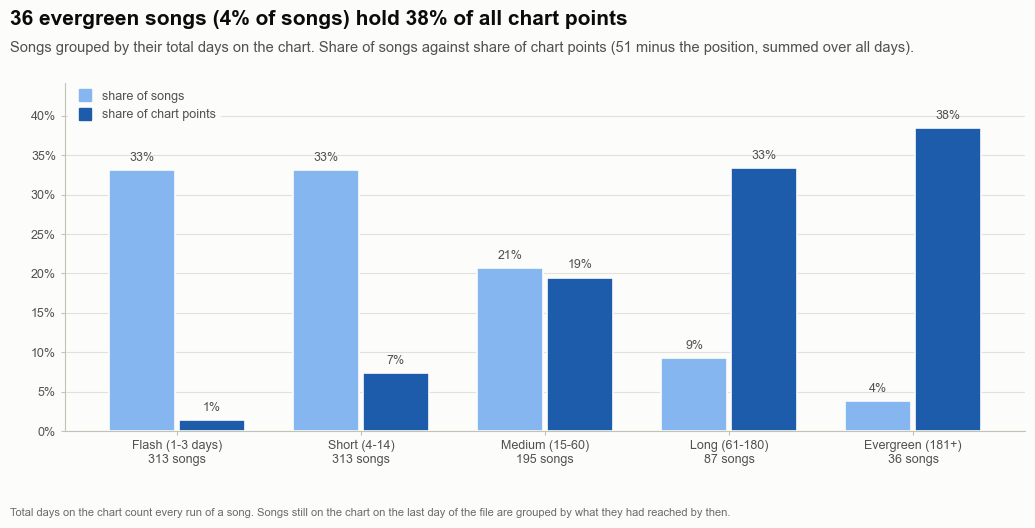

,songs,points,days,share_songs,share_points,share_days
longevity_class,,,,,,
Flash (1-3 days),313,9857,558,33.20,1.40,2.00
Short (4-14),313,51809,2347,33.20,7.30,8.50
Medium (15-60),195,137828,6254,20.70,19.50,22.50
Long (61-180),87,236300,8957,9.20,33.40,32.30
Evergreen (181+),36,271831,9634,3.80,38.40,34.70


In [15]:
# Figure 12 - the five longevity classes: few songs, most of the chart points
by_class = (dim_track.groupby("longevity_class")
            .agg(songs=("track_id", "size"), points=("chart_points", "sum"), days=("days_on_chart", "sum"))
            .reindex(LONGEVITY_LABELS))
by_class["share_songs"] = by_class["songs"] / by_class["songs"].sum() * 100
by_class["share_points"] = by_class["points"] / by_class["points"].sum() * 100
by_class["share_days"] = by_class["days"] / by_class["days"].sum() * 100

for label, key in zip(LONGEVITY_LABELS, ["flash", "short", "medium", "long", "evergreen"]):
    FACTS[f"class_songs_{key}"] = int(by_class.loc[label, "songs"])
    FACTS[f"class_share_songs_{key}"] = by_class.loc[label, "share_songs"]
    FACTS[f"class_share_points_{key}"] = by_class.loc[label, "share_points"]
FACTS["class_long_plus_points"] = by_class.loc[["Long (61-180)", "Evergreen (181+)"], "share_points"].sum()
FACTS["class_long_plus_songs_pct"] = by_class.loc[["Long (61-180)", "Evergreen (181+)"], "share_songs"].sum()
FACTS["class_long_plus_songs"] = int(by_class.loc[["Long (61-180)", "Evergreen (181+)"], "songs"].sum())

fig, ax = make_fig(11, 5.4, left=0.9, right=0.5, bottom=0.85,
                   title=f"{FACTS['class_songs_evergreen']} evergreen songs ({FACTS['class_share_songs_evergreen']:.0f}% of songs) hold {FACTS['class_share_points_evergreen']:.0f}% of all chart points",
                   subtitle="Songs grouped by their total days on the chart. Share of songs against share of chart points (51 minus the position, summed over all days).",
                   note_text="Total days on the chart count every run of a song. Songs still on the chart on the last day of the file are grouped by what they had reached by then.")
x = np.arange(len(LONGEVITY_LABELS))
width = 0.36
SONGS_COLOR, POINTS_COLOR = style.BLUE_STEPS[250], style.BLUE_STEPS[550]
bars1 = ax.bar(x - width / 2 - 0.01, by_class["share_songs"], width=width, color=SONGS_COLOR, edgecolor=style.SURFACE, linewidth=1.2)
bars2 = ax.bar(x + width / 2 + 0.01, by_class["share_points"], width=width, color=POINTS_COLOR, edgecolor=style.SURFACE, linewidth=1.2)
for bars in (bars1, bars2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f"{bar.get_height():.0f}%", ha="center", va="bottom",
                fontsize=9, color=style.INK_2)
ax.set_xticks(x)
ax.set_xticklabels([f"{label}\n{int(n)} songs" for label, n in zip(LONGEVITY_LABELS, by_class["songs"])])
ax.set_ylim(0, max(by_class["share_songs"].max(), by_class["share_points"].max()) * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0f}%"))
style_axes(ax, grid="y")
swatch_legend(ax, [("share of songs", SONGS_COLOR), ("share of chart points", POINTS_COLOR)], loc="upper left",
              frameon=True, facecolor=style.SURFACE, edgecolor="none", framealpha=1)
save_fig(fig, "p4_12_longevity_classes", FIG_DIR)
plt.show()

display(by_class.round(1))

**What to notice**

- 313 songs (33%) were on the chart for only one to three days and together earned 1.4% of the points. The 36 evergreen songs (3.8% of songs) hold 38%.
- Songs that lasted 61 days or more (123 songs, 13% of all songs) hold 72% of the chart points. A label that wants chart presence should look at the few songs that last, not at the many that visit.

**What this code is.** Figure 13: the 15 songs with the highest average popularity score, among songs that stayed at least 14 days. One dot per song on an axis that starts at 80, next to a line for the average of the whole chart.

**Why we need it.** "Highest average popularity" is a named item in the brief. Only long-stayers are ranked, because a song with three days on the chart and an average of 99 says little. The axis starts at 80 on purpose, since all scores live between 80 and 100, and the subtitle says so.

**What will happen.** The code keeps songs with at least 14 days, ranks them by average popularity (zeros that Phase 2 repaired are inside the averages and counted in a footnote) and draws a dot chart with the chart average as a reference.

**Expected outcome.** Fifteen dots between about 96 and 99, all clearly to the right of the chart-average line, each with the song and artist name.

**Motive.** Answer "which songs are the most popular" without being fooled by short visits.

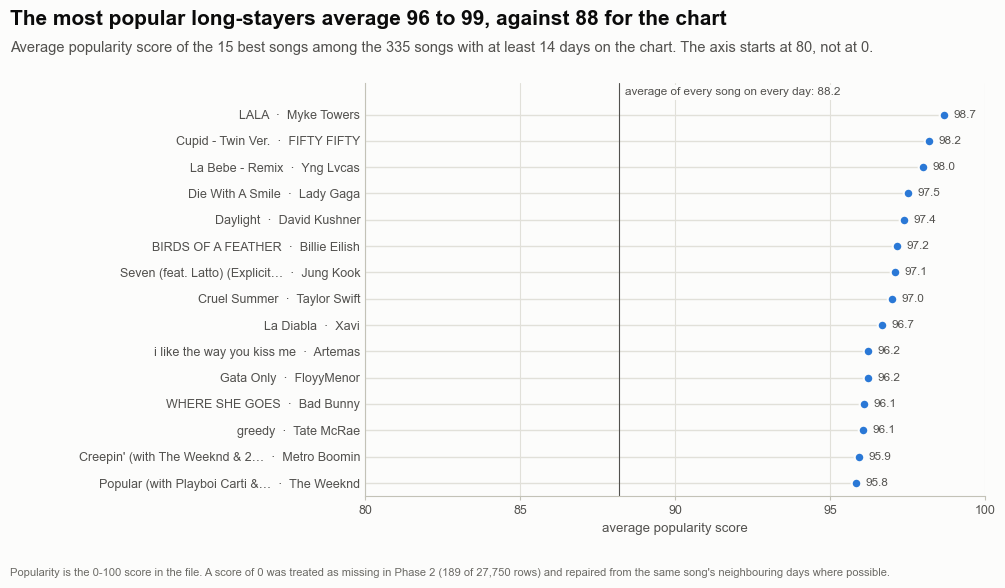

,track_label,days_on_chart,avg_popularity,peak_popularity,avg_rank,release_format
0,LALA by Myke Towers,49,98.69,99.00,38.02,Album
1,Cupid - Twin Ver. by FIFTY FIFTY,71,98.20,99.00,25.75,Single
2,La Bebe - Remix by Yng Lvcas & Peso Pluma,113,98.01,100.00,23.83,Single
3,Die With A Smile by Lady Gaga & Bruno Mars,103,97.53,100.00,3.47,Single
4,Daylight by David Kushner,55,97.40,99.00,37.20,Single
5,BIRDS OF A FEATHER by Billie Eilish,191,97.16,100.00,5.26,Album
6,Seven (feat. Latto) (Explicit Ver.) by Jung Ko...,89,97.11,100.00,22.49,Single
7,Cruel Summer by Taylor Swift,388,97.01,100.00,16.92,Album
8,La Diabla by Xavi,104,96.67,99.00,18.33,Single
9,i like the way you kiss me by Artemas,100,96.23,100.00,19.09,Single


In [16]:
# Figure 13 - songs with the highest average popularity (long stayers only)
MIN_DAYS = 14                                                                                              # a song needs two weeks of scores to have an average worth ranking
rated = dim_track[dim_track["days_on_chart"] >= MIN_DAYS].dropna(subset=["avg_popularity"])
best = rated.nlargest(15, "avg_popularity").reset_index(drop=True)
chart_mean = playlist["popularity_clean"].mean()

FACTS["pop_min_days"] = MIN_DAYS
FACTS["pop_rated_songs"] = len(rated)
FACTS["pop_best_value"] = best.loc[0, "avg_popularity"]
FACTS["pop_best_song"] = best.loc[0, "song_clean"]
FACTS["pop_best_artist"] = best.loc[0, "primary_artist"]
FACTS["pop_15th_value"] = best.loc[14, "avg_popularity"]
FACTS["pop_chart_mean"] = chart_mean
FACTS["pop_best_gap"] = best.loc[0, "avg_popularity"] - chart_mean
FACTS["pop_best_artists_distinct"] = best["primary_artist"].nunique()
FACTS["pop_best_single_share"] = (best["release_format"] == "Single").mean() * 100
FACTS["pop_all_songs_mean"] = rated["avg_popularity"].mean()
FACTS["pop_zero_rows"] = int(playlist["popularity_was_zero"].sum())

fig, ax = make_fig(11, 6.0, left=3.9, right=0.9, bottom=0.8,
                   title=f"The most popular long-stayers average {FACTS['pop_15th_value']:.0f} to {FACTS['pop_best_value']:.0f}, against {FACTS['pop_chart_mean']:.0f} for the chart",
                   subtitle=f"Average popularity score of the 15 best songs among the {FACTS['pop_rated_songs']} songs with at least {MIN_DAYS} days on the chart. The axis starts at 80, not at 0.",
                   note_text=f"Popularity is the 0-100 score in the file. A score of 0 was treated as missing in Phase 2 ({FACTS['pop_zero_rows']} of {FACTS['rows']:,} rows) and repaired from the same song's neighbouring days where possible.")
labels = [f"{short(r.song_clean, 30)}  ·  {short(r.primary_artist, 18)}" for r in best.itertuples()]
dot_row(ax, labels, best["avg_popularity"], color=style.BLUE, fmt="{:.1f}", label_chars=None, xlim=(80, 100))
ax.axvline(chart_mean, color=style.INK_2, linewidth=0.8)
ax.set_ylim(14.5, -1.2)
ax.text(chart_mean + 0.2, -0.85, f"average of every song on every day: {chart_mean:.1f}", fontsize=8.5, color=style.INK_2, va="center",
        bbox=dict(boxstyle="square,pad=0.2", facecolor=style.SURFACE, edgecolor="none"))
ax.set_xticks([80, 85, 90, 95, 100])
ax.set_xlabel("average popularity score")
style_axes(ax, grid="x", bottom_spine=True)
ax.tick_params(axis="y", length=0)
save_fig(fig, "p4_13_highest_popularity", FIG_DIR)
plt.show()

display(best[["track_label", "days_on_chart", "avg_popularity", "peak_popularity", "avg_rank", "release_format"]])

**What to notice**

- *LALA* by Myke Towers has the highest average popularity among the 335 songs with at least 14 days: 98.7, which is 10.5 points above the chart mean of 88.2. Even the 15th song averages 95.8.
- The 15 songs come from 15 different artists, so high popularity is not one artist's property. 73% of them are singles, while singles are 23% of all songs (Section 7).
- 189 chart rows carried a popularity score of 0, which Phase 2 treated as a missing value and repaired from the same song's other days.

**What this code is.** Figure 14, two panels. Left: every song as a dot, best position reached (across) against days on the chart (up, log scale). Right: the median stay for five groups of songs, grouped by their best position (number one, 2-5, 6-10, 11-20, 21-50).

**Why we need it.** The brief asks whether peak rank and longevity go together. A scatter shows every song; the grouped medians make the pattern readable. The correlation is rank-based (Spearman), because both measures are very uneven.

**What will happen.** The code calculates the Spearman correlation, groups songs by best position, takes the median and the middle half of days on the chart for each group, and stores the group sizes and medians as facts.

**Expected outcome.** Left: a cloud sloping from top-left (best position near 1, long stays) to bottom-right. Right: five bars of median days, tallest for the number-one group.

**Motive.** Test the simplest story, that songs which climb high also stay long, and show how strong it really is.

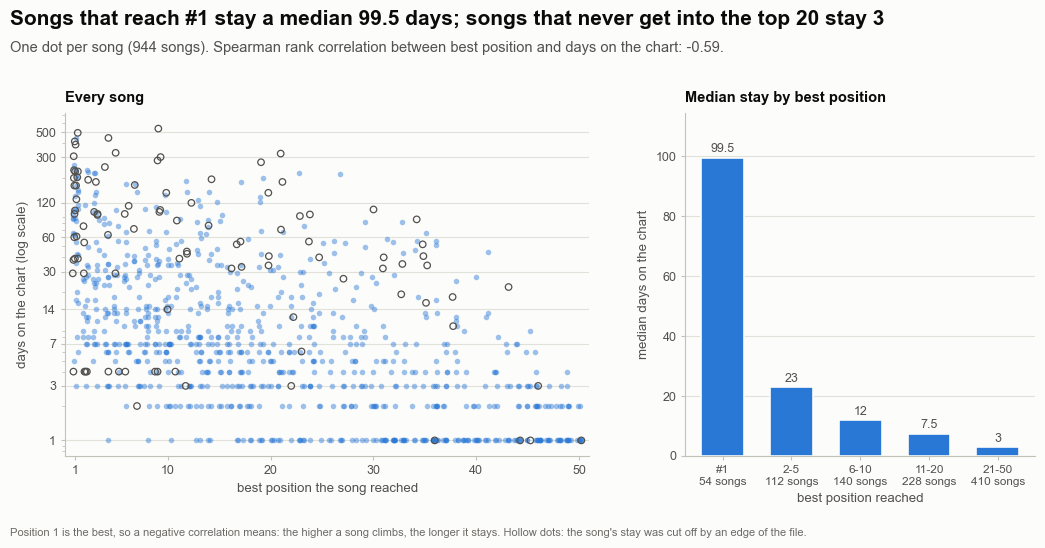

,songs,median,q25,q75
best_rank,,,,
#1,54,99.50,42.20,197.80
2-5,112,23.00,7.00,55.20
6-10,140,12.00,6.00,35.00
11-20,228,7.50,3.80,28.00
21-50,410,3.00,1.00,8.00


In [17]:
# Figure 14 - peak rank versus longevity: do songs that climb higher also stay longer?
best_bands = pd.cut(dim_track["best_rank"], [0, 1, 5, 10, 20, 50], labels=["#1", "2-5", "6-10", "11-20", "21-50"])
by_peak = dim_track.groupby(best_bands, observed=True)["days_on_chart"].agg(songs="size", median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
rho = stats.spearmanr(dim_track["best_rank"], dim_track["days_on_chart"])[0]
complete_history = dim_track["run_status"] == "Complete history observed"

FACTS["peak_rho"] = rho
for band, key in zip(by_peak.index, ["n1", "t5", "t10", "t20", "t50"]):
    FACTS[f"peak_median_{key}"] = by_peak.loc[band, "median"]
    FACTS[f"peak_songs_{key}"] = int(by_peak.loc[band, "songs"])
FACTS["peak_never_top10_songs"] = int((dim_track["best_rank"] > 10).sum())
FACTS["peak_never_top10_median"] = dim_track.loc[dim_track["best_rank"] > 10, "days_on_chart"].median()
FACTS["peak_top10_songs"] = int((dim_track["best_rank"] <= 10).sum())
FACTS["peak_top10_median"] = dim_track.loc[dim_track["best_rank"] <= 10, "days_on_chart"].median()

fig, (ax1, ax2) = make_fig(11, 5.6, 1, 2, left=0.9, right=0.4, bottom=0.8, wspace=0.22, panel_titles=True, width_ratios=[1.5, 1],
                           title=f"Songs that reach #1 stay a median {FACTS['peak_median_n1']:g} days; songs that never get into the top 20 stay {FACTS['peak_median_t50']:g}",
                           subtitle=f"One dot per song ({FACTS['songs']} songs). Spearman rank correlation between best position and days on the chart: {rho:.2f}.",
                           note_text="Position 1 is the best, so a negative correlation means: the higher a song climbs, the longer it stays. Hollow dots: the song's stay was cut off by an edge of the file.")
rng = np.random.default_rng(7)
jitter = rng.uniform(-0.3, 0.3, len(dim_track))
ax1.scatter(dim_track.loc[complete_history, "best_rank"] + jitter[complete_history.to_numpy()], dim_track.loc[complete_history, "days_on_chart"],
            s=16, color=style.BLUE, alpha=0.45, linewidth=0, zorder=2)
ax1.scatter(dim_track.loc[~complete_history, "best_rank"] + jitter[(~complete_history).to_numpy()], dim_track.loc[~complete_history, "days_on_chart"],
            s=22, facecolor="none", edgecolor=style.INK_2, linewidth=0.9, zorder=3)
ax1.set_yscale("log")
ax1.set_yticks([1, 3, 7, 14, 30, 60, 120, 300, 500])
ax1.yaxis.set_major_formatter(THOUSANDS)
ax1.set_xlim(0, 51)
ax1.set_xticks([1, 10, 20, 30, 40, 50])
ax1.set_xlabel("best position the song reached")
ax1.set_ylabel("days on the chart (log scale)")
panel_title(ax1, "Every song")
style_axes(ax1, grid="y")

x = np.arange(len(by_peak))
ax2.bar(x, by_peak["median"], width=0.62, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2)
for xi, (median, songs) in enumerate(zip(by_peak["median"], by_peak["songs"])):
    ax2.text(xi, median + 0.8, f"{median:g}", ha="center", va="bottom", fontsize=9, color=style.INK_2)
ax2.set_xticks(x)
ax2.set_xticklabels([f"{band}\n{int(n)} songs" for band, n in zip(by_peak.index, by_peak["songs"])], fontsize=8.5)
ax2.set_ylim(0, by_peak["median"].max() * 1.15)
ax2.set_ylabel("median days on the chart")
ax2.set_xlabel("best position reached")
panel_title(ax2, "Median stay by best position")
style_axes(ax2, grid="y")
save_fig(fig, "p4_14_peak_vs_longevity", FIG_DIR)
plt.show()

display(by_peak.round(1))

**What to notice**

- The Spearman correlation between best position and days on the chart is -0.59. It is negative because position 1 is the best, so it says that a higher peak goes with a longer stay.
- Songs that reached number one (54 songs) stayed a median 99.5 days. For best positions 2-5 (112 songs) the median is 23 days, for 6-10 (140 songs) 12, for 11-20 (228 songs) 7.5, and for songs that never got above position 20 (410 songs) 3.
- Put differently: the 306 songs that reached the top 10 stayed a median 23 days, the 638 that never did stayed 4. The two measures are partly linked by construction: the longer a song stays, the more chances it has to reach a high peak, so this is a pattern, not proof that a high peak causes a long stay.

## Section 5 - Artist analysis

The third block of the brief is about artists: how many different songs an artist places, how many days an artist is present,
and how dominant a few artists are over time. A song can credit several artists, so one rule is used for every artist figure:
an artist is the **first-named (primary) artist** of a song, and every song counts for exactly one artist. The tables from
Phase 3 carry the same measures under the name `*_primary`, and the preparation cell checks that our numbers agree with them.

**What this code is.** A preparation cell with no chart. It builds one row per artist from the daily table, counted on the primary credit: songs placed, song-days ("slot-days"), days with at least one song on the chart, chart points, song-days in the top 10, days at number one, average position, the share of all chart points (the Artist Dominance Index) and days per song. It then measures how concentrated the chart is across artists.

**Why we need it.** All artist figures need the same table, and the same definition of an artist. The cell also checks its own numbers against the `*_primary` columns that Phase 3 wrote to `dim_artist`; if they ever disagreed, the notebook would stop here instead of drawing wrong charts.

**What will happen.** The code groups the daily table by primary artist, joins the Phase 3 columns for the cross-check (suffix `_pipeline`), asserts that they match, and calls the tested concentration functions for the Herfindahl-Hirschman Index (HHI, the sum of squared percentage shares), the effective number of artists (10,000 divided by the HHI) and the Gini coefficient.

**Expected outcome.** A table of the eight biggest artists and one line with the artist count, HHI, effective number and Gini.

**Motive.** One definition of "artist" for the whole section, checked against the pipeline, and one set of concentration numbers that the later charts reuse.

In [18]:
# Section 5 preparation - one row per artist, counted on the PRIMARY credit (the first artist named on the song)
by_artist = playlist.groupby("primary_artist")
artists = pd.DataFrame({
    "songs": by_artist["track_id"].nunique(),
    "slot_days": by_artist.size(),                                    # song-days: three songs of one artist on one day = 3 slot-days
    "days_present": by_artist["date"].nunique(),                      # days on which the artist had at least one song on the chart
    "chart_points": by_artist["chart_points"].sum(),
    "top10_slot_days": by_artist["in_top10"].sum(),
    "number_one_days": by_artist["is_number_one"].sum(),
    "avg_rank": by_artist["position"].mean(),
}).sort_values(["chart_points", "slot_days"], ascending=False)
artists["share_pct"] = artists["chart_points"] / artists["chart_points"].sum() * 100        # the Artist Dominance Index (ADI)
artists["days_per_song"] = artists["slot_days"] / artists["songs"]

# The table must agree with the artist table of the pipeline (Phase 3), column by column
check = artists.join(dim_artist.set_index("artist_name"), how="left", rsuffix="_pipeline")
assert (check["songs"] == check["unique_tracks_as_primary"]).all()
assert (check["slot_days"] == check["chart_slot_days_primary"]).all()
assert (check["chart_points"] == check["chart_points_primary"]).all()
assert np.allclose(check["share_pct"], check["dominance_index_primary"], atol=1e-4)

summary_all = concentration_summary(artists["chart_points"], top_ns=(1, 5, 10, 20))
FACTS["artists_primary"] = len(artists)
FACTS["art_hhi"] = summary_all["hhi"]
FACTS["art_effective_n"] = summary_all["effective_number"]
FACTS["art_gini"] = summary_all["gini"]
for n in (1, 5, 10, 20):
    FACTS[f"art_top{n}_pct"] = summary_all[f"top_{n}_share"] * 100
FACTS["art_one_song"] = int((artists["songs"] == 1).sum())
FACTS["art_one_song_pct"] = FACTS["art_one_song"] / len(artists) * 100
FACTS["art_one_song_points_pct"] = artists.loc[artists["songs"] == 1, "chart_points"].sum() / artists["chart_points"].sum() * 100

display(artists.head(8).round(2))
print(f"{len(artists)} artists with a primary credit; HHI {summary_all['hhi']:.1f}, effective number {summary_all['effective_number']:.1f}, Gini {summary_all['gini']:.3f}")

,songs,slot_days,days_present,chart_points,top10_slot_days,number_one_days,avg_rank,share_pct,days_per_song
primary_artist,,,,,,,,,
Taylor Swift,96,2015,438,53293,428,34,24.55,7.53,20.99
Zach Bryan,38,1882,546,47692,286,8,25.66,6.74,49.53
Morgan Wallen,10,1669,540,34025,179,22,30.61,4.81,166.90
Sabrina Carpenter,14,967,316,32288,443,66,17.61,4.56,69.07
Chappell Roan,6,794,232,24100,180,12,20.65,3.41,132.33
Billie Eilish,12,729,333,22335,253,0,20.36,3.16,60.75
Drake,37,881,326,21781,134,25,26.28,3.08,23.81
Travis Scott,32,795,338,20315,103,9,25.45,2.87,24.84


243 artists with a primary credit; HHI 254.4, effective number 39.3, Gini 0.782


**What to notice**

- 243 of the 283 artists in `dim_artist` are the first-named artist of at least one song; the others appear only as featured guests.
- The chart behaves as if about 39 equal artists shared it (effective number 39.3), the HHI is 254 on a scale that ends at 10,000, and the Gini coefficient of chart points across artists is 0.78. Many artists share the chart, but very unevenly.

**What this code is.** Figure 15, two panels. Left: artists grouped by how many different songs they placed on the chart (1 song, 2, 3, 4-5, 6-10, 11-20, 21 or more), as a share of artists and as a share of chart points. Right: the 15 artists with the most days on the chart.

**Why we need it.** It covers two named items of the brief at once: unique songs per artist and total days appearing. Putting the share of artists next to the share of points shows whether placing many songs pays.

**What will happen.** The code counts songs per artist, groups them, adds up chart points per group and draws light and dark bars; the right panel counts, for each artist, the days on which at least one of their songs was on the chart.

**Expected outcome.** Left: the "1 song" group has a tall light bar (many artists) but a much shorter dark bar (few points); for the groups with many songs the dark bar is taller than the light one. Right: 15 horizontal bars of days present.

**Motive.** Separate the long tail of one-hit visitors from the few artists who keep placing songs.

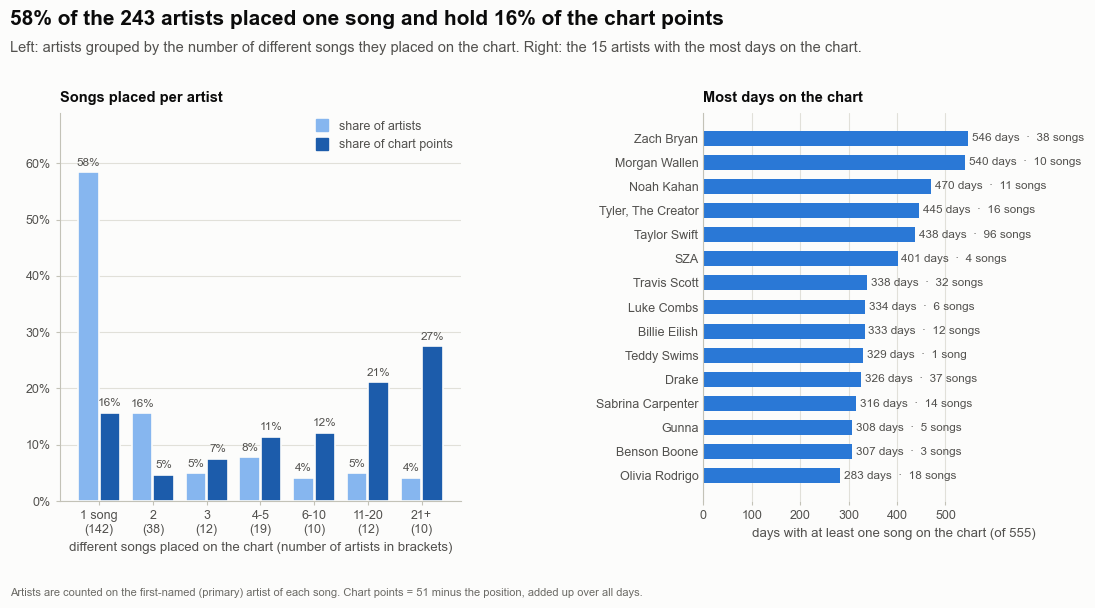

,artists,points,share_artists,share_points
songs,,,,
1 song,142,111207,58.40,15.70
2,38,32995,15.60,4.70
3,12,52974,4.90,7.50
4-5,19,80648,7.80,11.40
6-10,10,86116,4.10,12.20
11-20,12,149141,4.90,21.10
21+,10,194544,4.10,27.50


In [19]:
# Figure 15 - how many songs an artist places on the chart, and how many days the artist is present
song_bins = [0, 1, 2, 3, 5, 10, 20, 1000]
song_labels = ["1 song", "2", "3", "4-5", "6-10", "11-20", "21+"]
artist_band = pd.cut(artists["songs"], song_bins, labels=song_labels)
band = pd.DataFrame({"artists": artist_band.value_counts().reindex(song_labels),
                     "points": artists.groupby(artist_band, observed=True)["chart_points"].sum().reindex(song_labels)})
band["share_artists"] = band["artists"] / band["artists"].sum() * 100
band["share_points"] = band["points"] / band["points"].sum() * 100

most_present = artists.nlargest(15, "days_present").reset_index()
FACTS["art_most_songs"] = int(artists["songs"].max())
FACTS["art_most_songs_name"] = artists["songs"].idxmax()
FACTS["art_five_plus"] = int((artists["songs"] >= 5).sum())
FACTS["art_five_plus_points_pct"] = artists.loc[artists["songs"] >= 5, "chart_points"].sum() / artists["chart_points"].sum() * 100
FACTS["art_present_max"] = int(most_present.loc[0, "days_present"])
FACTS["art_present_max_name"] = most_present.loc[0, "primary_artist"]
FACTS["art_present_15th"] = int(most_present.loc[14, "days_present"])
FACTS["art_present_median"] = float(artists["days_present"].median())

fig, (ax1, ax2) = make_fig(11.5, 6.2, 1, 2, left=0.85, right=0.4, bottom=0.95, wspace=0.62, panel_titles=True, width_ratios=[1.05, 1],
                           title=f"{FACTS['art_one_song_pct']:.0f}% of the {FACTS['artists_primary']} artists placed one song and hold {FACTS['art_one_song_points_pct']:.0f}% of the chart points",
                           subtitle="Left: artists grouped by the number of different songs they placed on the chart. Right: the 15 artists with the most days on the chart.",
                           note_text="Artists are counted on the first-named (primary) artist of each song. Chart points = 51 minus the position, added up over all days.")
x = np.arange(len(song_labels))
width = 0.38
SONGS_COLOR, POINTS_COLOR = style.BLUE_STEPS[250], style.BLUE_STEPS[550]
for offset, column, color in ((-width / 2 - 0.01, "share_artists", SONGS_COLOR), (width / 2 + 0.01, "share_points", POINTS_COLOR)):
    bars = ax1.bar(x + offset, band[column], width=width, color=color, edgecolor=style.SURFACE, linewidth=1.2)
    for bar in bars:
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f"{bar.get_height():.0f}%", ha="center", va="bottom", fontsize=8.5, color=style.INK_2)
ax1.set_xticks(x)
ax1.set_xticklabels([f"{label}\n({int(n)})" for label, n in zip(song_labels, band["artists"])], fontsize=9)
ax1.set_xlabel("different songs placed on the chart (number of artists in brackets)")
ax1.set_ylim(0, max(band["share_artists"].max(), band["share_points"].max()) * 1.18)
ax1.yaxis.set_major_formatter(percent_formatter())
style_axes(ax1, grid="y")
swatch_legend(ax1, [("share of artists", SONGS_COLOR), ("share of chart points", POINTS_COLOR)], loc="upper right",
              frameon=True, facecolor=style.SURFACE, edgecolor="none", framealpha=1)
panel_title(ax1, "Songs placed per artist")

hbar(ax2, list(most_present["primary_artist"]), most_present["days_present"], color=style.BLUE, show_values=False, xlim=(0, FACTS["snapshots"] * 1.42), label_chars=24)
for yi, row in enumerate(most_present.itertuples()):
    ax2.text(row.days_present + 8, yi, f"{row.days_present} days  ·  {row.songs} {'song' if row.songs == 1 else 'songs'}", ha="left", va="center", fontsize=8.5, color=style.INK_2)
ax2.set_xticks([0, 100, 200, 300, 400, 500])
ax2.set_xlabel(f"days with at least one song on the chart (of {FACTS['snapshots']})")
panel_title(ax2, "Most days on the chart")
save_fig(fig, "p4_15_songs_per_artist", FIG_DIR)
plt.show()

display(band.round(1))

**What to notice**

- 142 of the 243 artists (58%) placed exactly one song, and together they hold 16% of the chart points. The 36 artists with five or more songs hold 64%.
- Taylor Swift placed 96 different songs. The typical artist was present on 33 days; Zach Bryan was present on 546 of the 555 days, and the 15th artist on the list on 283.

**What this code is.** Figure 16, two panels. Left: the Artist Dominance Index (ADI), the share of all chart points held by each of the biggest artists. Right: the Lorenz curve of chart points across all artists, which shows how unevenly the points are spread.

**Why we need it.** The ADI is a KPI of the brief. The Lorenz curve turns it into a picture of inequality: the further the curve bends away from the straight line, the more concentrated the chart. The Gini coefficient is the area between the two.

**What will happen.** The code ranks artists by share and draws the biggest as bars. For the Lorenz curve it sorts artists from smallest to largest, adds up their shares, draws the curve against the line of equality and labels two points: what the ten biggest artists hold and what the smaller half of the artists holds.

**Expected outcome.** Left: a long first bar and a gradual decline. Right: a curve that stays close to the floor for most of the artists and shoots up at the end.

**Motive.** Give "how dominant are the biggest artists" a standard, comparable form (ADI, HHI, Gini) that the dashboards can reuse.

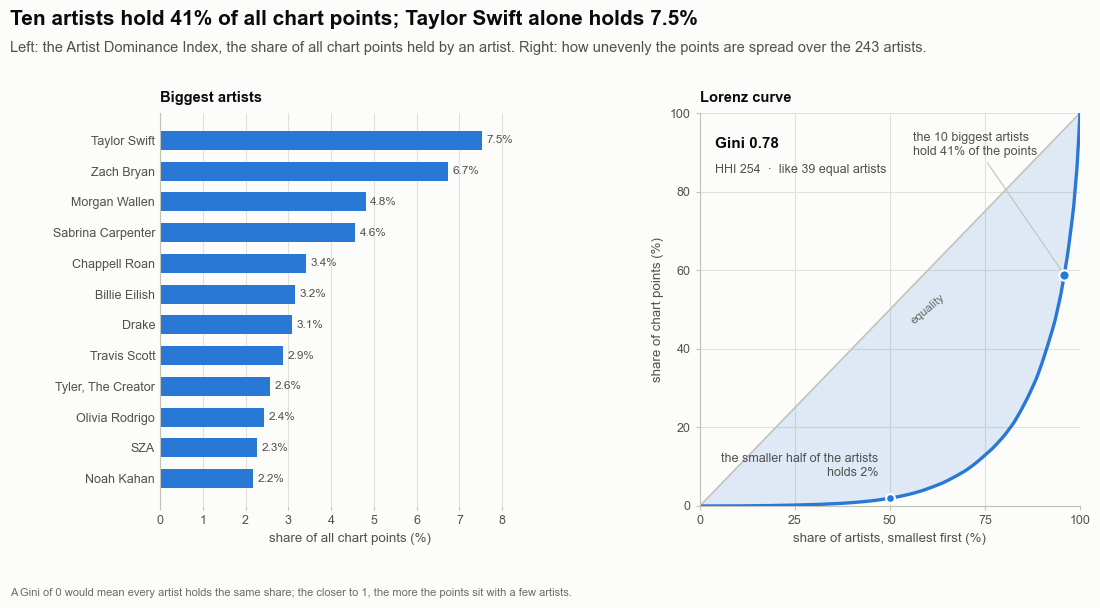

,primary_artist,songs,slot_days,chart_points,share_pct
0,Taylor Swift,96,2015,53293,7.53
1,Zach Bryan,38,1882,47692,6.74
2,Morgan Wallen,10,1669,34025,4.81
3,Sabrina Carpenter,14,967,32288,4.56
4,Chappell Roan,6,794,24100,3.41
5,Billie Eilish,12,729,22335,3.16
6,Drake,37,881,21781,3.08
7,Travis Scott,32,795,20315,2.87
8,"Tyler, The Creator",16,706,18150,2.56
9,Olivia Rodrigo,18,600,17172,2.43


In [20]:
# Figure 16 - the Artist Dominance Index (ADI) and the Lorenz curve of the chart
top_adi = artists.head(12).reset_index()
lx, ly = lorenz_curve(artists["chart_points"])
bottom_half = float(np.interp(0.5, lx, ly) * 100)
top10_x = (len(artists) - 10) / len(artists)
FACTS["art_bottom_half_pct"] = bottom_half
FACTS["art_leader"] = top_adi.loc[0, "primary_artist"]
FACTS["art_leader_pct"] = top_adi.loc[0, "share_pct"]
FACTS["art_second"] = top_adi.loc[1, "primary_artist"]
FACTS["art_second_pct"] = top_adi.loc[1, "share_pct"]
FACTS["art_twelfth_pct"] = top_adi.loc[11, "share_pct"]
FACTS["art_top10_artist_pct_of_artists"] = 10 / len(artists) * 100

fig, (ax1, ax2) = make_fig(11.5, 6.2, 1, 2, left=1.85, right=0.45, bottom=0.9, wspace=0.42, panel_titles=True, width_ratios=[1.0, 1],
                           title=f"Ten artists hold {FACTS['art_top10_pct']:.0f}% of all chart points; {FACTS['art_leader']} alone holds {FACTS['art_leader_pct']:.1f}%",
                           subtitle=f"Left: the Artist Dominance Index, the share of all chart points held by an artist. Right: how unevenly the points are spread over the {FACTS['artists_primary']} artists.",
                           note_text="A Gini of 0 would mean every artist holds the same share; the closer to 1, the more the points sit with a few artists.")
hbar(ax1, list(top_adi["primary_artist"]), top_adi["share_pct"], color=style.BLUE, fmt="{:.1f}%",
     label_chars=24, xlim=(0, top_adi["share_pct"].max() * 1.18))
ax1.set_xlabel("share of all chart points (%)")
panel_title(ax1, "Biggest artists")

ax2.plot([0, 100], [0, 100], color=style.AXIS, linewidth=1.2)
ax2.fill_between(lx * 100, ly * 100, lx * 100, color=style.BLUE, alpha=0.14, linewidth=0)
ax2.plot(lx * 100, ly * 100, color=style.BLUE, linewidth=2.4)
ax2.scatter([top10_x * 100], [np.interp(top10_x, lx, ly) * 100], s=55, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.5, zorder=4)
note(ax2, (top10_x * 100, np.interp(top10_x, lx, ly) * 100), f"the 10 biggest artists\nhold {FACTS['art_top10_pct']:.0f}% of the points", (56, 92), ha="left", size=9)
direct_label(ax2, 4, 94, f"Gini {FACTS['art_gini']:.2f}", ha="left", va="top", size=11, color=style.INK, weight="bold")
direct_label(ax2, 4, 87, f"HHI {FACTS['art_hhi']:.0f}  ·  like {FACTS['art_effective_n']:.0f} equal artists", ha="left", va="top", size=9)
direct_label(ax2, 47, bottom_half + 5, f"the smaller half of the artists\nholds {bottom_half:.0f}%", ha="right", va="bottom", size=9)
ax2.scatter([50], [bottom_half], s=40, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.5, zorder=4)
ax2.text(60, 50, "equality", rotation=40, fontsize=8.5, color=style.MUTED, ha="center", va="center")
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 100)
ax2.set_xticks([0, 25, 50, 75, 100])
ax2.set_xlabel("share of artists, smallest first (%)")
ax2.set_ylabel("share of chart points (%)")
panel_title(ax2, "Lorenz curve")
style_axes(ax2, grid="both")
save_fig(fig, "p4_16_adi_lorenz", FIG_DIR)
plt.show()

display(top_adi[["primary_artist", "songs", "slot_days", "chart_points", "share_pct"]].round(2))

**What to notice**

- Taylor Swift holds 7.5% of all chart points and Zach Bryan 6.7%. The top five artists hold 27%, the top ten 41% and the top 20 58%. Ten artists are 4.1% of all 243 artists.
- The smaller half of the artists holds only 2.0% of the points. HHI 254, effective number 39.3, Gini 0.78: the same story in three measures.

**What this code is.** Figure 17: the presence of the 15 biggest artists on the chart, day by day. One row per artist, one column per calendar day, coloured by how many of the artist's songs were on the chart that day; white means no song on the chart.

**Why we need it.** "Dominance over time" has two sides. Figure 16 gave the total; this strip chart shows when each artist was present and how many songs they had at once, which a total hides.

**What will happen.** The code counts songs per artist per day for the 15 biggest artists, builds the artist-by-day grid, draws it as an image and records the highest number of songs one artist had on a single day.

**Expected outcome.** A heat strip with long coloured stretches, white gaps, and a few dark spikes where an artist placed many songs at once (an album release).

**Motive.** Show that big artists reach their share in different ways: steadily, or in bursts.

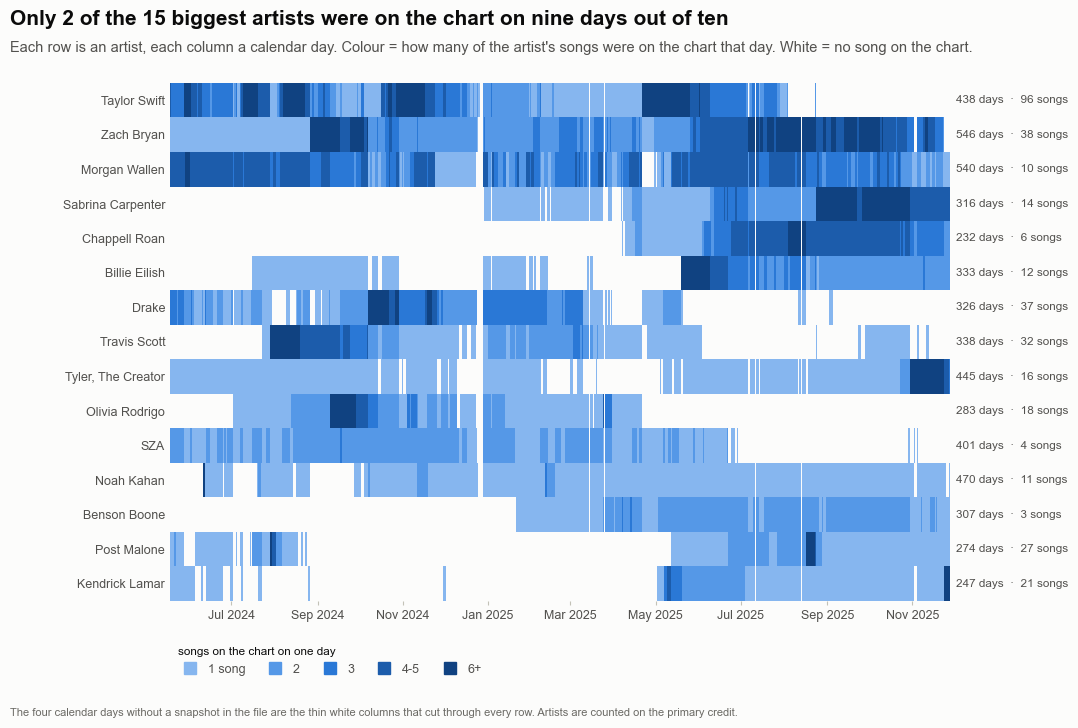

,primary_artist,songs,days_present,slot_days,share_pct
0,Taylor Swift,96,438,2015,7.50
1,Zach Bryan,38,546,1882,6.70
2,Morgan Wallen,10,540,1669,4.80
3,Sabrina Carpenter,14,316,967,4.60
4,Chappell Roan,6,232,794,3.40
5,Billie Eilish,12,333,729,3.20
6,Drake,37,326,881,3.10
7,Travis Scott,32,338,795,2.90
8,"Tyler, The Creator",16,445,706,2.60
9,Olivia Rodrigo,18,283,600,2.40


In [21]:
# Figure 17 - the presence of the 15 biggest artists on the chart, day by day
import matplotlib.dates as mdates
from matplotlib.colors import BoundaryNorm, ListedColormap

big15 = artists.head(15).reset_index()
slots = (playlist[playlist["primary_artist"].isin(big15["primary_artist"])]
         .groupby(["primary_artist", "date"]).size().unstack("date")
         .reindex(index=big15["primary_artist"], columns=dim_date["date"]))                       # songs of the artist on the chart that day (empty = none)
cells = np.ma.masked_invalid(slots.to_numpy(dtype=float))

levels = [1, 2, 3, 4, 6, 100]                                                                      # 1, 2, 3, 4-5, 6 or more songs on one day
level_names = ["1 song", "2", "3", "4-5", "6+"]
strip_map = ListedColormap(style.AGE_BAND_COLORS).with_extremes(bad=style.SURFACE)
strip_norm = BoundaryNorm(levels, strip_map.N)

FACTS["strip_artist_peak_songs"] = int(np.nanmax(cells))
peak_day = slots.max().idxmax()
FACTS["strip_artist_peak_name"] = slots[peak_day].idxmax()
FACTS["strip_artist_peak_date"] = f"{peak_day:%d %b %Y}"
FACTS["strip_big15_days_min"] = int(big15["days_present"].min())
FACTS["strip_big15_days_max"] = int(big15["days_present"].max())
FACTS["strip_artists_90pct"] = int((big15["days_present"] >= 0.9 * FACTS["snapshots"]).sum())

fig, ax = make_fig(11.5, 7.4, left=1.95, right=1.75, bottom=1.15,
                   title=f"Only {FACTS['strip_artists_90pct']} of the 15 biggest artists were on the chart on nine days out of ten",
                   subtitle="Each row is an artist, each column a calendar day. Colour = how many of the artist's songs were on the chart that day. White = no song on the chart.",
                   note_text="The four calendar days without a snapshot in the file are the thin white columns that cut through every row. Artists are counted on the primary credit.")
start, end = mdates.date2num(dim_date["date"].min()), mdates.date2num(dim_date["date"].max()) + 1
ax.imshow(cells, aspect="auto", cmap=strip_map, norm=strip_norm, interpolation="nearest", extent=[start, end, len(big15), 0])
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_yticks(np.arange(len(big15)) + 0.5)
ax.set_yticklabels([short(name, 24) for name in big15["primary_artist"]], fontsize=9)
ax.tick_params(axis="y", length=0)
for side in ("left", "bottom", "top", "right"):
    ax.spines[side].set_visible(False)
for i, row in big15.iterrows():
    ax.text(1.008, 1 - (i + 0.5) / len(big15), f"{row.days_present} days  ·  {row.songs} songs", transform=ax.transAxes, fontsize=8.5,
            color=style.INK_2, va="center", ha="left")
swatch_legend(ax, list(zip(level_names, style.AGE_BAND_COLORS)), loc="upper left", ncol=5, bbox_to_anchor=(0.0, -0.075), frameon=False,
              title="songs on the chart on one day", title_fontsize=8.5, alignment="left")
save_fig(fig, "p4_17_artist_strips", FIG_DIR)
plt.show()

display(big15[["primary_artist", "songs", "days_present", "slot_days", "share_pct"]].round(1))

**What to notice**

- Only 2 of the 15 biggest artists were on the chart on at least nine days out of ten. The 15 range from 232 to 546 days present.
- The largest number of songs one of these artists had on the chart at once was 31, by Taylor Swift on 21 Apr 2025 (the date as recorded in the file). Spikes like this are album releases.

**What this code is.** Figure 18, two panels. Top: a heat map of the monthly share of chart points for every artist that led the chart in at least one month; the cell of each month's leader is bold. Bottom: the effective number of artists per month, a line that says "the month's chart behaves like this many equal artists".

**Why we need it.** Dominance changes from month to month. The top panel says who led, the bottom panel says how widely the chart was shared, which is the HHI turned into a number that is easy to read.

**What will happen.** The code sums chart points per artist and month, finds each month's leader, calculates HHI and effective number per month with the tested `period_shares` and `period_concentration` functions, and draws the two panels one above the other.

**Expected outcome.** A heat map with a few bright cells (months where one artist dominated) and a wavy line below it.

**Motive.** Show dominance as a movie, not a snapshot.

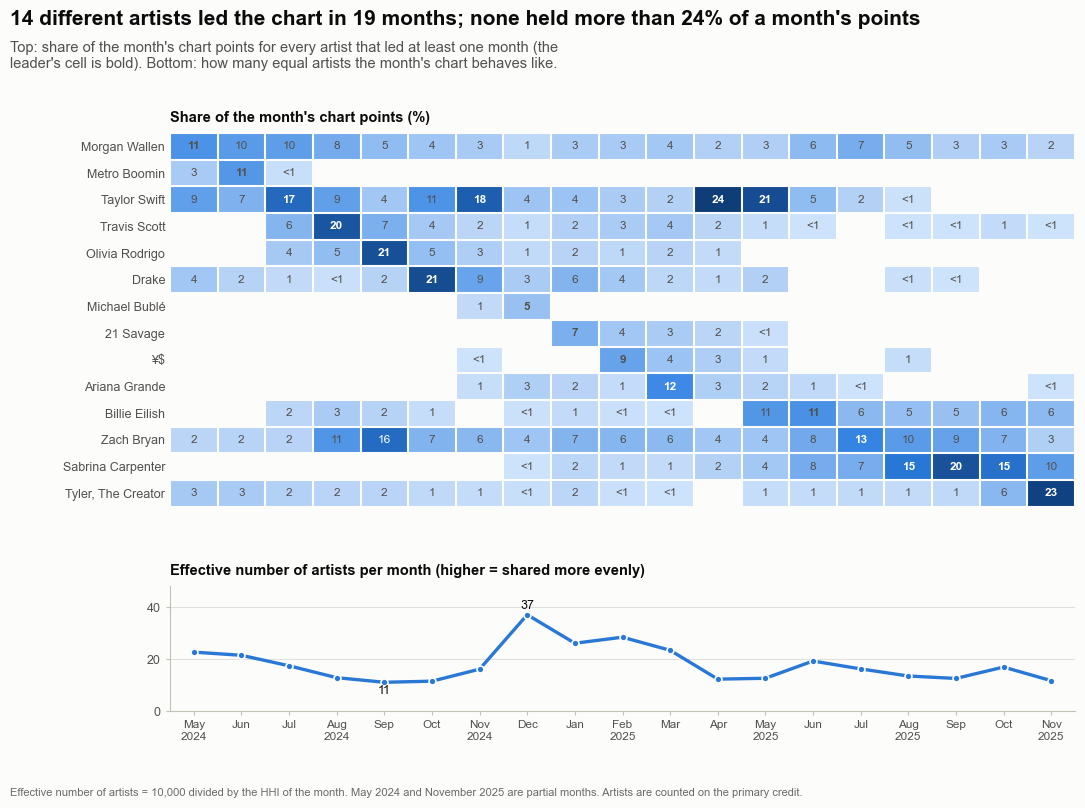

,year_month,holders,hhi,top1_pct,effective_number,leader,leader_share
0,2024-05,43,440.90,11.10,22.70,Morgan Wallen,11.10
1,2024-06,49,465.80,10.50,21.50,Metro Boomin,10.50
2,2024-07,65,574.20,16.80,17.40,Taylor Swift,16.80
3,2024-08,45,779.10,19.60,12.80,Travis Scott,19.60
4,2024-09,50,903.40,20.60,11.10,Olivia Rodrigo,20.60
5,2024-10,49,870.20,21.30,11.50,Drake,21.30
6,2024-11,71,620.10,18.30,16.10,Taylor Swift,18.30
7,2024-12,74,269.60,4.70,37.10,Michael Bublé,4.70
8,2025-01,58,383.00,7.20,26.10,21 Savage,7.20
9,2025-02,53,351.70,8.90,28.40,¥$,8.90


In [22]:
# Figure 18 - dominance over time: who led the chart in each month, and how many artists really shared it
monthly = period_shares(playlist, "year_month", "primary_artist", "chart_points")
monthly_summary = period_concentration(monthly, "year_month", "primary_artist")
month_leaders = monthly.loc[monthly.groupby("year_month")["share_pct"].idxmax()].set_index("year_month")
months = list(monthly_summary["year_month"])
first_led = month_leaders.reset_index().groupby("primary_artist")["year_month"].min().sort_values()     # artists in the order in which they first led
leaders_order = list(first_led.index)
matrix = (monthly.pivot(index="primary_artist", columns="year_month", values="share_pct")
          .reindex(index=leaders_order, columns=months).fillna(0.0))

FACTS["lead_months"] = len(months)
FACTS["lead_distinct"] = len(leaders_order)
FACTS["lead_max_share"] = float(month_leaders["share_pct"].max())
FACTS["lead_max_share_artist"] = month_leaders.loc[month_leaders["share_pct"].idxmax(), "primary_artist"]
FACTS["lead_max_share_month"] = month_leaders["share_pct"].idxmax()
FACTS["lead_min_share"] = float(month_leaders["share_pct"].min())
FACTS["lead_months_swift"] = int((month_leaders["primary_artist"] == "Taylor Swift").sum())
FACTS["lead_months_carpenter"] = int((month_leaders["primary_artist"] == "Sabrina Carpenter").sum())
FACTS["lead_hhi_min"] = float(monthly_summary["hhi"].min())
FACTS["lead_hhi_max"] = float(monthly_summary["hhi"].max())
FACTS["lead_eff_min"] = float(monthly_summary["effective_number"].min())
FACTS["lead_eff_max"] = float(monthly_summary["effective_number"].max())
FACTS["lead_eff_min_month"] = monthly_summary.loc[monthly_summary["effective_number"].idxmin(), "year_month"]
FACTS["lead_eff_max_month"] = monthly_summary.loc[monthly_summary["effective_number"].idxmax(), "year_month"]
FACTS["lead_months_over_20"] = int((month_leaders["share_pct"] >= 20).sum())

fig, (ax1, ax2) = make_fig(11.5, 8.2, 2, 1, left=1.95, right=0.5, bottom=0.85, hspace=0.32, height_ratios=[3.0, 1.0], panel_titles=True,
                           title=f"{FACTS['lead_distinct']} different artists led the chart in {FACTS['lead_months']} months; none held more than {FACTS['lead_max_share']:.0f}% of a month's points",
                           subtitle="Top: share of the month's chart points for every artist that led at least one month (the leader's cell is bold). Bottom: how many equal artists the month's chart behaves like.",
                           note_text="Effective number of artists = 10,000 divided by the HHI of the month. May 2024 and November 2025 are partial months. Artists are counted on the primary credit.")
blank_blue = style.SEQUENTIAL_BLUE.with_extremes(bad=style.SURFACE)                                    # a month without a single point is drawn blank
image = ax1.imshow(np.ma.masked_where(matrix.to_numpy() == 0, matrix.to_numpy()), aspect="auto", cmap=blank_blue, vmin=0, vmax=25, interpolation="nearest")
ax1.set_yticks(range(len(leaders_order)))
ax1.set_yticklabels([short(name, 24) for name in leaders_order], fontsize=9)
ax1.set_xticks(range(len(months)))
ax1.set_xticklabels([])
ax1.tick_params(length=0)
for side in ("left", "bottom", "top", "right"):
    ax1.spines[side].set_visible(False)
for i, name in enumerate(leaders_order):
    for j, month in enumerate(months):
        value = matrix.iloc[i, j]
        if value > 0:
            is_leader = month_leaders.loc[month, "primary_artist"] == name
            dark = value >= 12
            ax1.text(j, i, "<1" if value < 0.5 else f"{value:.0f}", ha="center", va="center", fontsize=8.5, color="white" if dark else style.INK_2,
                     fontweight="bold" if is_leader else "normal")
ax1.hlines(np.arange(-0.5, len(leaders_order)), -0.5, len(months) - 0.5, color=style.SURFACE, linewidth=1.5)
ax1.vlines(np.arange(-0.5, len(months)), -0.5, len(leaders_order) - 0.5, color=style.SURFACE, linewidth=1.5)
panel_title(ax1, "Share of the month's chart points (%)")

x = np.arange(len(months))
ax2.plot(x, monthly_summary["effective_number"], color=style.BLUE, linewidth=2.4, marker="o", markersize=5, markeredgecolor=style.SURFACE, markeredgewidth=1.2)
low_i, high_i = int(monthly_summary["effective_number"].idxmin()), int(monthly_summary["effective_number"].idxmax())
for i in (low_i, high_i):
    direct_label(ax2, i, monthly_summary.loc[i, "effective_number"] + (3.2 if i == high_i else -3.4), f"{monthly_summary.loc[i, 'effective_number']:.0f}",
                 ha="center", va="center", size=9, color=style.INK)
ax2.set_xlim(-0.5, len(months) - 0.5)
ax2.set_ylim(0, 48)
ax2.set_xticks(x)
ax2.set_xticklabels([pd.Period(m).strftime("%b\n%Y") if (k % 3 == 0) else pd.Period(m).strftime("%b") for k, m in enumerate(months)], fontsize=8.5)
style_axes(ax2, grid="y")
panel_title(ax2, "Effective number of artists per month (higher = shared more evenly)")
save_fig(fig, "p4_18_dominance_over_time", FIG_DIR)
plt.show()

display(monthly_summary.round(1).assign(leader=month_leaders["primary_artist"].to_numpy(), leader_share=month_leaders["share_pct"].round(1).to_numpy()))

**What to notice**

- 14 different artists led the chart in at least one of the 19 months. Taylor Swift led 4 of them and Sabrina Carpenter 3.
- The biggest monthly share was 23.6% (Taylor Swift, April 2025). A leader held at least 20% in 6 months and as little as 4.7% in the most shared month.
- The effective number of artists per month ran from 11.1 (September 2024, the most concentrated month) to 37.1 (December 2024, the most shared). The first and last months of the file are partial months.

**What this code is.** Figure 19: a scatter of artists with at least three songs. Across: songs placed (log scale). Up: average days on the chart per song (log scale). Diagonal lines mark equal total presence, so artists on the same line have been on the chart for the same number of song-days.

**Why we need it.** An artist can win chart share in two ways: place many songs that each stay a short time (breadth), or place few songs that stay long (depth). The brief's question "what makes an artist dominate" starts here.

**What will happen.** The code computes days per song for every artist, draws the log-log scatter with the diagonal lines, labels a few artists that show the two routes, and stores their numbers as facts together with the Spearman correlation between songs placed and days per song.

**Expected outcome.** A cloud of dots sloping downward from left to right (more songs, fewer days each), with a few labelled artists far above or below the cloud.

**Motive.** Turn "dominance" into two causes that a label can act on differently.

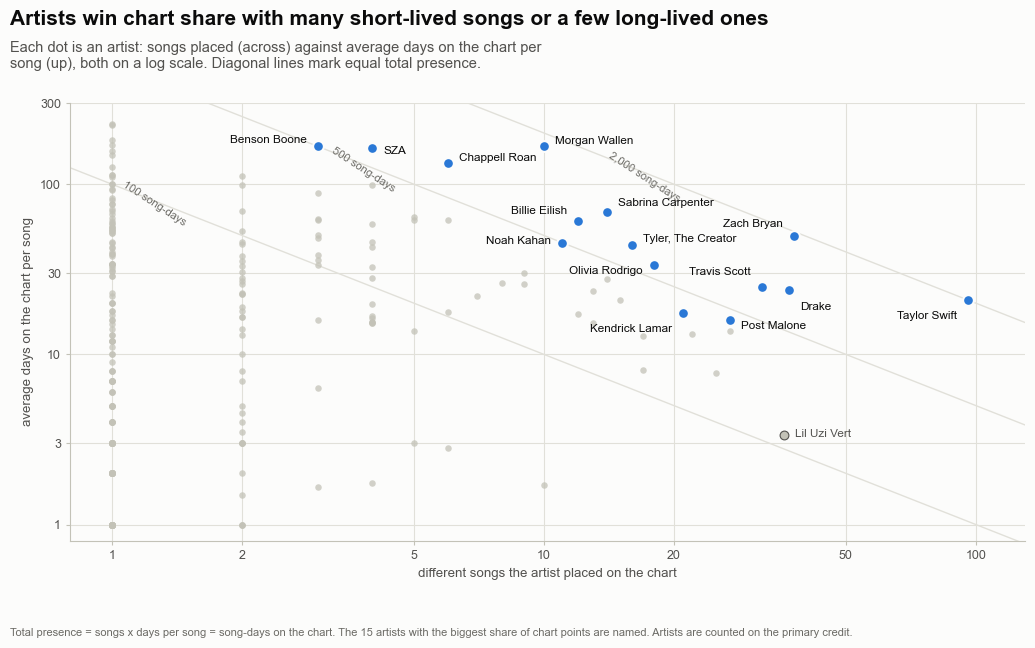

,songs,slot_days,days_per_song,share_pct
primary_artist,,,,
Taylor Swift,96,2015,21.00,7.50
Zach Bryan,38,1882,49.50,6.70
Morgan Wallen,10,1669,166.90,4.80
Sabrina Carpenter,14,967,69.10,4.60
Chappell Roan,6,794,132.30,3.40
Billie Eilish,12,729,60.80,3.20
Drake,37,881,23.80,3.10
Travis Scott,32,795,24.80,2.90
"Tyler, The Creator",16,706,44.10,2.60


In [23]:
# Figure 19 - two routes to a big share of the chart: many songs with short stays, or a few songs that stay
big_artists = artists.head(15)
others = artists.drop(big_artists.index)
rho_songs_days = stats.spearmanr(artists.loc[artists["songs"] >= 3, "songs"], artists.loc[artists["songs"] >= 3, "days_per_song"])[0]

FACTS["route_corr"] = rho_songs_days
FACTS["route_artists_3plus"] = int((artists["songs"] >= 3).sum())
FACTS["route_swift_dps"] = float(artists.loc["Taylor Swift", "days_per_song"])
FACTS["route_morgan_songs"] = int(artists.loc["Morgan Wallen", "songs"])
FACTS["route_morgan_dps"] = float(artists.loc["Morgan Wallen", "days_per_song"])
FACTS["route_boone_songs"] = int(artists.loc["Benson Boone", "songs"])
FACTS["route_boone_dps"] = float(artists.loc["Benson Boone", "days_per_song"])
FACTS["route_uzi_songs"] = int(artists.loc["Lil Uzi Vert", "songs"])
FACTS["route_uzi_dps"] = float(artists.loc["Lil Uzi Vert", "days_per_song"])
FACTS["route_chart_dps"] = float(len(playlist) / FACTS["songs"])

fig, ax = make_fig(11, 6.6, left=0.95, right=0.5, bottom=0.95,
                   title="Artists win chart share with many short-lived songs or a few long-lived ones",
                   subtitle="Each dot is an artist: songs placed (across) against average days on the chart per song (up), both on a log scale. Diagonal lines mark equal total presence.",
                   note_text="Total presence = songs x days per song = song-days on the chart. The 15 artists with the biggest share of chart points are named. Artists are counted on the primary credit.")
ax.scatter(others["songs"], others["days_per_song"], s=22, color=style.AXIS, alpha=0.75, linewidth=0, zorder=2)
ax.scatter(big_artists["songs"], big_artists["days_per_song"], s=60, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.5, zorder=4)
xs = np.array([0.8, 130])
for presence in (100, 500, 2000):
    ax.plot(xs, presence / xs, color=style.GRID, linewidth=1.0, zorder=1)
for presence, (px, py) in {100: (1.05, 95), 500: (3.2, 150), 2000: (14, 140)}.items():
    ax.text(px, py, f"{presence:,} song-days", rotation=-33, fontsize=8, color=style.MUTED, ha="left", va="bottom", rotation_mode="anchor")
offsets = {"Taylor Swift": (-8, -12, "right"), "Zach Bryan": (-8, 9, "right"), "Morgan Wallen": (8, 4, "left"), "Sabrina Carpenter": (8, 6, "left"),
           "Chappell Roan": (8, 4, "left"), "Billie Eilish": (-8, 7, "right"), "Drake": (8, -12, "left"), "Travis Scott": (-8, 11, "right"),
           "Tyler, The Creator": (8, 4, "left"), "Olivia Rodrigo": (-8, -4, "right"), "SZA": (8, -2, "left"), "Noah Kahan": (-8, 2, "right"),
           "Benson Boone": (-8, 4, "right"), "Post Malone": (8, -4, "left"), "Kendrick Lamar": (-8, -12, "right")}
for name, row in big_artists.iterrows():
    dx, dy, ha = offsets[name]
    direct_label(ax, row["songs"], row["days_per_song"], name, dx=dx, dy=dy, ha=ha, va="center", size=8.5, color=style.INK)
direct_label(ax, 36, 3.4, "Lil Uzi Vert", dx=8, dy=0, ha="left", va="center", size=8.5)
ax.scatter([36], [artists.loc["Lil Uzi Vert", "days_per_song"]], s=40, color=style.AXIS, edgecolor=style.INK_2, linewidth=0.8, zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(0.8, 130)
ax.set_ylim(0.8, 300)
ax.set_xticks([1, 2, 5, 10, 20, 50, 100])
ax.set_yticks([1, 3, 10, 30, 100, 300])
ax.xaxis.set_major_formatter(THOUSANDS)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.minorticks_off()
ax.set_xlabel("different songs the artist placed on the chart")
ax.set_ylabel("average days on the chart per song")
style_axes(ax, grid="both")
save_fig(fig, "p4_19_breadth_vs_depth", FIG_DIR)
plt.show()

display(artists.head(15)[["songs", "slot_days", "days_per_song", "share_pct"]].round(1))

**What to notice**

- Across the 63 artists with at least three songs, the number of songs placed and the days per song have a Spearman correlation of -0.23: artists that place more songs tend to see each song stay for a shorter time.
- The chart average is 29 days per song. Morgan Wallen placed 10 songs that stayed 167 days each on average, Benson Boone 3 songs at 169 days: the depth route. Taylor Swift averages 21 days per song over 96 songs and Lil Uzi Vert 3.4 days over 36 songs: the breadth route, where the share comes from the number of songs.

**What this code is.** Figure 20, two panels. Left: days at number one for the biggest holders. Right: song-days in the top 10 for the biggest holders. Everybody else is added up in grey.

**Why we need it.** The very top of the chart is where attention is. Every day has exactly one number one and ten top-10 places, so the shares can be read as exact portions of a fixed pie.

**What will happen.** The code counts, for each primary artist, the days at number one and the song-days in positions 1 to 10, shows the ten biggest holders in each panel, groups the rest, and calculates the Gini of the top-10 holders.

**Expected outcome.** Two bar charts with ten coloured bars and one grey bar each; the left panel is dominated by a few names.

**Motive.** Show who owns the top of the chart, which is a different question from who owns the chart as a whole.

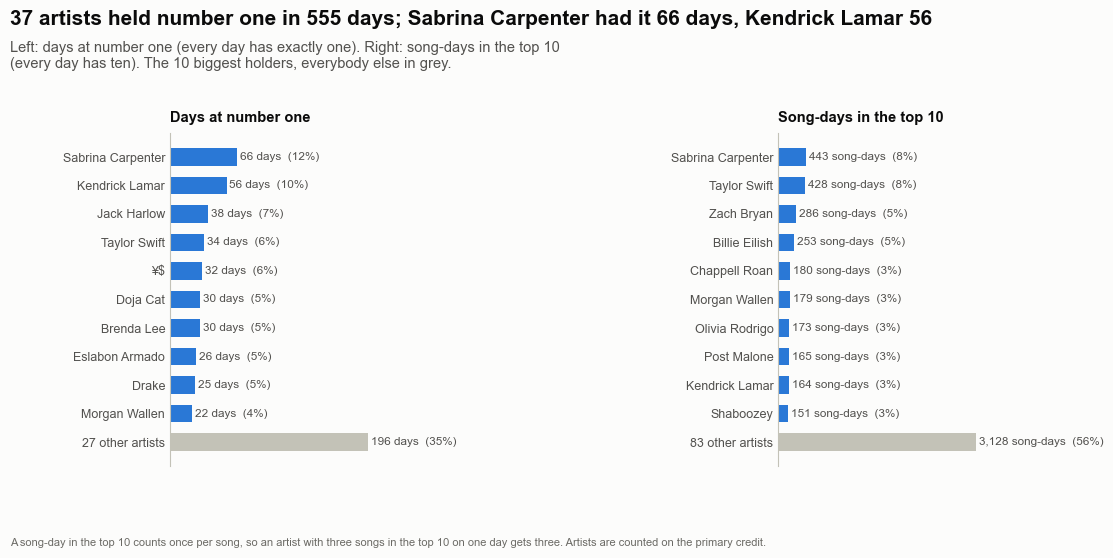

,number_one_days,top10_song_days
primary_artist,,
Sabrina Carpenter,66,443
Kendrick Lamar,56,164
Jack Harlow,38,105
Taylor Swift,34,428
¥$,32,84
Doja Cat,30,147
Brenda Lee,30,37
Eslabon Armado,26,69


In [24]:
# Figure 20 - who holds the very top of the chart: days at number one and days in the top 10
no1 = artists["number_one_days"].sort_values(ascending=False)
top10 = artists["top10_slot_days"].sort_values(ascending=False)
no1_holders = int((no1 > 0).sum())
top10_holders = int((top10 > 0).sum())
no1_songs = int(playlist.loc[playlist["is_number_one"], "track_id"].nunique())
top10_songs = int(playlist.loc[playlist["in_top10"], "track_id"].nunique())

FACTS["top_no1_artists"] = no1_holders
FACTS["top_no1_songs"] = no1_songs
FACTS["top_no1_first"] = no1.index[0]
FACTS["top_no1_first_days"] = int(no1.iloc[0])
FACTS["top_no1_first_pct"] = no1.iloc[0] / FACTS["snapshots"] * 100
FACTS["top_no1_second"] = no1.index[1]
FACTS["top_no1_second_days"] = int(no1.iloc[1])
FACTS["top_no1_top5_pct"] = no1.iloc[:5].sum() / FACTS["snapshots"] * 100
FACTS["top_top10_artists"] = top10_holders
FACTS["top_top10_songs"] = top10_songs
FACTS["top_top10_first"] = top10.index[0]
FACTS["top_top10_first_days"] = int(top10.iloc[0])
FACTS["top_top10_first_pct"] = top10.iloc[0] / top10.sum() * 100
FACTS["top_top10_second"] = top10.index[1]
FACTS["top_top10_second_days"] = int(top10.iloc[1])
FACTS["top_top10_top10_pct"] = top10.iloc[:10].sum() / top10.sum() * 100
FACTS["top_top10_gini"] = gini(top10[top10 > 0])
FACTS["top_top10_slots"] = int(top10.sum())

fig, (ax1, ax2) = make_fig(11.5, 5.7, 1, 2, left=1.95, right=0.5, bottom=0.8, wspace=1.05, panel_titles=True,
                           title=f"{no1_holders} artists held number one in {FACTS['snapshots']} days; {FACTS['top_no1_first']} had it {FACTS['top_no1_first_days']} days, {FACTS['top_no1_second']} {FACTS['top_no1_second_days']}",
                           subtitle="Left: days at number one (every day has exactly one). Right: song-days in the top 10 (every day has ten). The 10 biggest holders, everybody else in grey.",
                           note_text="A song-day in the top 10 counts once per song, so an artist with three songs in the top 10 on one day gets three. Artists are counted on the primary credit.")
for ax, series, holders, unit, total in ((ax1, no1, no1_holders, "days", FACTS["snapshots"]), (ax2, top10, top10_holders, "song-days", top10.sum())):
    head = series.head(10)
    rest_total = series.iloc[10:].sum()
    rest_count = int((series.iloc[10:] > 0).sum())
    labels = list(head.index) + [f"{rest_count} other artists"]
    values = list(head.to_numpy()) + [rest_total]
    colors = [style.BLUE] * 10 + [style.AXIS]
    hbar(ax, labels, values, colors=colors, show_values=False, xlim=(0, max(values) * 1.5), label_chars=24)
    for yi, value in enumerate(values):
        ax.text(value + max(values) * 0.015, yi, f"{value:,.0f} {unit}  ({value / total * 100:.0f}%)", ha="left", va="center", fontsize=8.5, color=style.INK_2)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.grid(False)
panel_title(ax1, "Days at number one")
panel_title(ax2, "Song-days in the top 10")
save_fig(fig, "p4_20_top_of_chart", FIG_DIR)
plt.show()

display(pd.DataFrame({"number_one_days": no1.head(8), "top10_song_days": top10.reindex(no1.head(8).index)}))

**What to notice**

- 37 artists, with 54 different songs, held number one in the 555 days. Sabrina Carpenter had it for 66 days (12%) and Kendrick Lamar for 56; the top five holders together account for 41% of the days.
- The 5,550 song-days in the top 10 belong to 306 songs by 93 artists. Sabrina Carpenter had 443 of them (8.0%), Taylor Swift 428, and the ten biggest artists hold 44% (Gini 0.62).

## Section 6 - Popularity analytics

The fourth block of the brief is about the popularity score (0 to 100) that the file carries for every song on every day: how it
relates to the chart position, how it is distributed in the Top 10, 11-20 and 21-50, how it moved over time, and whether a song
with a stable score also has a stable position. Two cautions apply to every figure here. First, a score of 0 was treated as
missing in Phase 2 and repaired from the same song's other days, so the repaired values are inside the numbers (and counted in
a footnote). Second, a song's days are not independent of each other, which is why this section only describes and leaves the
formal tests to Phase 5.

**What this code is.** Figure 21, two panels. Left: every song-day as a point on a grid of chart position (across) and popularity score (up), darker where more song-days fall, with the median score and the middle half drawn as lines. Right: the strength of the link between popularity and position, measured three ways.

**Why we need it.** "Popularity versus rank correlation" is a named item in the brief. One correlation number would hide a lot, so the same link is measured three times: across all song-days, across songs (each song's averages), and within songs (does a song score higher on its better days).

**What will happen.** The code uses the Spearman rank correlation (it does not assume a straight line), applies a square-root colour scale to the grid so that sparse areas stay visible, draws the median and quartile lines per position, and stores the three correlations and a few medians as facts. Scores below 61 are not drawn (1.0% of song-days), but they stay in every calculation.

**Expected outcome.** Left: a dense band of dark cells at the top that slopes slightly downward to the right. Right: three short bars, all well below 0.5.

**Motive.** Answer the brief's question honestly: popularity and position are related, but loosely.

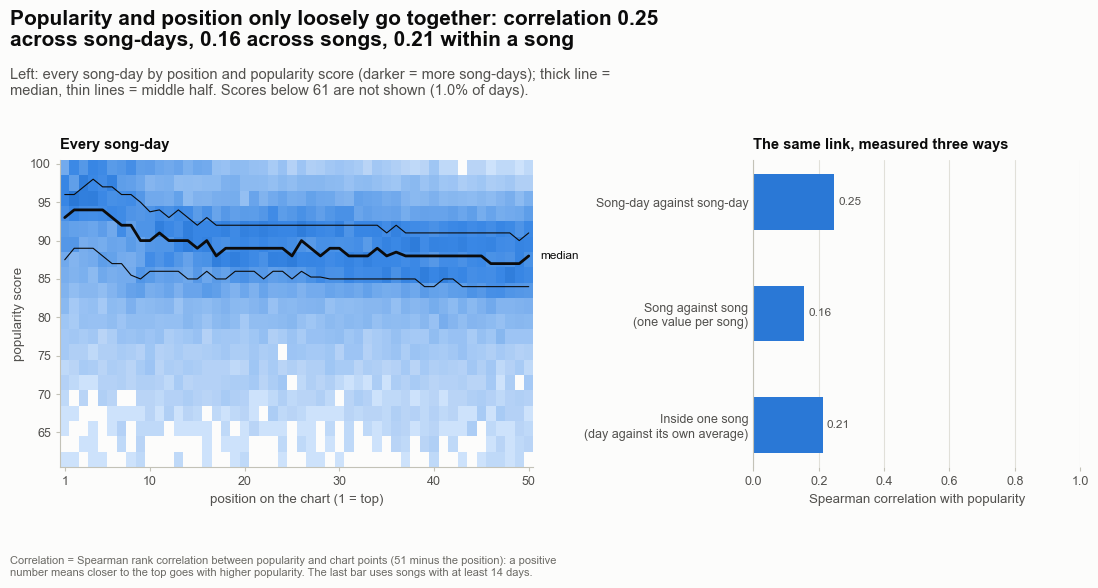

,0.25,0.50,0.75
position,,,
1,87.50,93.00,96.00
2,89.00,94.00,96.00
3,89.00,94.00,97.00
5,88.00,94.00,97.00
10,86.00,90.00,93.80
11,86.00,91.00,94.00
20,86.00,89.00,92.00
30,85.00,89.00,92.00
40,84.00,88.00,91.00


In [25]:
# Figure 21 - popularity and chart position: how closely do they go together?
from matplotlib.colors import LinearSegmentedColormap, PowerNorm

LIGHT_BLUE = LinearSegmentedColormap.from_list("light_blue", [style.BLUE_STEPS[k] for k in (100, 150, 200, 250, 300, 350, 400, 450)])   # stops before the dark steps so that the black lines stay readable

rated = playlist.dropna(subset=["popularity_clean"])                                                      # song-days that have a popularity score
low_cut = 61                                                                                              # the picture shows scores from 61 upwards (two scores per colour block)
shown = rated[rated["popularity_clean"] >= low_cut]

songs_with_score = dim_track.dropna(subset=["avg_popularity"])
rho_rows = stats.spearmanr(rated["chart_points"], rated["popularity_clean"])[0]                           # chart points = 51 - position: bigger = closer to the top
rho_between = stats.spearmanr(51 - songs_with_score["avg_rank"], songs_with_score["avg_popularity"])[0]   # song against song (every song counts once)
long_songs = rated[rated.groupby("track_id")["track_id"].transform("size") >= 14]
within_pop = long_songs["popularity_clean"] - long_songs.groupby("track_id")["popularity_clean"].transform("mean")
within_pts = long_songs["chart_points"] - long_songs.groupby("track_id")["chart_points"].transform("mean")
rho_within = stats.spearmanr(within_pts, within_pop)[0]                                                    # one song against its own average

by_position = rated.groupby("position")["popularity_clean"].quantile([0.25, 0.5, 0.75]).unstack()
FACTS["pop_rows_scored"] = len(rated)
FACTS["pop_low_cut"] = low_cut
FACTS["pop_below_cut_pct"] = float((rated["popularity_clean"] < low_cut).mean() * 100)
FACTS["pop_rho_rows"] = rho_rows
FACTS["pop_rho_between"] = rho_between
FACTS["pop_rho_within"] = rho_within
FACTS["pop_within_songs"] = int(long_songs["track_id"].nunique())
FACTS["pop_median_pos1"] = float(by_position.loc[1, 0.5])
FACTS["pop_median_pos5"] = float(by_position.loc[5, 0.5])
FACTS["pop_median_pos10"] = float(by_position.loc[10, 0.5])
FACTS["pop_median_pos11"] = float(by_position.loc[11, 0.5])
FACTS["pop_median_pos50"] = float(by_position.loc[50, 0.5])
FACTS["pop_median_pos11_50_range"] = float(by_position.loc[11:50, 0.5].max() - by_position.loc[11:50, 0.5].min())

fig, (ax1, ax2) = make_fig(11.5, 6.0, 1, 2, left=0.85, right=0.45, bottom=0.95, wspace=0.55, panel_titles=True, width_ratios=[1.45, 1],
                           title=f"Popularity and position only loosely go together: correlation {FACTS['pop_rho_rows']:.2f} across song-days, {FACTS['pop_rho_between']:.2f} across songs, {FACTS['pop_rho_within']:.2f} within a song",
                           subtitle=f"Left: every song-day by position and popularity score (darker = more song-days); thick line = median, thin lines = middle half. Scores below {low_cut} are not shown ({FACTS['pop_below_cut_pct']:.1f}% of days).",
                           note_text="Correlation = Spearman rank correlation between popularity and chart points (51 minus the position): a positive number means closer to the top goes with higher popularity. The last bar uses songs with at least 14 days.")
counts, xedges, yedges, image = ax1.hist2d(shown["position"], shown["popularity_clean"], bins=[np.arange(0.5, 51, 1), np.arange(low_cut - 0.5, 101, 2)],
                                           cmap=LIGHT_BLUE.with_extremes(under=style.SURFACE), norm=PowerNorm(0.5, vmin=1))
ax1.plot(by_position.index, by_position[0.5], color=style.INK, linewidth=2.0, zorder=4)
ax1.plot(by_position.index, by_position[0.25], color=style.INK, linewidth=0.8, zorder=4)
ax1.plot(by_position.index, by_position[0.75], color=style.INK, linewidth=0.8, zorder=4)
direct_label(ax1, 51.2, by_position.loc[50, 0.5], "median", ha="left", va="center", size=8.5, color=style.INK)
ax1.set_xlim(0.5, 50.5)
ax1.set_ylim(low_cut - 0.5, 100.5)
ax1.set_xticks([1, 10, 20, 30, 40, 50])
ax1.set_xlabel("position on the chart (1 = top)")
ax1.set_ylabel("popularity score")
ax1.tick_params(length=3)
for side in ("top", "right"):
    ax1.spines[side].set_visible(False)
panel_title(ax1, "Every song-day")

labels = ["Song-day against song-day", "Song against song\n(one value per song)", "Inside one song\n(day against its own average)"]
hbar(ax2, labels, [rho_rows, rho_between, rho_within], color=style.BLUE, fmt="{:.2f}", label_chars=None, xlim=(0, 1), bar_height=0.5)
ax2.set_xlabel("Spearman correlation with popularity")
panel_title(ax2, "The same link, measured three ways")
save_fig(fig, "p4_21_popularity_vs_position", FIG_DIR)
plt.show()

display(by_position.loc[[1, 2, 3, 5, 10, 11, 20, 30, 40, 50]].round(1))

**What to notice**

- Across the 27,732 song-days that have a score, the Spearman correlation between position and popularity is 0.25 (a better position goes with a higher score). Across songs it is 0.16, and within songs, for the 335 songs with at least 14 days, 0.21.
- The median score is 93 at position 1, 94 at position 5, 90 at position 10 and 88 at position 50. Position by position, the medians from 11 to 50 stay inside a band of 4 points: a place on the chart says little about the score a song has on that day.

**What this code is.** Figure 22: the distribution of the popularity score in three stacked panels, one for song-days in the Top 10, one for positions 11-20 and one for positions 21-50. Each panel shows the share of song-days at each score, with a line at the median.

**Why we need it.** The brief asks for the popularity distribution across the Top 10, 20 and 50. The three position groups do not overlap, so for "the top 20" read the first two panels together. Showing the whole distribution, not only an average, reveals differences in spread.

**What will happen.** The code splits the scored song-days by rank tier, counts them per score, draws the three histograms on one scale, and stores medians, quartiles, spread and the share of days at 95 or above for each group. It also calculates a Kruskal-Wallis statistic as a size hint.

**Expected outcome.** Three histograms stacked on one score axis: the Top 10 piled up towards 100, the other two centred near 88 to 90 with the 21-50 panel a little lower. Every bar holds exactly two whole scores.

**Motive.** Compare whole distributions, not only averages, and keep the formal test for Phase 5.

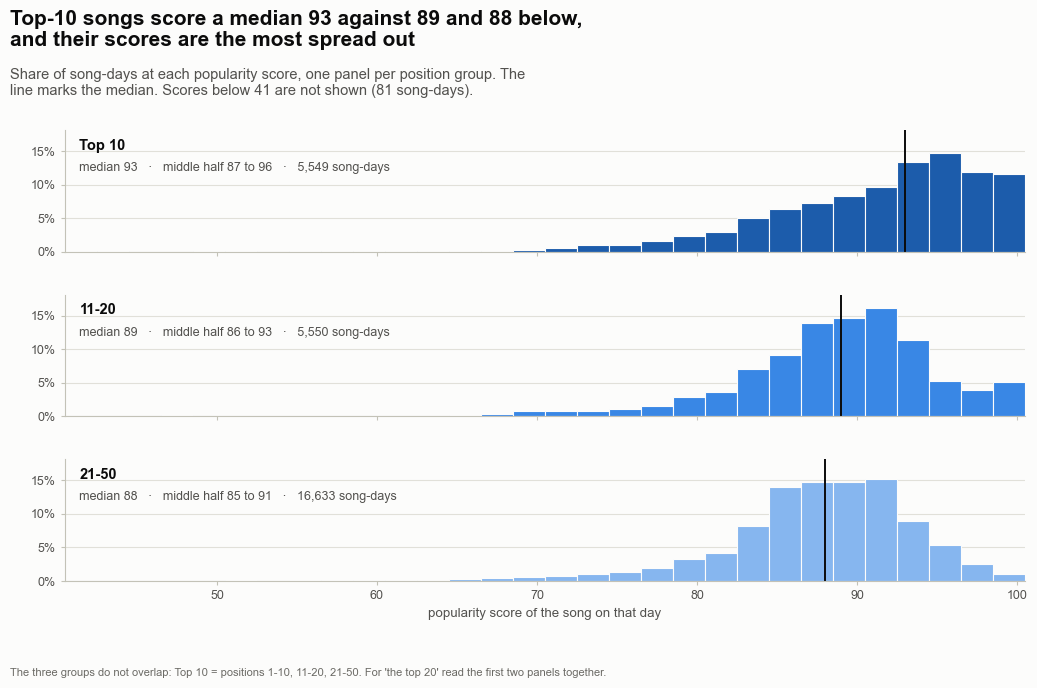

,count,mean,std,min,10%,25%,50%,75%,90%,max
rank_tier,,,,,,,,,,
Top 10,"5,549.00",90.70,8.80,3.00,81.00,87.00,93.00,96.00,99.00,100.00
11-20,"5,550.00",88.40,7.70,25.00,81.00,86.00,89.00,93.00,96.00,100.00
21-50,"16,633.00",87.30,7.00,8.00,80.00,85.00,88.00,91.00,94.00,100.00


In [26]:
# Figure 22 - the distribution of popularity in the Top 10, in positions 11-20 and in positions 21-50
rated = playlist.dropna(subset=["popularity_clean"])
tier_stats = rated.groupby("rank_tier", observed=True)["popularity_clean"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).reindex(RANK_TIER_LABELS)
low_cut = 41                                                                                              # scores from 41 upwards are drawn: two whole scores per bar (41-42, 43-44 ... 99-100)
for tier, key in zip(RANK_TIER_LABELS, ["top10", "t20", "t50"]):
    FACTS[f"tier_pop_median_{key}"] = float(tier_stats.loc[tier, "50%"])
    FACTS[f"tier_pop_q25_{key}"] = float(tier_stats.loc[tier, "25%"])
    FACTS[f"tier_pop_q75_{key}"] = float(tier_stats.loc[tier, "75%"])
    FACTS[f"tier_pop_std_{key}"] = float(tier_stats.loc[tier, "std"])
    FACTS[f"tier_pop_days_{key}"] = int(tier_stats.loc[tier, "count"])
    FACTS[f"tier_pop_p95_share_{key}"] = float((rated.loc[rated["rank_tier"] == tier, "popularity_clean"] >= 95).mean() * 100)
FACTS["tier_pop_below_cut"] = int((rated["popularity_clean"] < low_cut).sum())
FACTS["tier_pop_gap_top10_vs_rest"] = float(tier_stats.loc["Top 10", "50%"] - rated.loc[rated["rank_tier"] != "Top 10", "popularity_clean"].median())
kruskal = stats.kruskal(*[rated.loc[rated["rank_tier"] == tier, "popularity_clean"] for tier in RANK_TIER_LABELS])
FACTS["tier_pop_kruskal_h"] = float(kruskal.statistic)

fig, axes = make_fig(11, 7.0, 3, 1, left=0.9, right=0.5, bottom=0.95, hspace=0.35, sharex=True, panel_titles=False,
                     title=f"Top-10 songs score a median {FACTS['tier_pop_median_top10']:.0f} against {FACTS['tier_pop_median_t20']:.0f} and {FACTS['tier_pop_median_t50']:.0f} below, and their scores are the most spread out",
                     subtitle=f"Share of song-days at each popularity score, one panel per position group. The line marks the median. Scores below {low_cut} are not shown ({FACTS['tier_pop_below_cut']} song-days).",
                     note_text="The three groups do not overlap: Top 10 = positions 1-10, 11-20, 21-50. For 'the top 20' read the first two panels together.")
bins = np.arange(low_cut - 0.5, 101, 2)                                                                 # 40.5, 42.5 ... 100.5: every bar holds exactly two whole scores
top_share = 0
for ax, tier, key in zip(axes, RANK_TIER_LABELS, ["top10", "t20", "t50"]):
    values = rated.loc[rated["rank_tier"] == tier, "popularity_clean"]                                       # all song-days of the group: the shares are shares of the whole group
    share = np.ones(len(values)) / len(values) * 100
    heights, _, _ = ax.hist(values, bins=bins, weights=share, color=style.TIER_COLORS[tier], edgecolor=style.SURFACE, linewidth=0.8)
    top_share = max(top_share, heights.max())
    ax.axvline(FACTS[f"tier_pop_median_{key}"], color=style.INK, linewidth=1.4)
for ax, tier, key in zip(axes, RANK_TIER_LABELS, ["top10", "t20", "t50"]):
    ax.set_ylim(0, top_share * 1.12)
    ax.set_xlim(low_cut - 0.5, 100.5)
    ax.yaxis.set_major_formatter(percent_formatter())
    ax.set_yticks([0, 5, 10, 15])
    style_axes(ax, grid="y")
    ax.text(0.015, 0.93, f"{tier}", transform=ax.transAxes, fontsize=10.5, fontweight="bold", color=style.INK, va="top")
    ax.text(0.015, 0.74, f"median {FACTS[f'tier_pop_median_{key}']:.0f}   ·   middle half {FACTS[f'tier_pop_q25_{key}']:.0f} to {FACTS[f'tier_pop_q75_{key}']:.0f}   ·   {FACTS[f'tier_pop_days_{key}']:,} song-days",
            transform=ax.transAxes, fontsize=9, color=style.INK_2, va="top")
axes[-1].set_xlabel("popularity score of the song on that day")
save_fig(fig, "p4_22_popularity_by_tier", FIG_DIR)
plt.show()

display(tier_stats.round(1))

**What to notice**

- Top-10 song-days score a median 93 (middle half 87 to 96), positions 11-20 a median 89 (86 to 93) and positions 21-50 a median 88 (85 to 91). The top-10 median is 4 points above the median of everything else.
- The top 10 is also the most spread out (standard deviation 8.8, against 7.7 and 7.0), and 38% of its song-days score 95 or more, against 14% and 9%.
- A Kruskal-Wallis statistic of 1,635 is large, but it treats every song-day as independent, which they are not (a song appears on many days). Phase 5 repeats the comparison with that in mind.

**What this code is.** Figure 23, the Popularity Score Trend. Top: the 28-day moving average of the chart's daily average popularity score, once for all songs and once for established songs only (songs more than a week into their stay), with a trend line. Bottom: the monthly average score for each position group.

**Why we need it.** The Popularity Score Trend is a KPI of the brief. A raw daily average jumps around, and part of the jumping has a simple cause: songs enter the chart with low scores and gain points later. Splitting out the established songs shows how much of any slide is due to that mix.

**What will happen.** The code averages the score per day, smooths it with a 28-day window (centred, at least 14 days), repeats this for songs with more than seven days in their stay, fits a straight line to each series, finds the lowest day and looks at what entered on that day, and averages the score per month and position group.

**Expected outcome.** A slowly falling line, a second line for established songs that falls less, and below it three lines (Top 10, 11-20, 21-50) that move in step.

**Motive.** Measure the trend of the KPI, and understand its dips before anyone reads them as a collapse.

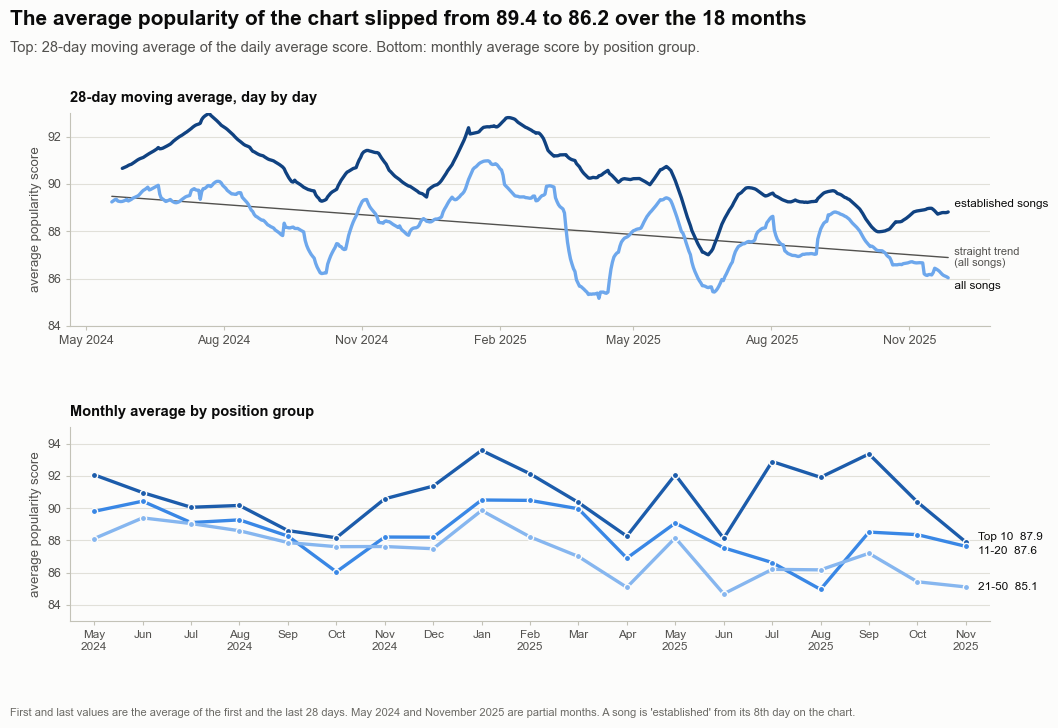

rank_tier,Top 10,11-20,21-50
year_month,,,
2024-05,92.10,89.80,88.10
2024-06,91.00,90.40,89.40
2024-07,90.10,89.10,89.00
2024-08,90.20,89.30,88.60
2024-09,88.60,88.30,87.90
2024-10,88.20,86.00,87.60
2024-11,90.60,88.20,87.60
2024-12,91.40,88.20,87.50
2025-01,93.60,90.50,89.90


In [27]:
# Figure 23 - the Popularity Score Trend: how the average score of the chart moved over time
rated = playlist.dropna(subset=["popularity_clean"])
established = rated[rated["days_in_stint"] > 7]                                                          # songs that have already been on the chart for more than a week
daily_all = rated.groupby("date")["popularity_clean"].mean().reindex(daily["date"])
daily_old = established.groupby("date")["popularity_clean"].mean().reindex(daily["date"])
smooth_all = daily_all.rolling(28, center=True, min_periods=14).mean()
smooth_old = daily_old.rolling(28, center=True, min_periods=14).mean()
x_days = np.arange(len(daily_all))
slope_all = np.polyfit(x_days, daily_all.to_numpy(), 1)[0]
valid_old = daily_old.notna().to_numpy()
slope_old = np.polyfit(x_days[valid_old], daily_old.to_numpy()[valid_old], 1)[0]
tier_month = rated.groupby(["year_month", "rank_tier"], observed=True)["popularity_clean"].mean().unstack().reindex(columns=RANK_TIER_LABELS)
months = list(tier_month.index)
dip_day = daily_all.idxmin()
dip_rows = rated[rated["date"] == dip_day]

FACTS["trend_first_28"] = float(daily_all.iloc[:28].mean())
FACTS["trend_last_28"] = float(daily_all.iloc[-28:].mean())
FACTS["trend_change"] = FACTS["trend_last_28"] - FACTS["trend_first_28"]
FACTS["trend_old_first_28"] = float(daily_old.iloc[:28].mean())
FACTS["trend_old_last_28"] = float(daily_old.iloc[-28:].mean())
FACTS["trend_old_change"] = FACTS["trend_old_last_28"] - FACTS["trend_old_first_28"]
FACTS["trend_slope_per_100d"] = float(slope_all * 100)
FACTS["trend_old_slope_per_100d"] = float(slope_old * 100)
FACTS["trend_dip_value"] = float(daily_all.min())
FACTS["trend_dip_date"] = f"{dip_day:%d %b %Y}"
FACTS["trend_dip_weekday"] = f"{dip_day:%A}"
FACTS["trend_dip_new_entries"] = int((dip_rows["movement"] == "New entry").sum())
FACTS["trend_dip_new_mean"] = float(dip_rows.loc[dip_rows["movement"] == "New entry", "popularity_clean"].mean())
dip_lead = dip_rows.loc[dip_rows["movement"] == "New entry", "primary_artist"].value_counts()
FACTS["trend_dip_lead_artist"] = str(dip_lead.index[0])
FACTS["trend_dip_lead_entries"] = int(dip_lead.iloc[0])
FACTS["trend_new_first_day_mean"] = float(rated.loc[rated["movement"] == "New entry", "popularity_clean"].mean())
FACTS["trend_best_month"] = rated.groupby("year_month")["popularity_clean"].mean().idxmax()
FACTS["trend_worst_month"] = rated.groupby("year_month")["popularity_clean"].mean().idxmin()
FACTS["trend_tier_top10_first"] = float(tier_month.iloc[0]["Top 10"])
FACTS["trend_tier_top10_last"] = float(tier_month.iloc[-1]["Top 10"])
FACTS["trend_tier_21_50_first"] = float(tier_month.iloc[0]["21-50"])
FACTS["trend_tier_21_50_last"] = float(tier_month.iloc[-1]["21-50"])

OLD_COLOR = style.BLUE_STEPS[650]
fig, (ax1, ax2) = make_fig(11.5, 7.4, 2, 1, left=0.95, right=1.35, bottom=0.95, hspace=0.5, height_ratios=[1.1, 1], panel_titles=True,
                           title=f"The average popularity of the chart slipped from {FACTS['trend_first_28']:.1f} to {FACTS['trend_last_28']:.1f} over the 18 months",
                           subtitle="Top: 28-day moving average of the daily average score. Bottom: monthly average score by position group.",
                           note_text="First and last values are the average of the first and the last 28 days. May 2024 and November 2025 are partial months. A song is 'established' from its 8th day on the chart.")
ax1.plot(daily["date"], smooth_old, color=OLD_COLOR, linewidth=2.4, zorder=3)
ax1.plot(daily["date"], smooth_all, color=style.BLUE_STEPS[300], linewidth=2.4, zorder=3)
ax1.plot(daily["date"], intercept_all := (np.polyfit(x_days, daily_all.to_numpy(), 1)[1] + slope_all * x_days), color=style.INK_2, linewidth=1.0, zorder=2)
last_day = daily["date"].iloc[-1]
direct_label(ax1, last_day, smooth_old.iloc[-1] + 0.35, "  established songs", ha="left", va="center", size=8.5, color=style.INK)
direct_label(ax1, last_day, smooth_all.iloc[-1] - 0.35, "  all songs", ha="left", va="center", size=8.5, color=style.INK)
direct_label(ax1, last_day, intercept_all[-1], "  straight trend\n  (all songs)", ha="left", va="center", size=8, color=style.INK_2)
ax1.set_ylim(84, 93)
ax1.set_ylabel("average popularity score")
ax1.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %Y"))
ax1.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(interval=3))
style_axes(ax1, grid="y")
panel_title(ax1, "28-day moving average, day by day")

x = np.arange(len(months))
for tier in RANK_TIER_LABELS:
    ax2.plot(x, tier_month[tier], color=style.TIER_COLORS[tier], linewidth=2.4, marker="o", markersize=4.5, markeredgecolor=style.SURFACE, markeredgewidth=1.0)
ends = {"Top 10": 3.5, "11-20": -3.5, "21-50": 0}
for tier in RANK_TIER_LABELS:
    direct_label(ax2, x[-1] + 0.25, tier_month[tier].iloc[-1], f"{tier}  {tier_month[tier].iloc[-1]:.1f}", dy=ends[tier], dx=0, ha="left", va="center", size=8.5, color=style.INK)
ax2.set_xlim(-0.5, len(months) - 0.5)
ax2.set_ylim(83, 95)
ax2.set_xticks(x)
ax2.set_xticklabels([pd.Period(m).strftime("%b\n%Y") if (k % 3 == 0) else pd.Period(m).strftime("%b") for k, m in enumerate(months)], fontsize=8.5)
ax2.set_ylabel("average popularity score")
style_axes(ax2, grid="y")
panel_title(ax2, "Monthly average by position group")
save_fig(fig, "p4_23_popularity_trend", FIG_DIR)
plt.show()

display(tier_month.round(1))

**What to notice**

- The 28-day average of the daily score fell from 89.4 in the first 28 days to 86.2 in the last 28 (-3.2 points). For songs already more than a week into their stay it fell from 90.9 to 89.0 (-1.9): a smaller slide, so part of the fall comes from the mix of arriving songs.
- The lowest day was 17 Aug 2025 (Sunday as recorded in the file): an average of 72.0, on a day when 15 songs entered with an average score of only 40.8; 14 of them came from one release by Post Malone. New entries start low (an average of 72 on their first day) and gain later, so a release day with many new songs pulls the day's average down. The dip is a mix effect, not a fall in the popularity of the songs already on the chart.
- From the first to the last month the average of the Top 10 went from 92.1 to 87.9 and that of positions 21-50 from 88.1 to 85.1. The month with the highest average score was January 2025 and the one with the lowest June 2025.

**What this code is.** Figure 24: one dot per song with at least 14 days on the chart. Across: the popularity swing of the song (the standard deviation of its score). Up: the position swing of the song (the standard deviation of its position, the Rank Volatility Index). Large dots with a line show the median position swing for each fifth of the popularity-swing scale.

**Why we need it.** "Popularity stability versus chart volatility" is a named item in the brief. If a song whose score is steady also holds a steady position, a label could use the score as an early warning of chart trouble.

**What will happen.** The code keeps songs with at least two weeks of data (shorter stays give noisy standard deviations), calculates the Spearman correlation, splits songs into five equal groups by popularity swing and takes the median position swing of each group.

**Expected outcome.** A cloud of blue dots rising slowly to the right, and a black line through five dots that climbs at first and then flattens.

**Motive.** Test whether the score carries information about chart stability, and say how much.

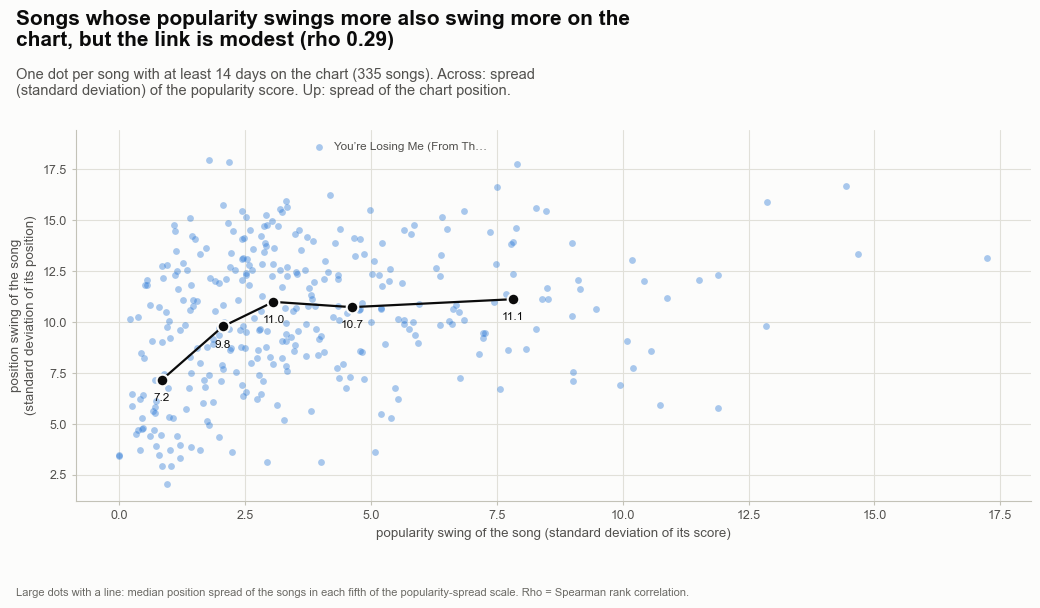

,pop_std,volatility,songs
pop_group,,,
0,0.85,7.17,67
1,2.06,9.79,67
2,3.06,11.00,68
3,4.62,10.74,66
4,7.82,11.13,67


In [28]:
# Figure 24 - does a song whose popularity swings also swing on the chart?
steady = dim_track[(dim_track["days_on_chart"] >= 14)].dropna(subset=["popularity_std", "rank_volatility_index"]).copy()
rho_stab = stats.spearmanr(steady["popularity_std"], steady["rank_volatility_index"])[0]
steady["pop_group"] = pd.qcut(steady["popularity_std"], 5, labels=False)
group_table = steady.groupby("pop_group").agg(pop_std=("popularity_std", "median"), volatility=("rank_volatility_index", "median"), songs=("track_id", "size"))

FACTS["stab_songs"] = len(steady)
FACTS["stab_rho"] = float(rho_stab)
FACTS["stab_first_group"] = float(group_table["volatility"].iloc[0])
FACTS["stab_last_group"] = float(group_table["volatility"].iloc[-1])
FACTS["stab_pop_std_median"] = float(steady["popularity_std"].median())
FACTS["stab_volatility_median"] = float(steady["rank_volatility_index"].median())
FACTS["stab_low_low_pct"] = float(((steady["popularity_std"] <= steady["popularity_std"].median()) & (steady["rank_volatility_index"] <= steady["rank_volatility_index"].median())).mean() * 100)
most_volatile = steady.nlargest(1, "rank_volatility_index").iloc[0]
FACTS["stab_most_volatile_song"] = most_volatile["song_clean"]
FACTS["stab_most_volatile_artist"] = most_volatile["primary_artist"]
FACTS["stab_most_volatile_value"] = float(most_volatile["rank_volatility_index"])

fig, ax = make_fig(11, 6.2, left=0.95, right=0.5, bottom=0.95,
                   title=f"Songs whose popularity swings more also swing more on the chart, but the link is modest (rho {FACTS['stab_rho']:.2f})",
                   subtitle=f"One dot per song with at least 14 days on the chart ({FACTS['stab_songs']} songs). Across: spread (standard deviation) of the popularity score. Up: spread of the chart position.",
                   note_text="Large dots with a line: median position spread of the songs in each fifth of the popularity-spread scale. Rho = Spearman rank correlation.")
ax.scatter(steady["popularity_std"], steady["rank_volatility_index"], s=24, color=style.BLUE, alpha=0.40, linewidth=0, zorder=2)
ax.plot(group_table["pop_std"], group_table["volatility"], color=style.INK, linewidth=1.6, zorder=4)
ax.scatter(group_table["pop_std"], group_table["volatility"], s=70, color=style.INK, edgecolor=style.SURFACE, linewidth=1.5, zorder=5)
for row in group_table.itertuples():
    direct_label(ax, row.pop_std, row.volatility, f"{row.volatility:.1f}", dx=0, dy=-13, ha="center", va="center", size=8.5, color=style.INK)
direct_label(ax, most_volatile["popularity_std"] + 0.3, most_volatile["rank_volatility_index"], f"{short(most_volatile['song_clean'], 26)}", dx=0, dy=0, ha="left", va="center", size=8.5)
ax.set_xlabel("popularity swing of the song (standard deviation of its score)")
ax.set_ylabel("position swing of the song\n(standard deviation of its position)")
style_axes(ax, grid="both")
save_fig(fig, "p4_24_stability_vs_volatility", FIG_DIR)
plt.show()

display(group_table.round(2))

**What to notice**

- Across the 335 songs with at least 14 days, the Spearman correlation between popularity swing and position swing is 0.29: songs whose score swings more also swing more on the chart, but the link is modest.
- The typical song's score varies by 3.1 points and its position by 10.5 places. The fifth of songs with the steadiest scores has a median position swing of 7.2, the fifth with the most unsteady scores 11.1; most of that rise happens across the first two fifths, after which the line is nearly flat. 29% of songs sit at or below the median on both measures, against about 25% if the two were unrelated.
- Among these songs the largest position swing belongs to *You’re Losing Me (From The Vault)* by Taylor Swift: 18.6 places.

**What this code is.** Figure 25, two panels. Left: the median length of a chart run for each fifth of first-day popularity scores, with the correlation across all runs. Right: the same question asked inside each starting band (runs that began in 1-10, 11-20, 21-30, 31-40 and 41-50): the median length of runs with a low first-day score against runs with a high one.

**Why we need it.** Does a song that arrives with a high score stay longer? Asked of all runs together, the answer can mislead, because runs that start in different places on the chart can be very different kinds of runs. Asking it inside each starting band compares like with like.

**What will happen.** The code keeps complete runs whose first-day score is a real score (not a repaired zero, which would have been filled in from later days), splits each starting band at its own median score, and compares the median run length of the two halves.

**Expected outcome.** Left: five bars of similar height with no clear trend from left to right, and a correlation close to zero. Right: five pairs of dots in which the high-score dot sits to the right of the low-score dot.

**Motive.** Show, with real numbers, how a link that is invisible overall can appear once like is compared with like.

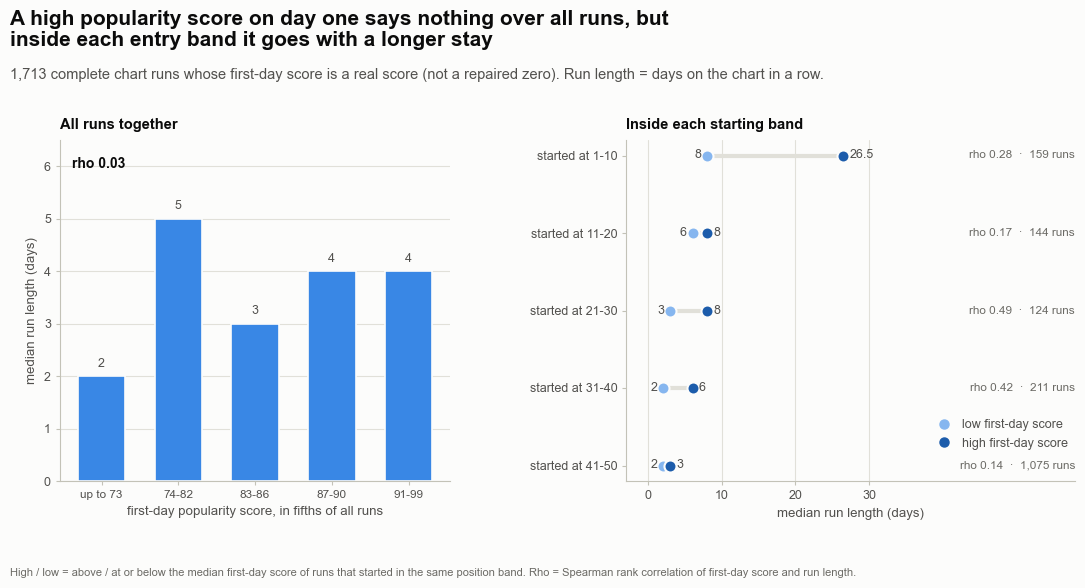

,runs,cut,low_median,high_median,rho
band,,,,,
1-10,159,75.00,8.00,26.50,0.28
11-20,144,73.00,6.00,8.00,0.17
21-30,124,74.50,3.00,8.00,0.49
31-40,211,79.00,2.00,6.00,0.42
41-50,1075,87.00,2.00,3.00,0.14


In [29]:
# Figure 25 - does a song that arrives with a high popularity score stay longer?
first_day = (playlist.sort_values(["stint_key", "snapshot_index"]).groupby("stint_key")
             .first()[["popularity_clean", "popularity_fill_method"]].rename(columns={"popularity_clean": "entry_popularity"}))
entry = runs.set_index("stint_key").join(first_day)
entry = entry[entry["complete"] & (entry["popularity_fill_method"] == "original")].copy()                 # complete runs whose first score is a real score
assert (entry["entry_popularity"] == entry["entry_popularity"].round()).all()                              # real scores are whole numbers, so "74-82" below is exact
entry["band"] = pd.cut(entry["entry_position"], band_edges, labels=band_names)
entry["fifth"] = pd.qcut(entry["entry_popularity"], 5, duplicates="drop")
fifths = entry.groupby("fifth", observed=True)["length"].agg(runs="size", median="median")

rows = []
for name, group in entry.groupby("band", observed=True):
    cut = group["entry_popularity"].median()
    low, high = group[group["entry_popularity"] <= cut], group[group["entry_popularity"] > cut]
    rows.append({"band": name, "runs": len(group), "cut": cut, "low_median": low["length"].median(), "high_median": high["length"].median(),
                 "rho": stats.spearmanr(group["entry_popularity"], group["length"])[0]})
by_band = pd.DataFrame(rows).set_index("band")

FACTS["entry_runs"] = len(entry)
FACTS["entry_excluded"] = int(runs["complete"].sum() - len(entry))
FACTS["entry_rho_all"] = float(stats.spearmanr(entry["entry_popularity"], entry["length"])[0])
for name, key in zip(band_names, ["b1", "b2", "b3", "b4", "b5"]):
    FACTS[f"entry_rho_{key}"] = float(by_band.loc[name, "rho"])
    FACTS[f"entry_low_{key}"] = float(by_band.loc[name, "low_median"])
    FACTS[f"entry_high_{key}"] = float(by_band.loc[name, "high_median"])
    FACTS[f"entry_n_{key}"] = int(by_band.loc[name, "runs"])
    FACTS[f"entry_cut_{key}"] = float(by_band.loc[name, "cut"])

FACTS["entry_rho_band_min"] = float(by_band["rho"].min())
FACTS["entry_rho_band_max"] = float(by_band["rho"].max())

fig, (ax1, ax2) = make_fig(11.5, 6.0, 1, 2, left=0.85, right=0.5, bottom=0.95, wspace=0.42, panel_titles=True, width_ratios=[1, 1.15],
                           title="A high popularity score on day one says nothing over all runs, but inside each entry band it goes with a longer stay",
                           subtitle=f"{FACTS['entry_runs']:,} complete chart runs whose first-day score is a real score (not a repaired zero). Run length = days on the chart in a row.",
                           note_text="High / low = above / at or below the median first-day score of runs that started in the same position band. Rho = Spearman rank correlation of first-day score and run length.")
x = np.arange(len(fifths))
ax1.bar(x, fifths["median"], width=0.62, color=style.BLUE_STEPS[400], edgecolor=style.SURFACE, linewidth=1.2)
for xi, value in enumerate(fifths["median"]):
    ax1.text(xi, value + 0.12, f"{value:g}", ha="center", va="bottom", fontsize=9, color=style.INK_2)
ax1.set_xticks(x)
ax1.set_xticklabels([f"{interval.left + 1:.0f}-{interval.right:.0f}" if k else f"up to {interval.right:.0f}" for k, interval in enumerate(fifths.index)], fontsize=8.5)
ax1.set_ylim(0, fifths["median"].max() * 1.3)
ax1.set_xlabel("first-day popularity score, in fifths of all runs")
ax1.set_ylabel("median run length (days)")
style_axes(ax1, grid="y")
ax1.text(0.03, 0.95, f"rho {FACTS['entry_rho_all']:.2f}", transform=ax1.transAxes, fontsize=10, fontweight="bold", color=style.INK, va="top")
panel_title(ax1, "All runs together")

LOW_COLOR, HIGH_COLOR = style.BLUE_STEPS[250], style.BLUE_STEPS[550]
y = np.arange(len(by_band))
ax2.hlines(y, by_band["low_median"], by_band["high_median"], color=style.GRID, linewidth=3, zorder=1)
ax2.scatter(by_band["low_median"], y, s=75, color=LOW_COLOR, edgecolor=style.SURFACE, linewidth=1.5, zorder=3)
ax2.scatter(by_band["high_median"], y, s=75, color=HIGH_COLOR, edgecolor=style.SURFACE, linewidth=1.5, zorder=3)
for yi, row in enumerate(by_band.itertuples()):
    ax2.text(row.low_median - 0.8, yi, f"{row.low_median:g}", ha="right", va="center", fontsize=9, color=style.INK_2)
    ax2.text(row.high_median + 0.8, yi, f"{row.high_median:g}", ha="left", va="center", fontsize=9, color=style.INK_2)
    ax2.text(1.0, yi, f"rho {row.rho:.2f}  ·  {row.runs:,} runs", transform=ax2.get_yaxis_transform(), ha="right", va="center", fontsize=8.5, color=style.MUTED)
ax2.set_yticks(y)
ax2.set_yticklabels([f"started at {name}" for name in by_band.index])
ax2.invert_yaxis()
ax2.set_xlim(-3, 58)
ax2.set_xticks([0, 10, 20, 30])
ax2.set_xlabel("median run length (days)")
ax2.tick_params(axis="y", length=0)
style_axes(ax2, grid="x")
swatch_legend(ax2, [("low first-day score", LOW_COLOR, "dot"), ("high first-day score", HIGH_COLOR, "dot")], loc="lower right", bbox_to_anchor=(1.0, 0.07))
panel_title(ax2, "Inside each starting band")
save_fig(fig, "p4_25_entry_popularity", FIG_DIR)
plt.show()

display(by_band.round(2))

**What to notice**

- Over all 1,713 runs the Spearman correlation between first-day score and run length is only 0.03. Inside the starting bands it is between 0.14 and 0.49: 0.28 for runs that began in 1-10, 0.17 for 11-20, 0.49 for 21-30, 0.42 for 31-40 and 0.14 for 41-50.
- Among runs that began in the top 10 (159 runs), those with a first-day score of 75 or lower lasted a median 8 days, those above it 26.5 days. For runs that began in 41-50 (1,075 runs) the medians are 2 and 3 days.
- 168 complete runs are left out because their first-day score was a repaired zero. A caution for Phase 6: those repaired values come from later days of the same song, so a model that uses first-day popularity as a predictor must not use them.

**What this code is.** Figure 26, the Rank Volatility Index (RVI). Left: every song as a faint dot (average position across, RVI up) with, for each group of ten positions, the median (hollow dot) and the middle half (bar). The RVI is the standard deviation of a song's position over its days on the chart. Right: the median day-to-day move for the same groups.

**Why we need it.** The Rank Volatility Index is a KPI of the brief. Asking which songs are the most volatile needs a fair comparison: a song near the bottom or the very top has little room to move, so the answer depends on where the song lives.

**What will happen.** The code keeps songs with at least seven days (a standard deviation over fewer days says little), groups them by average position in bands of ten places, calculates the median and quartiles of the RVI per group, and the median of the average daily move.

**Expected outcome.** Left: a hump, with the highest bars for songs that average 11 to 40 and the lowest at the two ends, and the number of songs written above each group. Right: day-to-day moves that grow from the top group to the middle and then dip slightly.

**Motive.** Say where volatility lives, and keep a mechanical effect (no room to move at the edges) from being read as a finding.

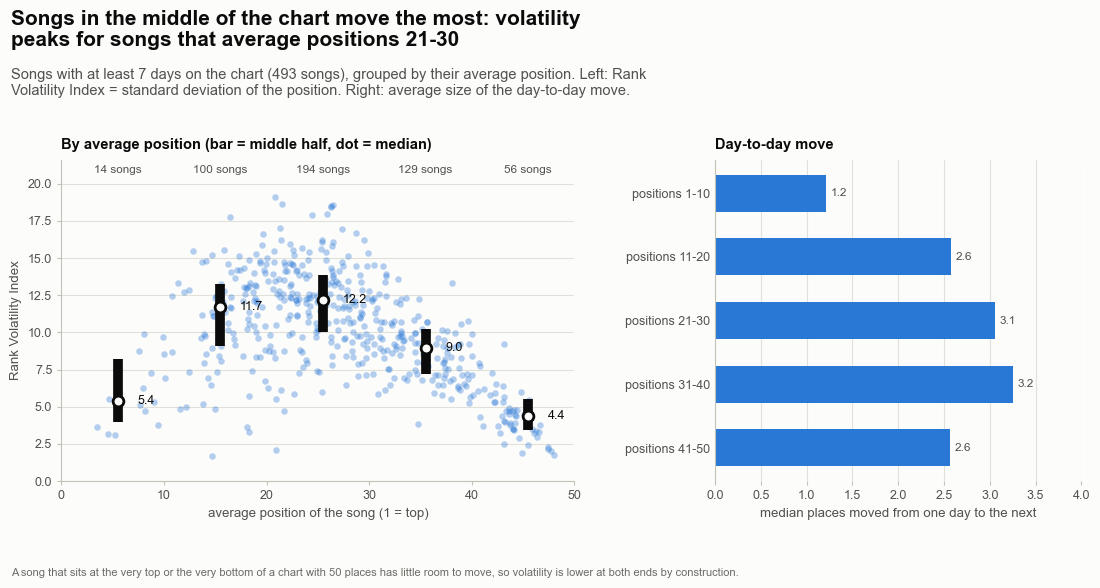

,songs,median,q25,q75
avg_band,,,,
1-10,14,5.40,3.99,8.24
11-20,100,11.68,9.05,13.27
21-30,194,12.20,10.00,13.90
31-40,129,8.97,7.21,10.25
41-50,56,4.38,3.47,5.51


avg_band
1-10    1.21
11-20   2.58
21-30   3.06
31-40   3.25
41-50   2.57
Name: avg_daily_rank_move, dtype: float64

In [30]:
# Figure 26 - the Rank Volatility Index: which songs move the most?
steady_days = dim_track[(dim_track["days_on_chart"] >= 7)].dropna(subset=["rank_volatility_index"]).copy()
steady_days["avg_band"] = pd.cut(steady_days["avg_rank"], band_edges, labels=band_names)
by_avg_band = steady_days.groupby("avg_band", observed=True).agg(songs=("track_id", "size"), median=("rank_volatility_index", "median"),
                                                                 q25=("rank_volatility_index", lambda s: s.quantile(0.25)),
                                                                 q75=("rank_volatility_index", lambda s: s.quantile(0.75))).reindex(band_names)
jumpiness = steady_days.groupby("avg_band", observed=True)["avg_daily_rank_move"].median().reindex(band_names)
rho_rvi_avg = stats.spearmanr(steady_days["avg_rank"], steady_days["rank_volatility_index"])[0]

FACTS["rvi_songs"] = len(steady_days)
for name, key in zip(band_names, ["b1", "b2", "b3", "b4", "b5"]):
    FACTS[f"rvi_median_{key}"] = float(by_avg_band.loc[name, "median"])
    FACTS[f"rvi_songs_{key}"] = int(by_avg_band.loc[name, "songs"])
FACTS["rvi_peak_band"] = by_avg_band["median"].idxmax()
FACTS["rvi_peak_value"] = float(by_avg_band["median"].max())
FACTS["rvi_overall_median"] = float(steady_days["rank_volatility_index"].median())
for name, key in zip(band_names, ["b1", "b2", "b3", "b4", "b5"]):
    FACTS[f"move_median_{key}"] = float(jumpiness.loc[name])
FACTS["rvi_rho_avg_rank"] = float(rho_rvi_avg)

fig, (ax1, ax2) = make_fig(11.5, 6.0, 1, 2, left=0.85, right=0.45, bottom=0.95, wspace=0.32, panel_titles=True, width_ratios=[1.4, 1],
                           title=f"Songs in the middle of the chart move the most: volatility peaks for songs that average positions {FACTS['rvi_peak_band']}",
                           subtitle=f"Songs with at least 7 days on the chart ({FACTS['rvi_songs']} songs), grouped by their average position. Left: Rank Volatility Index = standard deviation of the position. Right: average size of the day-to-day move.",
                           note_text="A song that sits at the very top or the very bottom of a chart with 50 places has little room to move, so volatility is lower at both ends by construction.")
rng = np.random.default_rng(11)
ax1.scatter(steady_days["avg_rank"], steady_days["rank_volatility_index"], s=22, color=style.BLUE, alpha=0.35, linewidth=0, zorder=2)
centres = [5.5, 15.5, 25.5, 35.5, 45.5]
ax1.vlines(centres, by_avg_band["q25"], by_avg_band["q75"], color=style.INK, linewidth=7, zorder=4)
ax1.scatter(centres, by_avg_band["median"], s=60, color=style.SURFACE, edgecolor=style.INK, linewidth=2.0, zorder=5)
for centre, row in zip(centres, by_avg_band.itertuples()):
    direct_label(ax1, centre + 1.9, row.median, f"{row.median:.1f}", ha="left", va="center", size=9, color=style.INK)
    ax1.text(centre, 20.9, f"{row.songs} songs", ha="center", va="center", fontsize=8.5, color=style.INK_2)
ax1.set_xlim(0, 50)
ax1.set_ylim(0, 21.6)
ax1.set_xticks([0, 10, 20, 30, 40, 50])
ax1.set_xlabel("average position of the song (1 = top)")
ax1.set_ylabel("Rank Volatility Index")
style_axes(ax1, grid="y")
panel_title(ax1, "By average position (bar = middle half, dot = median)")

hbar(ax2, [f"positions {name}" for name in band_names], jumpiness, color=style.BLUE, fmt="{:.1f}", label_chars=None, xlim=(0, 4), bar_height=0.58)
ax2.set_xlabel("median places moved from one day to the next")
panel_title(ax2, "Day-to-day move")
save_fig(fig, "p4_26_rank_volatility", FIG_DIR)
plt.show()

display(by_avg_band.round(2))
display(jumpiness.round(2))

**What to notice**

- Among the 493 songs with at least seven days the median RVI is 10.1 places. It is highest for songs that average positions 21-30 (12.2) and lowest at the two ends: 5.4 for songs that average the top 10 and 4.4 for 41-50.
- The median day-to-day move runs 1.2, 2.6, 3.1, 3.2 and 2.6 places from the top band to the bottom band. Only 14 songs average the top 10, so the left end rests on few songs.
- The Spearman correlation between a song's average position number and its RVI is -0.43: songs that sit lower on the chart tend to be steadier. A rank correlation only sees one direction, so it describes the right-hand slope of the hump and misses the dip at the top.

## Section 7 - Content attribute analysis

The last block of the brief asks whether what a song is changes how it does: explicit or not, single or part of an album, how
long the song is, and how big the album it comes from. These attributes are known the day a song is released, which makes them
the cheapest inputs for a decision. Every song counts once in the comparisons below; the month-by-month chart counts song-days.

**What this code is.** Figure 27: what the chart is made of, month by month. Three lines show the share of the month's song-days that are explicit, that come from a single release, and that are collaborations.

**Why we need it.** Before comparing groups, we need to know how big each group is and whether it stays the same over time. A group that changes size quickly is a different thing to compare in different months.

**What will happen.** The code calculates, for each month, the share of song-days that are explicit, from a single release, or by more than one artist, labels the highest and the lowest explicit month and the last value of each line, and stores the monthly ranges and overall shares as facts.

**Expected outcome.** Three lines: the explicit line high and moving, the single line in the middle, the collaboration line low and fairly flat. The first and last months are partial months.

**Motive.** Show how the mix of the chart shifts, before asking whether the mix matters.

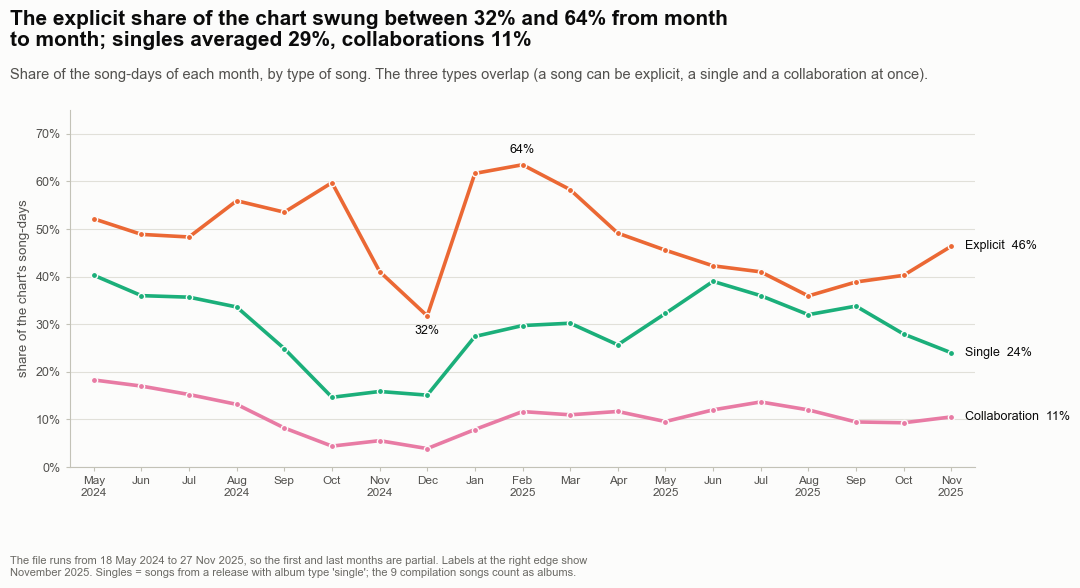

,explicit,single,collab
year_month,,,
2024-05,52.10,40.30,18.30
2024-06,48.90,36.00,17.00
2024-07,48.30,35.70,15.20
2024-08,55.90,33.60,13.20
2024-09,53.50,24.90,8.20
2024-10,59.70,14.60,4.40
2024-11,41.10,15.90,5.50
2024-12,31.70,15.10,3.90
2025-01,61.70,27.40,7.90


In [31]:
# Figure 27 - what the chart is made of, month by month: explicit songs, singles and collaborations
mix = playlist.groupby("year_month").agg(explicit=("is_explicit", "mean"), single=("release_format", lambda s: (s == "Single").mean()),
                                         collab=("is_collab", "mean")) * 100
months = list(mix.index)
overall_share = {"explicit": playlist["is_explicit"].mean() * 100, "single": (playlist["release_format"] == "Single").mean() * 100,
                 "collab": playlist["is_collab"].mean() * 100}
mix_stats = {column: (mix[column].min(), mix[column].idxmin(), mix[column].max(), mix[column].idxmax(), overall_share[column])
             for column in ("explicit", "single", "collab")}
for column, (low, low_month, high, high_month, overall) in mix_stats.items():
    FACTS[f"mix_{column}_low"] = float(low)
    FACTS[f"mix_{column}_low_month"] = low_month
    FACTS[f"mix_{column}_high"] = float(high)
    FACTS[f"mix_{column}_high_month"] = high_month
    FACTS[f"mix_{column}_overall"] = float(overall)
FACTS["mix_explicit_above_half_months"] = int((mix["explicit"] > 50).sum())
FACTS["mix_months"] = len(months)
FACTS["mix_compilation_songs"] = int((dim_track["album_type"] == "compilation").sum())
FACTS["mix_first_date"] = f"{playlist['date'].min():%d %b %Y}"
FACTS["mix_last_date"] = f"{playlist['date'].max():%d %b %Y}"
FACTS["mix_last_month_name"] = pd.Period(months[-1]).strftime("%B %Y")

fig, ax = make_fig(11.5, 6.0, left=0.95, right=1.5, bottom=0.95,
                   title=f"The explicit share of the chart swung between {FACTS['mix_explicit_low']:.0f}% and {FACTS['mix_explicit_high']:.0f}% from month to month; singles averaged {FACTS['mix_single_overall']:.0f}%, collaborations {FACTS['mix_collab_overall']:.0f}%",
                   subtitle="Share of the song-days of each month, by type of song. The three types overlap (a song can be explicit, a single and a collaboration at once).",
                   note_text=f"The file runs from {FACTS['mix_first_date']} to {FACTS['mix_last_date']}, so the first and last months are partial. Labels at the right edge show {FACTS['mix_last_month_name']}. Singles = songs from a release with album type 'single'; the {FACTS['mix_compilation_songs']} compilation songs count as albums.")
x = np.arange(len(months))
series = [("explicit", "Explicit", style.EXPLICIT_COLOR), ("single", "Single", style.SINGLE_COLOR), ("collab", "Collaboration", style.MAGENTA)]
for column, label, color in series:
    ax.plot(x, mix[column], color=color, linewidth=2.6, marker="o", markersize=4.5, markeredgecolor=style.SURFACE, markeredgewidth=1.0, zorder=3)
    direct_label(ax, x[-1] + 0.3, mix[column].iloc[-1], f"{label}  {mix[column].iloc[-1]:.0f}%", ha="left", va="center", size=9, color=style.INK)
low_i, high_i = months.index(FACTS["mix_explicit_low_month"]), months.index(FACTS["mix_explicit_high_month"])
direct_label(ax, low_i, mix["explicit"].iloc[low_i] - 3.2, f"{mix['explicit'].iloc[low_i]:.0f}%", ha="center", va="center", size=9, color=style.INK)
direct_label(ax, high_i, mix["explicit"].iloc[high_i] + 3.2, f"{mix['explicit'].iloc[high_i]:.0f}%", ha="center", va="center", size=9, color=style.INK)
ax.set_xlim(-0.5, len(months) - 0.5)
ax.set_ylim(0, 75)
ax.set_xticks(x)
ax.set_xticklabels([pd.Period(m).strftime("%b\n%Y") if (k % 3 == 0) else pd.Period(m).strftime("%b") for k, m in enumerate(months)], fontsize=8.5)
ax.yaxis.set_major_formatter(percent_formatter())
ax.set_ylabel("share of the chart's song-days")
style_axes(ax, grid="y")
save_fig(fig, "p4_27_content_mix_over_time", FIG_DIR)
plt.show()

display(mix.round(1))

**What to notice**

- The explicit share of the chart's song-days is 48% overall, but by month it ran from 32% in December 2024 to 64% in February 2025; it was above half in 7 of the 19 months.
- Songs from single releases make up 29% of song-days overall (between 15% and 40% by month) and collaborations 11% (between 4% and 18%). The 9 compilation songs count as album songs.
- The first and last months are part months, because the file runs from 18 May 2024 to 27 Nov 2025. The highest single share and the highest collaboration share both fall in May 2024, a part month, so read those two peaks with care.

**What this code is.** Figure 28, the content scorecard: three rows of bars (explicit against not explicit, single against album, collaboration against solo) and five columns of measures: number of songs, median days on the chart, share of songs that reached the top 10, average position and average popularity.

**Why we need it.** It answers the brief's "explicit versus non-explicit" and "single versus album" questions in one view, and adds collaborations. Using the same five measures for every comparison makes the groups easy to compare.

**What will happen.** The code groups songs by each attribute, calculates the five measures with every song counted once (position and popularity are the mean of each song's own average over its days), draws the bars in the project's entity colours (explicit orange, not explicit blue, single aqua, album violet, collaboration magenta, solo grey) and stores every value as a fact.

**Expected outcome.** A 3-by-5 grid of bar pairs with the value written above each bar.

**Motive.** Compare the groups on the same yardsticks, so that a difference can be judged at a glance and tested in Phase 5.

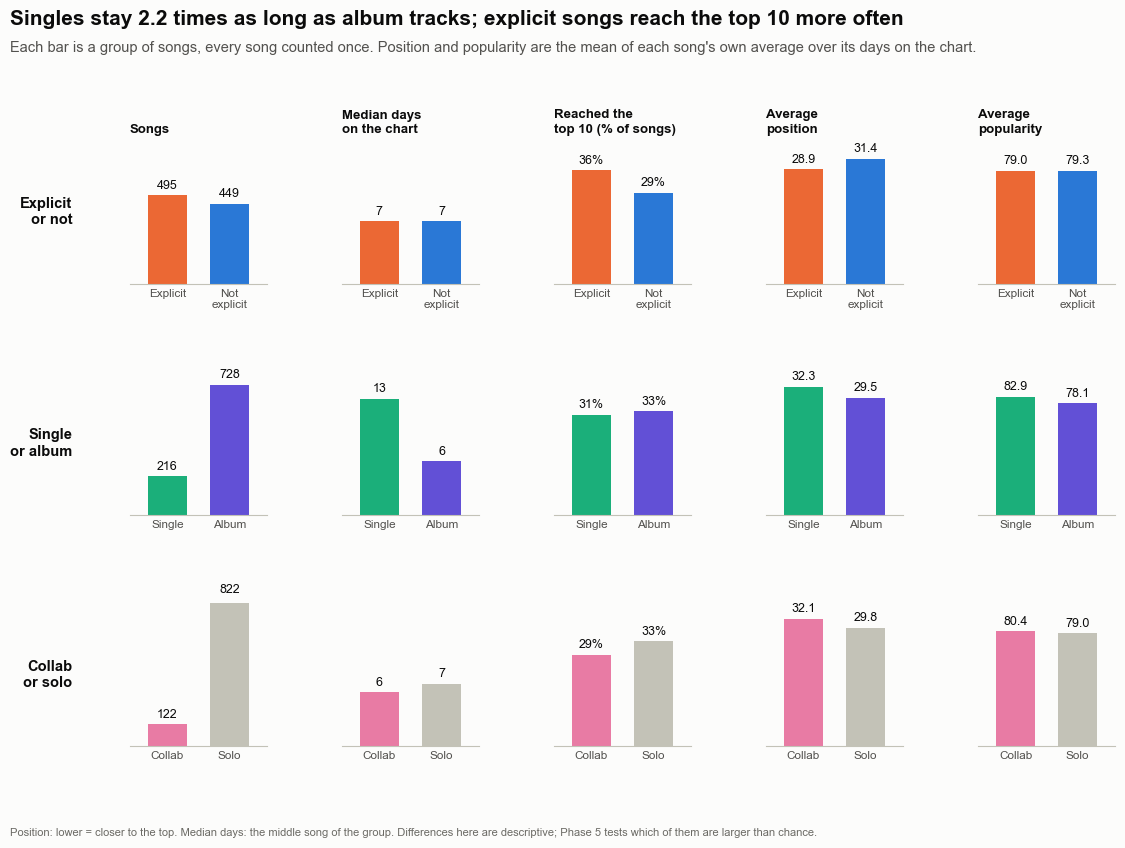

,songs,median_days,top10_pct,avg_position,avg_popularity
explicit,495.00,7.00,35.76,28.91,79.03
clean,449.00,7.00,28.73,31.45,79.27
single,216.00,13.00,31.48,32.29,82.87
album,728.00,6.00,32.69,29.47,78.06
collab,122.00,6.00,28.69,32.10,80.41
solo,822.00,7.00,32.97,29.83,78.97


In [32]:
# Figure 28 - content scorecard: explicit, single or album, and collaboration, compared on five measures
def describe_group(frame):
    return {"songs": len(frame), "median_days": frame["days_on_chart"].median(), "top10_pct": frame["reached_top10"].mean() * 100,
            "avg_position": frame["avg_rank"].mean(), "avg_popularity": frame["avg_popularity"].mean()}

comparisons = [
    ("Explicit\nor not", [("explicit", "Explicit", dim_track["is_explicit"], style.EXPLICIT_COLOR),
                          ("clean", "Not\nexplicit", ~dim_track["is_explicit"], style.CLEAN_COLOR)]),
    ("Single\nor album", [("single", "Single", dim_track["release_format"] == "Single", style.SINGLE_COLOR),
                          ("album", "Album", dim_track["release_format"] == "Album", style.ALBUM_COLOR)]),
    ("Collab\nor solo", [("collab", "Collab", dim_track["is_collab"], style.MAGENTA),
                                ("solo", "Solo", ~dim_track["is_collab"], style.AXIS)]),
]
measures = [("songs", "Songs", "{:,.0f}"), ("median_days", "Median days\non the chart", "{:g}"), ("top10_pct", "Reached the\ntop 10 (% of songs)", "{:.0f}%"),
            ("avg_position", "Average\nposition", "{:.1f}"), ("avg_popularity", "Average\npopularity", "{:.1f}")]
scorecard = {}
for _, groups in comparisons:
    for key, _, mask, _ in groups:
        scorecard[key] = describe_group(dim_track[mask])
        for measure, _, _ in measures:
            FACTS[f"card_{key}_{measure}"] = float(scorecard[key][measure])
FACTS["card_explicit_songs_pct"] = scorecard["explicit"]["songs"] / len(dim_track) * 100
FACTS["card_single_songs_pct"] = scorecard["single"]["songs"] / len(dim_track) * 100
FACTS["card_collab_songs_pct"] = scorecard["collab"]["songs"] / len(dim_track) * 100

fig, axes = make_fig(11.8, 8.6, 3, 5, left=1.55, right=0.4, bottom=0.9, hspace=0.62, wspace=0.55, panel_titles=True, top_extra=0.28,
                     title=f"Singles stay {FACTS['card_single_median_days'] / FACTS['card_album_median_days']:.1f} times as long as album tracks; explicit songs reach the top 10 more often",
                     subtitle="Each bar is a group of songs, every song counted once. Position and popularity are the mean of each song's own average over its days on the chart.",
                     note_text="Position: lower = closer to the top. Median days: the middle song of the group. Differences here are descriptive; Phase 5 tests which of them are larger than chance.")
column_max = {"songs": 800, "median_days": 16, "top10_pct": 45, "avg_position": 36, "avg_popularity": 100}
for row_index, (row_label, groups) in enumerate(comparisons):
    axes[row_index, 0].text(-0.42, 0.5, row_label, transform=axes[row_index, 0].transAxes, ha="right", va="center", fontsize=10.5, fontweight="bold", color=style.INK)
    for col_index, (measure, title, fmt) in enumerate(measures):
        ax = axes[row_index, col_index]
        values = [scorecard[key][measure] for key, _, _, _ in groups]
        bars = ax.bar([0, 1], values, width=0.62, color=[color for _, _, _, color in groups], edgecolor="none")
        for xi, value in enumerate(values):
            ax.text(xi, value + column_max[measure] * 0.025, fmt.format(value), ha="center", va="bottom", fontsize=9, color=style.INK)
        ax.set_xticks([0, 1])
        ax.set_xticklabels([label for _, label, _, _ in groups], fontsize=8.5)
        ax.set_xlim(-0.6, 1.6)
        ax.set_ylim(0, column_max[measure])
        ax.set_yticks([])
        ax.spines["left"].set_visible(False)
        ax.spines["bottom"].set_color(style.AXIS)
        ax.tick_params(axis="x", length=0)
        if row_index == 0:
            ax.set_title(title, loc="left", fontsize=9.5, fontweight="bold", color=style.INK, pad=6)
save_fig(fig, "p4_28_attribute_scorecard", FIG_DIR)
plt.show()

display(pd.DataFrame(scorecard).T.round(2))

**What to notice**

- Singles (216 songs, 23% of all songs) stay a median 13 days, album tracks (728 songs) 6 days, yet the two reach the top 10 about equally often (31% against 33%). Singles also average a higher popularity (82.9 against 78.1), but sit lower on the chart on average: an average position of 32.3 against 29.5, where a smaller number is better.
- Explicit songs (495 songs) reach the top 10 more often: 36% against 29% for songs that are not explicit (449 songs). The median stay of the two groups is 7 and 7 days, and their average popularity is almost equal (79.0 and 79.3).
- Collaborations (122 songs) reach the top 10 less often than solo songs (29% against 33%) and sit slightly lower on the chart on average (32.1 against 29.8).

**What this code is.** Figure 29, three panels. Left: a histogram of song lengths. Middle: the share of songs that reached the top 10 in five length bands (under 2:30, 2:30-3:00, 3:00-3:30, 3:30-4:00, 4:00 and up). Right: the median days on the chart for the same bands.

**Why we need it.** "Duration impact" is a named item in the brief. A histogram shows what lengths exist; the two outcome panels show whether length changes either the peak or the stay.

**What will happen.** The code converts the length in minutes to a mm:ss label, cuts songs into the five bands, calculates the share that reached the top 10 and the median days for each band, and stores the Spearman correlations between length and two outcomes.

**Expected outcome.** Left: a hump around three and a half minutes with a long right tail. Middle: bars that rise from left to right. Right: bars that stay about the same height.

**Motive.** Check whether the length of a song matters, and for which outcome.

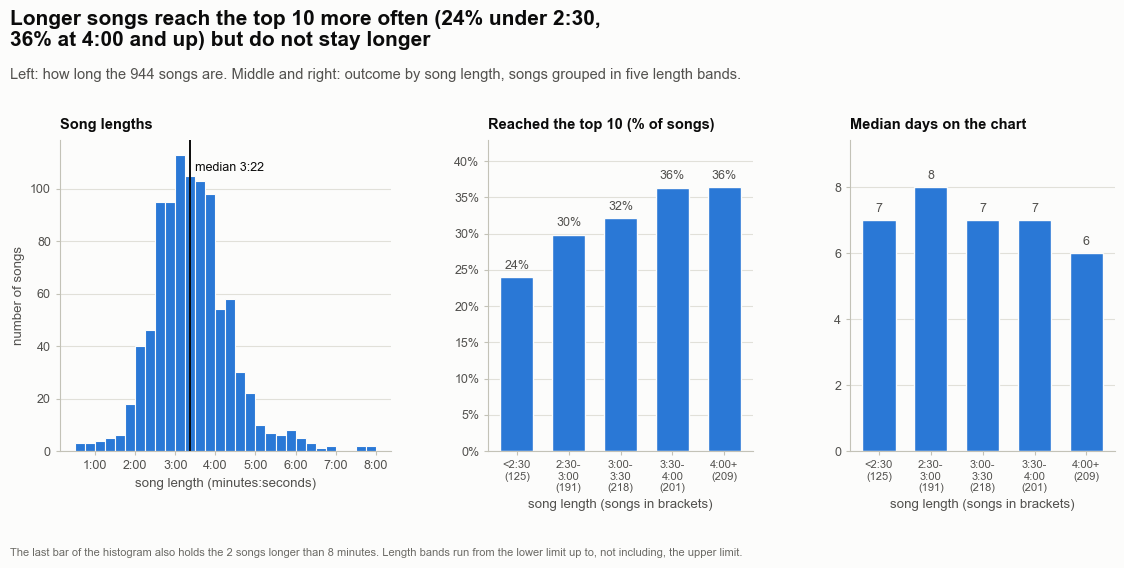

,songs,top10_pct,median_days
duration_min,,,
under 2:30,125,24.00,7.00
2:30-3:00,191,29.80,8.00
3:00-3:30,218,32.10,7.00
3:30-4:00,201,36.30,7.00
4:00 and up,209,36.40,6.00


In [33]:
# Figure 29 - song length: how long are the songs on the chart, and does length change the outcome?
def mmss(minutes):
    """3.37 -> '3:22' (minutes:seconds)."""
    total = int(round(minutes * 60))
    return f"{total // 60}:{total % 60:02d}"

lengths = dim_track["duration_min"]
duration_edges = [0, 2.5, 3.0, 3.5, 4.0, 100]
duration_names = ["under 2:30", "2:30-3:00", "3:00-3:30", "3:30-4:00", "4:00 and up"]
duration_band = pd.cut(lengths, duration_edges, labels=duration_names)
by_length = dim_track.groupby(duration_band, observed=True).agg(songs=("track_id", "size"), top10_pct=("reached_top10", lambda s: s.mean() * 100),
                                                                 median_days=("days_on_chart", "median")).reindex(duration_names)
rho_len_position = stats.spearmanr(lengths, 51 - dim_track["avg_rank"])[0]
rho_len_days = stats.spearmanr(lengths, dim_track["days_on_chart"])[0]

FACTS["len_median"] = float(lengths.median())
FACTS["len_median_text"] = mmss(lengths.median())
FACTS["len_q25_text"] = mmss(lengths.quantile(0.25))
FACTS["len_q75_text"] = mmss(lengths.quantile(0.75))
FACTS["len_over_8"] = int((lengths > 8).sum())
FACTS["len_shortest_text"] = mmss(lengths.min())
FACTS["len_longest_text"] = mmss(lengths.max())
FACTS["len_rho_position"] = float(rho_len_position)
FACTS["len_rho_days"] = float(rho_len_days)
for name, key in zip(duration_names, ["u230", "b230", "b300", "b330", "o400"]):
    FACTS[f"len_top10_{key}"] = float(by_length.loc[name, "top10_pct"])
    FACTS[f"len_days_{key}"] = float(by_length.loc[name, "median_days"])
    FACTS[f"len_songs_{key}"] = int(by_length.loc[name, "songs"])

fig, (ax1, ax2, ax3) = make_fig(11.8, 5.8, 1, 3, left=0.85, right=0.4, bottom=1.05, wspace=0.34, panel_titles=True, width_ratios=[1.25, 1, 1],
                                title=f"Longer songs reach the top 10 more often ({FACTS['len_top10_u230']:.0f}% under 2:30, {FACTS['len_top10_o400']:.0f}% at 4:00 and up) but do not stay longer",
                                subtitle=f"Left: how long the {FACTS['songs']} songs are. Middle and right: outcome by song length, songs grouped in five length bands.",
                                note_text=f"The last bar of the histogram also holds the {FACTS['len_over_8']} songs longer than 8 minutes. Length bands run from the lower limit up to, not including, the upper limit.")
edges = np.arange(0.5, 8.01, 0.25)
ax1.hist(lengths.clip(upper=7.99), bins=edges, color=style.BLUE, edgecolor=style.SURFACE, linewidth=0.8)
ax1.axvline(lengths.median(), color=style.INK, linewidth=1.4)
ax1.text(lengths.median() + 0.12, ax1.get_ylim()[1] * 0.93, f"median {FACTS['len_median_text']}", fontsize=9, color=style.INK, ha="left", va="top")
ax1.set_xticks([1, 2, 3, 4, 5, 6, 7, 8])
ax1.set_xticklabels(["1:00", "2:00", "3:00", "4:00", "5:00", "6:00", "7:00", "8:00"])
ax1.set_xlabel("song length (minutes:seconds)")
ax1.set_ylabel("number of songs")
style_axes(ax1, grid="y")
panel_title(ax1, "Song lengths")

x = np.arange(len(duration_names))
tick_labels = [f"{name}\n({int(n)})" for name, n in zip(["under\n2:30", "2:30-\n3:00", "3:00-\n3:30", "3:30-\n4:00", "4:00\nand up"], by_length["songs"])]
for ax, column, fmt, title in ((ax2, "top10_pct", "{:.0f}%", "Reached the top 10 (% of songs)"), (ax3, "median_days", "{:g}", "Median days on the chart")):
    ax.bar(x, by_length[column], width=0.64, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.0)
    for xi, value in enumerate(by_length[column]):
        ax.text(xi, value + by_length[column].max() * 0.02, fmt.format(value), ha="center", va="bottom", fontsize=9, color=style.INK_2)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{name}\n({int(n)})" for name, n in zip(["<2:30", "2:30-\n3:00", "3:00-\n3:30", "3:30-\n4:00", "4:00+"], by_length["songs"])], fontsize=8)
    ax.set_ylim(0, by_length[column].max() * 1.18)
    style_axes(ax, grid="y")
    panel_title(ax, title)
ax2.yaxis.set_major_formatter(percent_formatter())
ax2.set_xlabel("song length (songs in brackets)")
ax3.set_xlabel("song length (songs in brackets)")
save_fig(fig, "p4_29_duration", FIG_DIR)
plt.show()

display(by_length.round(1))

**What to notice**

- The median song is 3:22 long, the middle half runs from 2:47 to 3:55. The shortest song is 0:37, the longest 12:20, and 2 songs are longer than eight minutes.
- The share of songs that reached the top 10 rises with length: 24% for songs under 2:30, 30% for 2:30-3:00, 32% for 3:00-3:30, 36% for 3:30-4:00 and 36% for 4:00 and up. The median stay does not follow: 7, 8, 7, 7 and 6 days.
- The Spearman correlation of song length with the average position (measured so that higher means closer to the top) is 0.15, and with days on the chart -0.06: a weak link to where a song sits, almost none to how long it stays.

**What this code is.** Figure 30, two panels. Left: for each album-size band (1 track, 2-3, 4-7, 8-15, 16-40, 41 or more), the share of songs and the share of chart points. Right: the median days on the chart for each band; bands with fewer than 20 songs are drawn in a lighter tint.

**Why we need it.** "Album size versus success" is a named item in the brief. Putting the share of songs next to the share of points shows which sizes earn more than their number, and the tint warns where the median rests on too few songs.

**What will happen.** The code uses the `release_size_band` column of Phase 2, adds up songs and chart points per band, takes the median days, shades bands with fewer than 20 songs, and calculates the Spearman correlation between the number of tracks and days on the chart.

**Expected outcome.** Left: tall bars for the 8-15 and 16-40 bands and for the single-track releases. Right: one tall bar for single-track releases and lower bars for the rest.

**Motive.** Find out whether bigger releases do better, and avoid over-reading bands that hold a handful of songs.

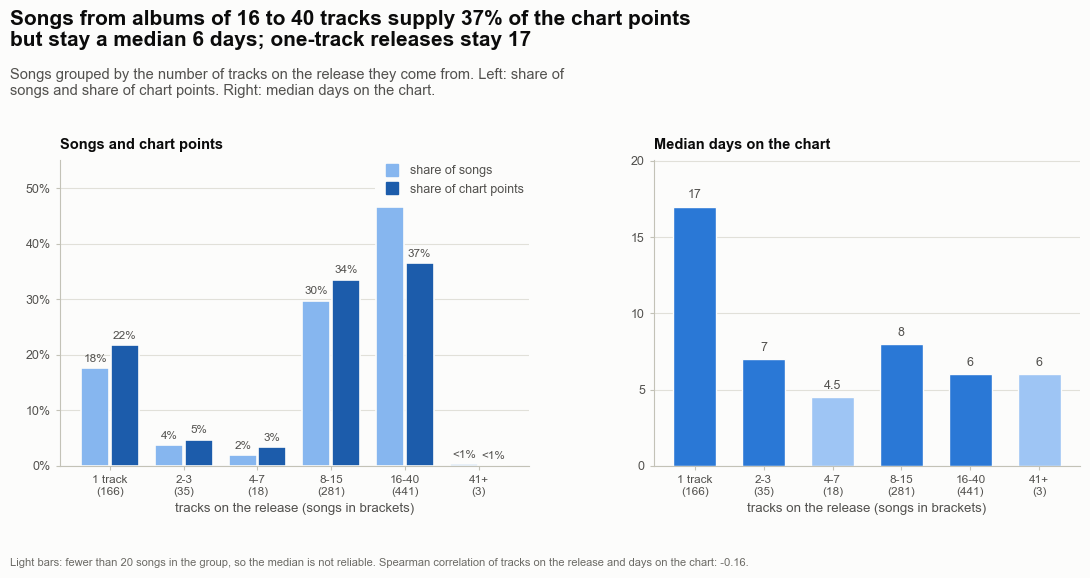

,songs,points,median_days,top10_pct,share_songs,share_points
release_size_band,,,,,,
1 track,166,153851,17.00,29.50,17.60,21.70
2-3,35,33584,7.00,45.70,3.70,4.70
4-7,18,23953,4.50,33.30,1.90,3.40
8-15,281,237243,8.00,32.00,29.80,33.50
16-40,441,258819,6.00,32.90,46.70,36.60
41+,3,175,6.00,0.00,0.30,0.00


In [34]:
# Figure 30 - the size of the release: does a song from a big album behave differently from a single?
size_table = dim_track.groupby("release_size_band", observed=True).agg(songs=("track_id", "size"), points=("chart_points", "sum"),
                                                                       median_days=("days_on_chart", "median"),
                                                                       top10_pct=("reached_top10", lambda s: s.mean() * 100)).reindex(SIZE_LABELS)
size_table["share_songs"] = size_table["songs"] / size_table["songs"].sum() * 100
size_table["share_points"] = size_table["points"] / size_table["points"].sum() * 100
rho_tracks_days = stats.spearmanr(dim_track["total_tracks"], dim_track["days_on_chart"])[0]
SMALL_GROUP = 20                                                                                           # bands with fewer songs than this are shown in a lighter tint

for name, key in zip(SIZE_LABELS, ["s1", "s2", "s4", "s8", "s16", "s41"]):
    FACTS[f"size_songs_{key}"] = int(size_table.loc[name, "songs"])
    FACTS[f"size_days_{key}"] = float(size_table.loc[name, "median_days"])
    FACTS[f"size_points_{key}"] = float(size_table.loc[name, "share_points"])
    FACTS[f"size_share_songs_{key}"] = float(size_table.loc[name, "share_songs"])
FACTS["size_rho_days"] = float(rho_tracks_days)
FACTS["size_small_groups"] = int((size_table["songs"] < SMALL_GROUP).sum())

fig, (ax1, ax2) = make_fig(11.5, 5.9, 1, 2, left=0.85, right=0.45, bottom=1.0, wspace=0.28, panel_titles=True, width_ratios=[1.1, 1],
                           title=f"Songs from albums of 16 to 40 tracks supply {FACTS['size_points_s16']:.0f}% of the chart points but stay a median {FACTS['size_days_s16']:g} days; one-track releases stay {FACTS['size_days_s1']:g}",
                           subtitle="Songs grouped by the number of tracks on the release they come from. Left: share of songs and share of chart points. Right: median days on the chart.",
                           note_text=f"Light bars: fewer than {SMALL_GROUP} songs in the group, so the median is not reliable. Spearman correlation of tracks on the release and days on the chart: {rho_tracks_days:.2f}.")
x = np.arange(len(SIZE_LABELS))
width = 0.38
SONGS_COLOR, POINTS_COLOR = style.BLUE_STEPS[250], style.BLUE_STEPS[550]
for offset, column, color in ((-width / 2 - 0.01, "share_songs", SONGS_COLOR), (width / 2 + 0.01, "share_points", POINTS_COLOR)):
    bars = ax1.bar(x + offset, size_table[column], width=width, color=color, edgecolor=style.SURFACE, linewidth=1.2)
    for bar in bars:
        shown = "<1%" if bar.get_height() < 0.5 else f"{bar.get_height():.0f}%"
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, shown, ha="center", va="bottom", fontsize=8.5, color=style.INK_2)
ax1.set_xticks(x)
ax1.set_xticklabels([f"{name}\n({int(n)})" for name, n in zip(SIZE_LABELS, size_table["songs"])], fontsize=8.5)
ax1.set_xlabel("tracks on the release (songs in brackets)")
ax1.yaxis.set_major_formatter(percent_formatter())
ax1.set_ylim(0, max(size_table["share_songs"].max(), size_table["share_points"].max()) * 1.18)
style_axes(ax1, grid="y")
swatch_legend(ax1, [("share of songs", SONGS_COLOR), ("share of chart points", POINTS_COLOR)], loc="upper right",
              frameon=True, facecolor=style.SURFACE, edgecolor="none", framealpha=1, borderaxespad=0)
panel_title(ax1, "Songs and chart points")

bar_colors = [style.BLUE_STEPS[200] if n < SMALL_GROUP else style.BLUE for n in size_table["songs"]]
ax2.bar(x, size_table["median_days"], width=0.62, color=bar_colors, edgecolor=style.SURFACE, linewidth=1.0)
for xi, (value, n) in enumerate(zip(size_table["median_days"], size_table["songs"])):
    ax2.text(xi, value + size_table["median_days"].max() * 0.02, f"{value:g}", ha="center", va="bottom", fontsize=9, color=style.INK_2)
ax2.set_xticks(x)
ax2.set_xticklabels([f"{name}\n({int(n)})" for name, n in zip(SIZE_LABELS, size_table["songs"])], fontsize=8.5)
ax2.set_xlabel("tracks on the release (songs in brackets)")
ax2.set_ylim(0, size_table["median_days"].max() * 1.18)
ax2.set_yticks(range(0, int(size_table["median_days"].max()) + 5, 5))
style_axes(ax2, grid="y")
panel_title(ax2, "Median days on the chart")
save_fig(fig, "p4_30_album_size", FIG_DIR)
plt.show()

display(size_table.round(1))

**What to notice**

- Albums of 16 to 40 tracks supply 47% of songs (441) and 37% of chart points, with a median stay of 6 days. Albums of 8 to 15 tracks supply 30% of songs and 34% of points (8 days). One-track releases supply 18% of songs and 22% of points, and stay a median 17 days, the longest of any band.
- 2 bands have fewer than 20 songs (4-7 tracks with 18 songs and 41 or more with 3), so their medians are not reliable. The Spearman correlation between the number of tracks on the release and days on the chart is -0.16.

**What this code is.** Figure 31, two panels. Left: four tiles, one for each combination of explicit (yes or no) and release format (single or album track), each showing the median days on the chart, the number of songs and the share that reached the top 10. Right: the share of songs and the share of chart points of each combination.

**Why we need it.** Two attributes can hide each other. Figure 28 showed that singles stay longer and that explicit songs reach the top 10 more often; this figure asks whether the two effects are separate or the same thing.

**What will happen.** The code splits the 944 songs into the four combinations, calculates medians, shares and chart points for each, and writes the number text in white or dark ink depending on which reads better on the tile's colour.

**Expected outcome.** Left: one dark tile (explicit singles) against three lighter ones. Right: for each combination a light bar (share of songs) and a dark bar (share of chart points); the two are close, except for explicit album tracks, whose share of songs is clearly above their share of points.

**Motive.** See whether the explicit effect is a format effect in disguise.

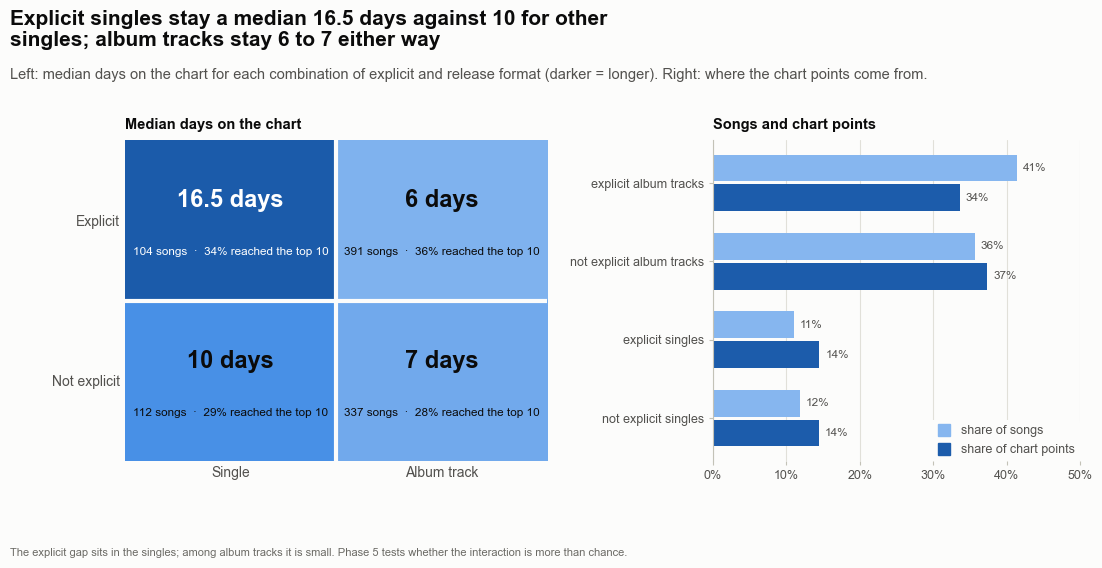

,explicit,format,songs,median_days,top10_pct,points,share_points,share_songs
0,Explicit,Single,104,16.50,33.70,102599,14.50,11.00
1,Explicit,Album,391,6.00,36.30,238085,33.60,41.40
2,Not explicit,Single,112,10.00,29.50,102469,14.50,11.90
3,Not explicit,Album,337,7.00,28.50,264472,37.40,35.70


In [35]:
# Figure 31 - explicit and format together: the four combinations
combo_rows = []
for explicit_flag, explicit_label in ((True, "Explicit"), (False, "Not explicit")):
    for format_name in ("Single", "Album"):
        group = dim_track[(dim_track["is_explicit"] == explicit_flag) & (dim_track["release_format"] == format_name)]
        combo_rows.append({"explicit": explicit_label, "format": format_name, "songs": len(group), "median_days": group["days_on_chart"].median(),
                           "top10_pct": group["reached_top10"].mean() * 100, "points": group["chart_points"].sum()})
combo = pd.DataFrame(combo_rows)
combo["share_points"] = combo["points"] / combo["points"].sum() * 100
combo["share_songs"] = combo["songs"] / combo["songs"].sum() * 100
cell = {(row.explicit, row.format): row for row in combo.itertuples()}
for (explicit_label, format_name), row in cell.items():
    key = f"combo_{'x' if explicit_label == 'Explicit' else 'c'}_{'s' if format_name == 'Single' else 'a'}"
    FACTS[f"{key}_days"] = float(row.median_days)
    FACTS[f"{key}_songs"] = int(row.songs)
    FACTS[f"{key}_songs_pct"] = float(row.share_songs)
    FACTS[f"{key}_top10"] = float(row.top10_pct)
    FACTS[f"{key}_points"] = float(row.share_points)


fig, (ax1, ax2) = make_fig(11.5, 5.8, 1, 2, left=1.5, right=0.45, bottom=0.95, wspace=0.42, panel_titles=True, width_ratios=[1.15, 1],
                           title=f"Explicit singles stay a median {FACTS['combo_x_s_days']:g} days against {FACTS['combo_c_s_days']:g} for other singles; album tracks stay {FACTS['combo_x_a_days']:g} to {FACTS['combo_c_a_days']:g} either way",
                           subtitle="Left: median days on the chart for each combination of explicit and release format (darker = longer). Right: where the chart points come from.",
                           note_text="The explicit gap sits in the singles; among album tracks it is small. Phase 5 tests whether the interaction is more than chance.")
matrix = np.array([[cell[(e, f)].median_days for f in ("Single", "Album")] for e in ("Explicit", "Not explicit")])
TILE_MAX = 22
ax1.imshow(matrix, cmap=style.SEQUENTIAL_BLUE, vmin=0, vmax=TILE_MAX, aspect="auto")
for i, e in enumerate(("Explicit", "Not explicit")):
    for j, f in enumerate(("Single", "Album")):
        row = cell[(e, f)]
        ink = readable_ink(style.SEQUENTIAL_BLUE(row.median_days / TILE_MAX))
        ax1.text(j, i - 0.12, f"{row.median_days:g} days", ha="center", va="center", fontsize=17, fontweight="bold", color=ink)
        ax1.text(j, i + 0.2, f"{row.songs} songs  ·  {row.top10_pct:.0f}% reached the top 10", ha="center", va="center", fontsize=8.5, color=ink)
ax1.set_xticks([0, 1])
ax1.set_xticklabels(["Single", "Album track"], fontsize=10)
ax1.set_yticks([0, 1])
ax1.set_yticklabels(["Explicit", "Not explicit"], fontsize=10)
ax1.tick_params(length=0)
ax1.hlines([0.5], -0.5, 1.5, color=style.SURFACE, linewidth=3)
ax1.vlines([0.5], -0.5, 1.5, color=style.SURFACE, linewidth=3)
for side in ax1.spines.values():
    side.set_visible(False)
panel_title(ax1, "Median days on the chart")

order = [("Explicit", "Album"), ("Not explicit", "Album"), ("Explicit", "Single"), ("Not explicit", "Single")]
labels = [f"{e.lower()} {'album tracks' if f == 'Album' else 'singles'}" for e, f in order]
values = [cell[key].share_points for key in order]
songs_share = [cell[key].share_songs for key in order]
y = np.arange(len(order))
ax2.barh(y - 0.19, songs_share, height=0.34, color=style.BLUE_STEPS[250], edgecolor="none")
ax2.barh(y + 0.19, values, height=0.34, color=style.BLUE_STEPS[550], edgecolor="none")
for yi, (a, b) in enumerate(zip(songs_share, values)):
    ax2.text(a + 0.8, yi - 0.19, f"{a:.0f}%", ha="left", va="center", fontsize=8.5, color=style.INK_2)
    ax2.text(b + 0.8, yi + 0.19, f"{b:.0f}%", ha="left", va="center", fontsize=8.5, color=style.INK_2)
ax2.set_yticks(y)
ax2.set_yticklabels(labels, fontsize=9)
ax2.invert_yaxis()
ax2.set_xlim(0, 50)
ax2.xaxis.set_major_formatter(percent_formatter())
ax2.tick_params(axis="y", length=0)
style_axes(ax2, grid="x", bottom_spine=False)
swatch_legend(ax2, [("share of songs", style.BLUE_STEPS[250]), ("share of chart points", style.BLUE_STEPS[550])], loc="lower right",
              frameon=True, facecolor=style.SURFACE, edgecolor="none", framealpha=1, borderaxespad=0)
panel_title(ax2, "Songs and chart points")
save_fig(fig, "p4_31_explicit_by_format", FIG_DIR)
plt.show()

display(combo.round(1))

**What to notice**

- Explicit singles (104 songs) stay a median 16.5 days and 34% of them reached the top 10. Singles that are not explicit (112 songs) stay 10 days, and 29% reached the top 10.
- Among album tracks the picture is different: explicit ones (391 songs) stay 6 days and 36% reached the top 10; the others (337 songs) stay 7 days, 28%. The gap in staying power sits in the singles.
- Explicit album tracks are 41% of the songs but earn 34% of the chart points, while both single groups earn a little more than their share of songs (14% of points against 11% of songs for explicit singles, 14% against 12% for the other singles). Each single group has about a hundred songs, so its median moves with a few songs. Phase 5 tests whether the interaction is more than chance.

## Section 8 - One picture of how the song measures relate

After five blocks of single comparisons, one overview: a correlation heat map of the song-level measures. It is a map to read
before the hypothesis tests of Phase 5, not a result by itself. A correlation describes one kind of link (the two measures move
together in one direction), it does not show cause, and some links in it are built into the measures.

**What this code is.** Figure 32, two heat maps with one colour scale. Left: how the six outcome measures relate to each other (days on the chart, better peak position, better average position, average popularity, popularity variability and rank volatility). Right: how the five song attributes (explicit, single release, collaboration, tracks on the release, song length) relate to those six outcomes.

**Why we need it.** It brings Sections 3 to 7 together. The left map shows which outcome measures say the same thing, so that Phase 6 does not predict the same fact twice. The right map shows which attributes are worth testing at all.

**What will happen.** The code builds one table of 11 measures per song, with positions flipped (51 minus the position) so that higher always means better, calculates the Spearman rank correlation of every pair with the songs that have both values, and checks the quoted pairs against scipy. The two volatility measures use only songs with enough days (14 for popularity variability, 7 for rank volatility). Pairs that are partly built into the measures carry a dagger.

**Expected outcome.** A staircase heat map on the left with some strong cells (dark blue) and a block of pale cells on the right, most of them within 0.2 of zero.

**Motive.** Hand Phase 5 and Phase 6 a map: which relationships are strong, which are built in, and which attributes hardly move any outcome.

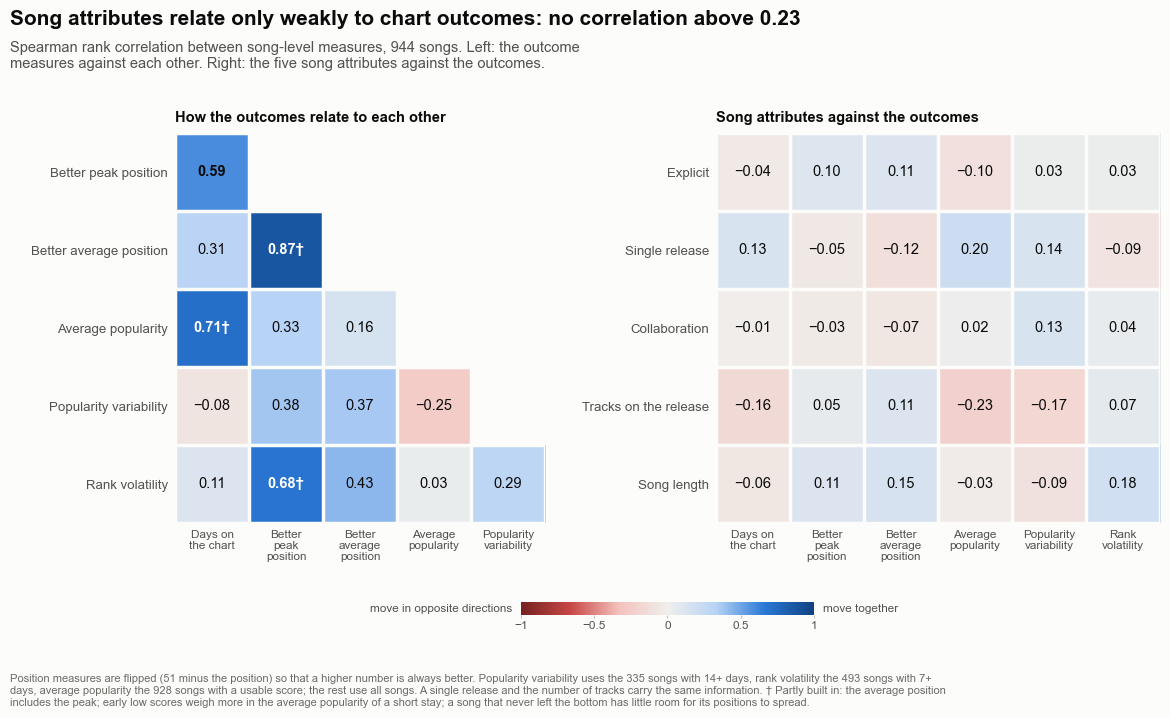

,days,peak,average,popularity,pop_var,rank_vol,explicit,single,collab,tracks,length
days,1.00,0.59,0.31,0.71,-0.08,0.11,-0.04,0.13,-0.01,-0.16,-0.06
peak,0.59,1.00,0.87,0.33,0.38,0.68,0.10,-0.05,-0.03,0.05,0.11
average,0.31,0.87,1.00,0.16,0.37,0.43,0.11,-0.12,-0.07,0.11,0.15
popularity,0.71,0.33,0.16,1.00,-0.25,0.03,-0.10,0.20,0.02,-0.23,-0.03
pop_var,-0.08,0.38,0.37,-0.25,1.00,0.29,0.03,0.14,0.13,-0.17,-0.09
rank_vol,0.11,0.68,0.43,0.03,0.29,1.00,0.03,-0.09,0.04,0.07,0.18
explicit,-0.04,0.10,0.11,-0.10,0.03,0.03,1.00,-0.05,0.18,0.11,-0.03
single,0.13,-0.05,-0.12,0.20,0.14,-0.09,-0.05,1.00,0.29,-0.73,-0.15
collab,-0.01,-0.03,-0.07,0.02,0.13,0.04,0.18,0.29,1.00,-0.23,0.01
tracks,-0.16,0.05,0.11,-0.23,-0.17,0.07,0.11,-0.73,-0.23,1.00,0.20


In [36]:
# Figure 32 - one picture of how the song-level measures relate to each other (Spearman rank correlation)
POP_VAR_MIN_DAYS = 14               # a popularity swing needs two weeks of scores to mean anything (the same rule as Figure 24)
RANK_VOL_MIN_DAYS = 7               # rank volatility needs a week of positions (the same rule as Figure 26)

song_measures = pd.DataFrame({
    "days": dim_track["days_on_chart"],
    "peak": CHART_SIZE + 1 - dim_track["best_rank"],                       # flipped so that a higher number always means a better position
    "average": CHART_SIZE + 1 - dim_track["avg_rank"],
    "popularity": dim_track["avg_popularity"],
    "pop_var": dim_track["popularity_std"].where(dim_track["days_on_chart"] >= POP_VAR_MIN_DAYS),
    "rank_vol": dim_track["rank_volatility_index"].where(dim_track["days_on_chart"] >= RANK_VOL_MIN_DAYS),
    "explicit": dim_track["is_explicit"].astype(float),
    "single": (dim_track["release_format"] == "Single").astype(float),
    "collab": dim_track["is_collab"].astype(float),
    "tracks": dim_track["total_tracks"],
    "length": dim_track["duration_min"],
})
corr = song_measures.corr(method="spearman")                               # each pair uses the songs that have both numbers

for first, second in (("peak", "days"), ("popularity", "days"), ("rank_vol", "peak"), ("tracks", "popularity"), ("single", "tracks")):
    both = song_measures[[first, second]].dropna()                          # cross-check against scipy for the pairs we quote
    assert abs(corr.loc[first, second] - stats.spearmanr(both[first], both[second])[0]) < 1e-9, (first, second)

OUTCOMES = ["days", "peak", "average", "popularity", "pop_var", "rank_vol"]
ATTRIBUTES = ["explicit", "single", "collab", "tracks", "length"]
COLUMN_LABEL = {"days": "Days on\nthe chart", "peak": "Better\npeak\nposition", "average": "Better\naverage\nposition",
                "popularity": "Average\npopularity", "pop_var": "Popularity\nvariability", "rank_vol": "Rank\nvolatility"}
ROW_LABEL = {"days": "Days on the chart", "peak": "Better peak position", "average": "Better average position", "popularity": "Average popularity",
             "pop_var": "Popularity variability", "rank_vol": "Rank volatility", "explicit": "Explicit", "single": "Single release",
             "collab": "Collaboration", "tracks": "Tracks on the release", "length": "Song length"}
PLAIN_NAME = {"days": "days on the chart", "peak": "peak position", "average": "average position", "popularity": "average popularity",
              "pop_var": "popularity variability", "rank_vol": "rank volatility", "explicit": "explicit songs", "single": "singles",
              "collab": "collaborations", "tracks": "tracks on the release", "length": "song length"}
BUILT_IN = {frozenset(pair) for pair in (("peak", "average"), ("popularity", "days"), ("rank_vol", "peak"))}   # links that are partly built into the measures

cross = corr.loc[ATTRIBUTES, OUTCOMES]
cross_abs = cross.abs().stack()
top_attribute, top_outcome = cross_abs.idxmax()
FACTS["corr_cross_cells"] = int(cross.size)
FACTS["corr_cross_max_abs"] = float(cross_abs.max())
FACTS["corr_cross_max_value"] = float(cross.loc[top_attribute, top_outcome])
FACTS["corr_cross_max_attribute"] = PLAIN_NAME[top_attribute]
FACTS["corr_cross_max_outcome"] = PLAIN_NAME[top_outcome]
FACTS["corr_cross_below_015"] = int((cross.abs() < 0.15).to_numpy().sum())
FACTS["corr_cross_below_020"] = int((cross.abs() < 0.20).to_numpy().sum())
for place, ((attribute, outcome), _) in enumerate(cross_abs.sort_values(ascending=False).head(3).items(), start=1):
    FACTS[f"corr_cross_top{place}_pair"] = f"{PLAIN_NAME[attribute]} and {PLAIN_NAME[outcome]}"
    FACTS[f"corr_cross_top{place}_value"] = float(cross.loc[attribute, outcome])
for name, (first, second) in {"peak_average": ("peak", "average"), "days_popularity": ("days", "popularity"), "days_peak": ("days", "peak"),
                              "rankvol_peak": ("rank_vol", "peak"), "rankvol_average": ("rank_vol", "average"), "single_tracks": ("single", "tracks"),
                              "single_popularity": ("single", "popularity"), "single_days": ("single", "days"), "popvar_peak": ("pop_var", "peak")}.items():
    FACTS[f"corr_{name}"] = float(corr.loc[first, second])
FACTS["corr_n_popularity"] = int(song_measures["popularity"].notna().sum())
FACTS["corr_n_popvar"] = int(song_measures["pop_var"].notna().sum())
FACTS["corr_n_rankvol"] = int(song_measures["rank_vol"].notna().sum())
FACTS["corr_popvar_min_days"] = POP_VAR_MIN_DAYS
FACTS["corr_rankvol_min_days"] = RANK_VOL_MIN_DAYS


def signed(value):
    return f"{value:.2f}".replace("-", "−")


fig, (axa, axb) = make_fig(12.2, 7.3, 1, 2, left=2.0, right=0.35, bottom=1.55, wspace=0.42, panel_titles=True, width_ratios=[5, 6],
                           title=f"Song attributes relate only weakly to chart outcomes: no correlation above {FACTS['corr_cross_max_abs']:.2f}",
                           subtitle=f"Spearman rank correlation between song-level measures, {FACTS['songs']} songs. Left: the outcome measures against each other. Right: the five song attributes against the outcomes.",
                           note_text=(f"Position measures are flipped ({CHART_SIZE + 1} minus the position) so that a higher number is always better. "
                                      f"Popularity variability uses the {FACTS['corr_n_popvar']} songs with {POP_VAR_MIN_DAYS}+ days, rank volatility the "
                                      f"{FACTS['corr_n_rankvol']} songs with {RANK_VOL_MIN_DAYS}+ days, average popularity the {FACTS['corr_n_popularity']} songs "
                                      f"with a usable score; the rest use all songs. A single release and the number of tracks carry the same information. "
                                      f"\u2020 Partly built in: the average position includes the peak; early low scores weigh more in the average popularity "
                                      f"of a short stay; a song that never left the bottom has little room for its positions to spread."))
cmap = style.DIVERGING.with_extremes(bad=style.SURFACE)           # cells without a value stay blank

left_rows, left_cols = OUTCOMES[1:], OUTCOMES[:-1]
panels = [(axa, left_rows, left_cols, "How the outcomes relate to each other", True), (axb, ATTRIBUTES, OUTCOMES, "Song attributes against the outcomes", False)]
for ax, row_keys, col_keys, title, triangle in panels:
    grid_values = np.full((len(row_keys), len(col_keys)), np.nan)
    for r, row_key in enumerate(row_keys):
        for c, col_key in enumerate(col_keys):
            if triangle and OUTCOMES.index(col_key) >= OUTCOMES.index(row_key):
                continue                                                     # keep the lower triangle only: the upper one repeats it
            grid_values[r, c] = corr.loc[row_key, col_key]
    ax.imshow(np.ma.masked_invalid(grid_values), cmap=cmap, vmin=-1, vmax=1, aspect="auto")
    for r, row_key in enumerate(row_keys):
        for c, col_key in enumerate(col_keys):
            value = grid_values[r, c]
            if np.isnan(value):
                continue
            mark = "†" if frozenset((row_key, col_key)) in BUILT_IN else ""
            ax.text(c, r, f"{signed(value)}{mark}", ha="center", va="center", fontsize=10.5,
                    fontweight="bold" if abs(value) >= 0.5 else "normal", color=readable_ink(cmap((value + 1) / 2)))
    ax.set_xticks(range(len(col_keys)))
    ax.set_xticklabels([COLUMN_LABEL[key] for key in col_keys], fontsize=8.5, color=style.INK_2, linespacing=1.15)
    ax.set_yticks(range(len(row_keys)))
    ax.set_yticklabels([ROW_LABEL[key] for key in row_keys], fontsize=9.5, color=style.INK_2)
    ax.tick_params(length=0, pad=5)
    ax.set_xticks(np.arange(-0.5, len(col_keys), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(row_keys), 1), minor=True)
    ax.grid(which="minor", color=style.SURFACE, linewidth=2.5)
    ax.tick_params(which="minor", length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    panel_title(ax, title)

# the colour scale: a thin gradient bar centred under both panels
left_edge, right_edge = axa.get_position().x0, axb.get_position().x1
bar_width = 0.24
cax = fig.add_axes([(left_edge + right_edge) / 2 - bar_width / 2, axa.get_position().y0 - 0.92 / fig.get_figheight(), bar_width, 0.13 / fig.get_figheight()])
cax.imshow(np.linspace(-1, 1, 256)[None, :], aspect="auto", cmap=cmap, extent=[-1, 1, 0, 1])
cax.set_yticks([])
cax.set_xticks([-1, -0.5, 0, 0.5, 1])
cax.set_xticklabels(["−1", "−0.5", "0", "0.5", "1"], fontsize=8.5, color=style.INK_2)
cax.tick_params(length=2, color=style.AXIS, pad=2)
for side in cax.spines.values():
    side.set_visible(False)
cax.text(-1.06, 0.5, "move in opposite directions", ha="right", va="center", fontsize=8.5, color=style.INK_2)
cax.text(1.06, 0.5, "move together", ha="left", va="center", fontsize=8.5, color=style.INK_2)
save_fig(fig, "p4_32_correlation_matrix", FIG_DIR)
plt.show()

display(corr.loc[OUTCOMES + ATTRIBUTES, OUTCOMES + ATTRIBUTES].round(2))

**What to notice**

- No song attribute correlates above 0.23 with any outcome. The three strongest cells are tracks on the release and average popularity (-0.23), singles and average popularity (+0.20) and song length and rank volatility (+0.18). 25 of the 30 cells are below 0.15 in absolute size and 28 are below 0.20.
- Between the outcome measures there are several strong links, but three of them are partly built into the measures (marked with a dagger): peak position and average position (0.87, the average includes the peak), days on the chart and average popularity (0.71, partly because new songs start with low scores, which weigh more in a short stay), and peak position and rank volatility (0.68, partly because a song that never left the bottom has little room to spread). Days on the chart and peak position (0.59) are linked partly because a longer stay gives more chances to reach a high peak.
- Single release and tracks on the release go together by construction (-0.73), so read them as one attribute. Rank volatility against average position shows +0.43 on this map's scale (higher means closer to the top); a single rank correlation can describe only one slope of the hump in Figure 26.

## Section 9 - The register of findings and what comes next

Eight sections and 32 charts are a lot to carry into a research paper, a dashboard or a meeting. This last section boils them down
to one table in which every finding has a number (F01, F02 ...), a block of the brief, a figure, one sentence, the numbers that
support it and a caveat. It is saved as a file, and so are all the numbers quoted in this notebook, so that the next phases start
from them and nobody has to type a number by hand.

**What this code is.** The register of findings. It makes about thirty calls to `FINDINGS.add(block, figure, finding, evidence, caveat)`, one for each thing Sections 2 to 8 showed, and then displays the table.

**Why we need it.** The register is the short list that the research paper, the Streamlit dashboard and the Power BI report will be written from. It keeps every claim tied to a figure, to the numbers behind it and to a warning about how far it can be trusted. The evidence sentences read their numbers from `FACTS`, the same container that the notes under the charts were written from, so the register cannot disagree with the charts.

**What will happen.** Each call stores one row. A call with an empty block, figure, finding or evidence is refused, so that no finding can be added without its proof. Two small counts are stored at the end, and the table is shown without its long evidence column to keep it readable.

**Expected outcome.** A table of 31 rows in 6 blocks, numbered F01 onwards and ordered like the brief: playlist ranking, song-level, artist, popularity, content attributes and the overview.

**Motive.** One list of claims that can be checked, and nothing in the paper that the data does not say.

In [37]:
# Section 9 - the register of findings: one row per finding, each tied to a figure, to numbers and to a caveat
F = FACTS                                                     # a short name so that the lines below stay readable


def month_name(text):
    """'2025-04' -> 'April 2025'"""
    return pd.Period(text, freq="M").strftime("%B %Y")


# ----------------------------------------------------------------------------------------------- Playlist ranking
FINDINGS.add("Playlist ranking", "Figures 1 and 11",
    "Most songs visit the chart briefly while a handful stay almost the whole time.",
    f"Median {F['days_median']:g} days on the chart, mean {F['days_mean']:.1f}. The longest stay is {F['days_max_song']} by {F['days_max_artist']}: {F['days_max']} of {F['snapshots']} snapshot days.",
    "Days are counted on snapshot days. The 50 songs that were on the chart on the first day and the 50 that were still there on the last day are cut off by the window of the file.")

FINDINGS.add("Playlist ranking", "Figure 3",
    "About a third of the places belong to new songs, and many places belong to songs that have been there for months.",
    f"After the warm-up, songs younger than 30 days fill about {F['age_under_30_slots']:.0f} of the 50 places, songs older than 90 days about {F['age_over_90_slots']:.0f} and songs older than 180 days about {F['age_over_180_slots']:.0f}.",
    "In the first weeks of the file the age of a song is understated (a song that was already on the chart on day one looks new).")

FINDINGS.add("Playlist ranking", "Figures 4 and 6",
    "The top of the chart is stable and the bottom churns.",
    f"Position 1 was held by {F['holders_pos1']} different songs in the whole file, position 50 by {F['holders_pos50']}. A song at number one is still at number one the next day {F['stay_pos1']:.0f}% of the time, at number 50 only {F['stay_pos50']:.0f}%.",
    f"The rates come from {F['transition_pairs']:,} song-days that have a following snapshot.")

FINDINGS.add("Playlist ranking", "Figure 5",
    "Songs move more the further down the chart they sit.",
    f"In the top 10 a song keeps exactly the same position on {F['move_same_top10']:.0f}% of days, in positions 21-50 on {F['move_same_t2150']:.0f}%. The average daily move grows from {F['move_size_pos1']:.1f} places at number 1 to {F['move_size_pos50']:.1f} at number 50.",
    "Measured over the song-days that have a previous day.")

FINDINGS.add("Playlist ranking", "Figure 7",
    "Runs begin and end at the bottom of the chart; leaving from the top 20 is rare.",
    f"{F['entry_bottom_pct']:.0f}% of the {F['entries']:,} runs that began inside the file start in positions 41-50 and {F['exit_bottom_pct']:.0f}% end there. Only {F['exit_top20_pct']:.0f}% ({F['exit_top20_runs']} runs) end in the top 20.",
    f"First-time entries can start high ({F['debut_top10_pct']:.0f}% begin in the top 10); songs that come back almost never do.")

FINDINGS.add("Playlist ranking", "Figure 8",
    "New entries cluster at the start of the week.",
    f"{F['mon_tue_new_share']:.0f}% of first-time entries and {F['mon_tue_entry_share']:.0f}% of all entries fall on a Monday or a Tuesday. On an average day {F['entries_per_day']:.1f} of the 50 places change hands.",
    "The weekdays are those recorded in the file. Its calendar appears to run about a year ahead of real release dates, so this is a pattern of the file and not a statement about real release days.")

FINDINGS.add("Playlist ranking", "Figure 9",
    "Big one-week climbs exist but are rare, and most fades are gradual.",
    f"The fastest riser, {F['riser_best_song']}, gained {F['riser_best_gain']} places in a week (from {F['riser_best_from']} to {F['riser_best_to']}). The {F['fade_runs']} gradual fades lose a median of {F['fade_median_speed']:.1f} places a week.",
    f"{F['fade_cliff_runs']} more complete runs left the chart from the top 20; they were removed, not faded, and are not counted as fades. {F['riser_christmas']} of the ten fastest risers look like holiday songs by their titles.")

FINDINGS.add("Playlist ranking", "Figure 10",
    "A run that starts higher lasts longer.",
    f"Complete runs that start in the top 10 last a median of {F['run_median_b1']:g} days, runs that start in 41-50 last {F['run_median_b5']:g}. Spearman correlation of entry position and run length: {F['run_corr_entry_length']:.2f}.",
    f"Only the {F['runs_complete']:,} complete runs are used. The sign is negative because position 1 is the best. Descriptive; Phase 5 tests it.")

# ----------------------------------------------------------------------------------------------- Song-level
FINDINGS.add("Song-level", "Figure 11",
    "A small number of songs earn most of the chart points.",
    f"{F['songs_for_half']} songs ({F['songs_for_half_pct']:.1f}% of {F['songs']}) earn half of all chart points and the biggest 100 earn {F['points_top100_songs']:.0f}%. Gini coefficient across songs: {F['points_gini_songs']:.2f}.",
    "Chart points are 51 minus the position, added up over every day a song is on the chart.")

FINDINGS.add("Song-level", "Figure 12",
    "The songs that last carry the chart; the songs that only visit hardly count.",
    f"{F['class_long_plus_songs']} songs ({F['class_long_plus_songs_pct']:.0f}%) that stayed 61 days or more hold {F['class_long_plus_points']:.0f}% of the points. The {F['class_songs_flash']} songs that stayed one to three days hold {F['class_share_points_flash']:.1f}%.",
    "The classes are defined by days on the chart, and the days also drive the chart points, so the link between class and points is partly built in.")

FINDINGS.add("Song-level", "Figure 13",
    "High popularity is not one artist's property, and singles are over-represented among the most popular songs.",
    f"The 15 songs with the highest average popularity come from {F['pop_best_artists_distinct']} different artists; {F['pop_best_single_share']:.0f}% of them are singles, against {F['card_single_songs_pct']:.0f}% of all songs.",
    f"Only songs with at least {F['pop_min_days']} days of scores are ranked ({F['pop_rated_songs']} songs). {F['pop_zero_rows']} chart rows with a score of 0 were treated as missing in Phase 2.")

FINDINGS.add("Song-level", "Figure 14",
    "A higher peak goes with a longer stay.",
    f"Songs that reached number one ({F['peak_songs_n1']} songs) stayed a median of {F['peak_median_n1']:g} days; the {F['peak_never_top10_songs']} songs that never reached the top 10 stayed a median of {F['peak_never_top10_median']:g}. Spearman correlation of best position and days on the chart: {F['peak_rho']:.2f}.",
    "Partly built in: a longer stay gives a song more chances to reach a high peak. This is a pattern, not proof that a high peak causes a long stay.")

# ----------------------------------------------------------------------------------------------- Artist
FINDINGS.add("Artist", "Figures 15 and 16",
    "Many artists share the chart, but very unevenly.",
    f"HHI {F['art_hhi']:.0f} on a scale that ends at 10,000, effective number of artists {F['art_effective_n']:.1f} out of {F['artists_primary']}, Gini {F['art_gini']:.2f}. {F['art_leader']} holds {F['art_leader_pct']:.1f}% of the chart points, {F['art_second']} {F['art_second_pct']:.1f}%, and the ten biggest artists {F['art_top10_pct']:.0f}%.",
    "Artists are counted by the first-named artist of each song, so a featured guest has no points of their own.")

FINDINGS.add("Artist", "Figure 15",
    "Most artists place a single song, but the artists with many songs hold most of the points.",
    f"{F['art_one_song']} of the {F['artists_primary']} artists ({F['art_one_song_pct']:.0f}%) placed exactly one song and together hold {F['art_one_song_points_pct']:.0f}% of the points; the {F['art_five_plus']} artists with five or more songs hold {F['art_five_plus_points_pct']:.0f}%.",
    "First-named artist only.")

FINDINGS.add("Artist", "Figure 18",
    "The artist who leads the chart changes from month to month, and some months are far more shared than others.",
    f"{F['lead_distinct']} different artists led in at least one of the {F['lead_months']} months. The biggest monthly share was {F['lead_max_share']:.1f}% ({F['lead_max_share_artist']}, {month_name(F['lead_max_share_month'])}). The effective number of artists ran from {F['lead_eff_min']:.1f} ({month_name(F['lead_eff_min_month'])}) to {F['lead_eff_max']:.1f} ({month_name(F['lead_eff_max_month'])}).",
    "The first and last months of the file are part months.")

FINDINGS.add("Artist", "Figure 19",
    "There are two routes to a big share of the chart: many songs (breadth) or a few songs that last (depth).",
    f"Morgan Wallen placed {F['route_morgan_songs']} songs that stayed {F['route_morgan_dps']:.0f} days each on average; Taylor Swift placed {F['art_most_songs']} songs at {F['route_swift_dps']:.0f} days each, against a chart average of {F['route_chart_dps']:.0f}. Across the {F['route_artists_3plus']} artists with at least three songs, songs placed and days per song have a Spearman correlation of {F['route_corr']:.2f}.",
    "Descriptive; the correlation is moderate and only covers artists with at least three songs.")

FINDINGS.add("Artist", "Figure 20",
    "Number one and the top 10 are shared by many artists, led by a few.",
    f"{F['top_no1_artists']} artists held number one. {F['top_no1_first']} held it for {F['top_no1_first_days']} days, and the top five holders account for {F['top_no1_top5_pct']:.0f}% of the number-one days. The top 10 had {F['top_top10_slots']:,} song-days from {F['top_top10_artists']} artists; the ten biggest of them hold {F['top_top10_top10_pct']:.0f}%.",
    "First-named artist only.")

# ----------------------------------------------------------------------------------------------- Popularity
FINDINGS.add("Popularity", "Figure 21",
    "Popularity and chart position are only loosely related.",
    f"Spearman correlation {F['pop_rho_rows']:.2f} across song-days, {F['pop_rho_between']:.2f} across songs and {F['pop_rho_within']:.2f} within songs ({F['pop_within_songs']} songs with at least 14 days).",
    f"A score of 0 was treated as missing in Phase 2 ({F['pop_zero_rows']} rows were repaired from the same song's other days).")

FINDINGS.add("Popularity", "Figure 22",
    "Top-10 song-days score higher and more unevenly than the rest.",
    f"Median popularity {F['tier_pop_median_top10']:.0f} in the top 10, {F['tier_pop_median_t20']:.0f} in positions 11-20 and {F['tier_pop_median_t50']:.0f} in 21-50. {F['tier_pop_p95_share_top10']:.0f}% of top-10 song-days score 95 or more, against {F['tier_pop_p95_share_t20']:.0f}% and {F['tier_pop_p95_share_t50']:.0f}%. Kruskal-Wallis H = {F['tier_pop_kruskal_h']:,.0f}.",
    "A song appears on many days, so song-days are not independent; the formal comparison in Phase 5 has to allow for that.")

FINDINGS.add("Popularity", "Figure 23",
    "The average popularity of the chart slipped over the period, partly because of the mix of arriving songs.",
    f"The 28-day average fell from {F['trend_first_28']:.1f} to {F['trend_last_28']:.1f}; for songs more than a week into their stay it fell from {F['trend_old_first_28']:.1f} to {F['trend_old_last_28']:.1f}.",
    f"Single-day dips are release days: on {F['trend_dip_date']} {F['trend_dip_new_entries']} new songs with an average score of {F['trend_dip_new_mean']:.0f}, {F['trend_dip_lead_entries']} of them from one release by {F['trend_dip_lead_artist']}, pulled the day's average down to {F['trend_dip_value']:.0f}.")

FINDINGS.add("Popularity", "Figure 24",
    "Songs whose popularity swings more also swing more on the chart, but the link is modest.",
    f"Spearman correlation {F['stab_rho']:.2f} across {F['stab_songs']} songs with at least 14 days. Median position swing: {F['stab_first_group']:.1f} places in the steadiest fifth of songs, {F['stab_last_group']:.1f} in the least steady fifth.",
    "Songs with fewer than 14 days are left out because a standard deviation over a few days is noisy.")

FINDINGS.add("Popularity", "Figure 25",
    "A high first-day score goes with a longer run only when runs that started in the same place are compared.",
    f"Spearman correlation {F['entry_rho_all']:.2f} over all {F['entry_runs']:,} runs, and between {F['entry_rho_band_min']:.2f} and {F['entry_rho_band_max']:.2f} inside the five starting bands.",
    f"{F['entry_excluded']} complete runs were left out because their first-day score was a repaired zero. A model that uses first-day popularity must not use repaired values.")

FINDINGS.add("Popularity", "Figure 26",
    "Volatility lives in the middle of the chart, not at the ends.",
    f"Median Rank Volatility Index: {F['rvi_median_b1']:.1f} for songs that average the top 10, {F['rvi_peak_value']:.1f} for songs that average {F['rvi_peak_band']} and {F['rvi_median_b5']:.1f} for 41-50 ({F['rvi_songs']} songs with at least 7 days).",
    "A song at the very top or the very bottom has little room to move, so part of the pattern is built in.")

# ----------------------------------------------------------------------------------------------- Content attributes
FINDINGS.add("Content attributes", "Figure 27",
    "The explicit share of the chart changed a lot from month to month.",
    f"{F['mix_explicit_overall']:.0f}% of song-days overall; by month from {F['mix_explicit_low']:.0f}% ({month_name(F['mix_explicit_low_month'])}) to {F['mix_explicit_high']:.0f}% ({month_name(F['mix_explicit_high_month'])}), above half in {F['mix_explicit_above_half_months']} of {F['mix_months']} months.",
    "The first and last months of the file are part months.")

FINDINGS.add("Content attributes", "Figure 28",
    "Singles stay about twice as long as album tracks but do not reach the top 10 more often.",
    f"Median stay {F['card_single_median_days']:g} days for {F['card_single_songs']:.0f} singles against {F['card_album_median_days']:g} for {F['card_album_songs']:.0f} album tracks; {F['card_single_top10_pct']:.0f}% of singles and {F['card_album_top10_pct']:.0f}% of album tracks reached the top 10.",
    "Descriptive; Phase 5 tests the difference. The compilation songs count as album tracks.")

FINDINGS.add("Content attributes", "Figure 28",
    "Explicit songs reach the top 10 more often but do not stay longer.",
    f"{F['card_explicit_top10_pct']:.0f}% of the {F['card_explicit_songs']:.0f} explicit songs reached the top 10 against {F['card_clean_top10_pct']:.0f}% of the {F['card_clean_songs']:.0f} others; the median stay is {F['card_explicit_median_days']:g} days against {F['card_clean_median_days']:g}.",
    "Descriptive; Phase 5 tests the difference.")

FINDINGS.add("Content attributes", "Figure 28",
    "Collaborations reach the top 10 a little less often than solo songs.",
    f"{F['card_collab_top10_pct']:.0f}% of the {F['card_collab_songs']:.0f} collaborations against {F['card_solo_top10_pct']:.0f}% of the {F['card_solo_songs']:.0f} solo songs; average popularity is almost the same ({F['card_collab_avg_popularity']:.1f} against {F['card_solo_avg_popularity']:.1f}).",
    "A small difference between groups of very different size; Phase 5 tests it.")

FINDINGS.add("Content attributes", "Figure 29",
    "Longer songs reach the top 10 more often but do not stay longer.",
    f"Share of songs that reached the top 10: {F['len_top10_u230']:.0f}% under 2:30, then {F['len_top10_b230']:.0f}%, {F['len_top10_b300']:.0f}%, {F['len_top10_b330']:.0f}% and {F['len_top10_o400']:.0f}% at 4:00 and up. Median days on the chart: {F['len_days_u230']:g}, {F['len_days_b230']:g}, {F['len_days_b300']:g}, {F['len_days_b330']:g} and {F['len_days_o400']:g}.",
    "Descriptive; Phase 5 tests whether the rise is more than chance.")

FINDINGS.add("Content attributes", "Figure 30",
    "Albums of 8 to 40 tracks supply most of the chart points, and one-track releases stay longest.",
    f"Albums of 8-15 and 16-40 tracks supply {F['size_share_songs_s8'] + F['size_share_songs_s16']:.0f}% of the songs and {F['size_points_s8'] + F['size_points_s16']:.0f}% of the chart points. One-track releases supply {F['size_share_songs_s1']:.0f}% of the songs and {F['size_points_s1']:.0f}% of the points and stay a median of {F['size_days_s1']:g} days (albums of 16-40 tracks: {F['size_days_s16']:g}).",
    f"{F['size_small_groups']} size bands have fewer than 20 songs, so their medians are not reliable. Spearman correlation of tracks on the release and days on the chart: {F['size_rho_days']:.2f}.")

FINDINGS.add("Content attributes", "Figure 31",
    "Explicit songs stay longer only among singles.",
    f"Median days on the chart: explicit singles {F['combo_x_s_days']:g} against {F['combo_c_s_days']:g} for other singles; explicit album tracks {F['combo_x_a_days']:g} against {F['combo_c_a_days']:g} for other album tracks.",
    f"There are only {F['combo_x_s_songs']} and {F['combo_c_s_songs']} songs in the two single groups, so their medians move with a few songs. Phase 5 tests the interaction.")

# ----------------------------------------------------------------------------------------------- Overview
FINDINGS.add("Overview", "Figure 32",
    "No song attribute is strongly related to any chart outcome.",
    f"The largest correlation between an attribute and an outcome is {F['corr_cross_max_abs']:.2f} ({F['corr_cross_top1_pair']}). {F['corr_cross_below_015']} of the {F['corr_cross_cells']} cells are below 0.15 in absolute size.",
    "A rank correlation sees one-way links only, and three pairs of outcomes (peak and average position, days and average popularity, peak position and rank volatility) are partly built into the measures.")

FACTS["findings_count"] = len(FINDINGS)
FACTS["findings_blocks"] = int(FINDINGS.to_frame()["block"].nunique())

with pd.option_context("display.max_colwidth", 130, "display.width", 250):
    display(FINDINGS.to_frame()[["finding_id", "block", "figure", "finding"]])

,finding_id,block,figure,finding
0,F01,Playlist ranking,Figures 1 and 11,Most songs visit the chart briefly while a handful stay almost the whole time.
1,F02,Playlist ranking,Figure 3,"About a third of the places belong to new songs, and many places belong to songs that have been there for months."
2,F03,Playlist ranking,Figures 4 and 6,The top of the chart is stable and the bottom churns.
3,F04,Playlist ranking,Figure 5,Songs move more the further down the chart they sit.
4,F05,Playlist ranking,Figure 7,Runs begin and end at the bottom of the chart; leaving from the top 20 is rare.
5,F06,Playlist ranking,Figure 8,New entries cluster at the start of the week.
6,F07,Playlist ranking,Figure 9,"Big one-week climbs exist but are rare, and most fades are gradual."
7,F08,Playlist ranking,Figure 10,A run that starts higher lasts longer.
8,F09,Song-level,Figure 11,A small number of songs earn most of the chart points.
9,F10,Song-level,Figure 12,The songs that last carry the chart; the songs that only visit hardly count.


**What to notice**

- The register holds 31 findings, each with a figure to look at and a caveat to read. The caveat column of the saved file says which findings are partly built into the measures, which rest on few songs and which are only described and not yet tested.
- The wording of the findings is deliberately cautious: *goes with*, *is related to*, *reach more often*. None of them says that one thing causes another. Causal language would need a different kind of evidence than a chart of observed data can give.

**What this code is.** The save cell. It writes the two files that later phases read: `reports/p4_facts.json` (every number stored in `FACTS`) and `reports/p4_eda_findings.csv` (the register), and then counts the charts in `reports/figures/`.

**Why we need it.** The next phases should not recompute Phase 4 or copy numbers by hand. The Streamlit dashboard and the research paper read these two files. The facts file is also how the text of this notebook was written: every number in a sentence comes from it.

**What will happen.** `FACTS.save` and `FINDINGS.save` each write their file in one step: a temporary file is written first and then renamed, so that a failed save leaves the old file as it was. The CSV starts with a byte-order mark so that Excel on Windows shows accents correctly. The cell then counts the PNG files and stops with a clear message if a chart is missing.

**Expected outcome.** Three printed lines: the facts file with the number of stored values, the findings file with the number of findings, and the number of charts (32).

**Motive.** Hand the findings over in a form that code and people can both read.

In [38]:
# Save the two files that later phases read, and count the charts
facts_file = paths.reports_dir / "p4_facts.json"
findings_file = paths.reports_dir / "p4_eda_findings.csv"
FACTS.save(facts_file)
FINDINGS.save(findings_file)

charts = sorted(FIG_DIR.glob("p4_*.png"))
print(f"facts    : {facts_file.name}  ({len(FACTS)} stored numbers and names)")
print(f"findings : {findings_file.name}  ({len(FINDINGS)} findings)")
print(f"charts   : {len(charts)} files in {FIG_DIR.parent.name}/{FIG_DIR.name}/")
assert len(charts) == 32, "expected 32 charts (Figures 1 to 32); run the notebook from the first cell"

facts    : p4_facts.json  (532 stored numbers and names)
findings : p4_eda_findings.csv  (31 findings)
charts   : 32 files in reports/figures/


**What to notice**

- `p4_eda_findings.csv` opens directly in Excel. `p4_facts.json` is plain text that Python, Power BI (as a JSON source) and any editor can read, with the names sorted so that two versions can be compared line by line.
- Re-running the notebook rewrites both files and all 32 charts. The numbers stay the same as long as the Phase 3 tables stay the same.

## What the analysis adds up to

**The chart in one paragraph.** The typical song is a visitor. It comes in near the bottom, stays a median of 7 days and leaves from the bottom. The top of the chart is a different place: only 54 songs ever held number one, and a song at number one is still there the next day 84% of the time. A few songs and a few artists carry most of the weight: 52 songs earn half of all chart points, and ten artists hold 41% of them, led by Taylor Swift with 7.5%. At the same time the chart is not owned by anyone for long: 14 different artists led it in at least one month.

**The popularity score.** It goes with chart position only loosely (a correlation of 0.25), it is higher and more spread out in the top 10, and its daily average fell from 89.4 to 86.2 over the period. The sharpest dip, on 17 Aug 2025, was a release day: 14 songs from one release by Post Malone entered with low scores. A dip like that is a mix effect and not a loss of popularity among the songs already on the chart.

**What a song is matters less than we might hope.** Explicit songs reach the top 10 a little more often (36% against 29%), singles stay longer (13 days against 6), and longer songs reach the top 10 more often. But no song attribute correlates above 0.23 with any chart outcome, so any model built on these attributes alone should be expected to be modest.

**Limits to keep in mind.**

- The calendar of the file appears to run about a year ahead of real release dates. Weekday patterns (Figure 8) are patterns of this file, not statements about real release days.
- Artists are counted by the first-named artist of each song. A featured guest has no points of their own in the artist analysis.
- The first and last 50 songs are cut off by the window of the file, so length statistics use only complete runs, and the first and last months are part months.
- A popularity score of 0 was treated as missing and repaired in Phase 2 (189 rows). The repaired first-day values must never be used as a predictor in Phase 6, because they were filled in from later days.
- Everything here is descriptive. Song-days of one song are not independent, a correlation is not a cause, and several links are partly built into the measures (marked with a dagger in Figure 32).

**Questions that Phase 5 will test.** Each row names the evidence that raised the question; the tests are chosen to match the kind of data (two proportions, several groups, a trend over time, a time-of-week pattern).

| # | Question | Evidence so far | Planned test |
|---|---|---|---|
| H1 | Do explicit songs reach the top 10 more often than songs that are not explicit? | 36% against 29% (Figure 28) | Chi-square test of independence and a Z-test for two proportions |
| H2 | Do singles stay longer than album tracks? | Median 13 against 6 days (Figure 28) | Mann-Whitney U test, with a T-test on log days as a check |
| H3 | Does the popularity score differ between the Top 10, 11-20 and 21-50? | Medians 93, 89 and 88 (Figure 22) | One-way ANOVA and Kruskal-Wallis on song-level means, F-test for equal spread |
| H4 | Has the average popularity of the chart fallen? | 89.4 to 86.2; established songs 90.9 to 89.0 (Figure 23) | Trend test on the daily series and a T-test of first against last 28 days |
| H5 | Does the entry position change how long a run lasts? | Median 12.5 days from the top 10 against 3 from 41-50 (Figure 10) | Kruskal-Wallis test with post-hoc pairs |
| H6 | Are new entries concentrated on Mondays and Tuesdays? | 67% of first-time entries (Figure 8) | Chi-square goodness-of-fit test, read with the calendar caveat |
| H7 | Do longer songs reach the top 10 more often? | 24% under 2:30 rising to 36% at 4:00 and up (Figure 29) | Chi-square test for trend |
| H8 | Is the chart more or less concentrated in some months? | Effective number of artists from 11.1 to 37.1 (Figure 18) | Comparison of halves of the period with a permutation test |
| H9 | Do collaborations reach the top 10 less often than solo songs? | 29% against 33% (Figure 28) | Z-test for two proportions |
| H10 | Do explicit songs stay longer only among singles? | 16.5 against 10 days for singles, 6 against 7 for album tracks (Figure 31) | Two-way comparison with an interaction term, or a rank-based equivalent |

**What Phase 6 can take from here.** The attributes known on the day a song is released (explicit, release format, tracks on the release, length, collaboration, and the artist's own history) are the only honest inputs for a model that tries to predict success in advance. Measures computed over a song's whole stay (average popularity, popularity swing, Rank Volatility Index, days on the chart) describe the outcome and must not be used as inputs. Predicting whether a song will reach the top 10 or last a week is the natural first target, because both outcomes are balanced enough to learn from.